In [1]:
import pandas as pd
import nltk 
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk import RegexpParser
from nltk.tokenize import sent_tokenize 
from nltk import Tree
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet as wn
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from transformers import TFBertModel, AutoTokenizer
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sentence_transformers import SentenceTransformer
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import cosine
from concurrent.futures import ProcessPoolExecutor, as_completed
import warnings
import time
from concurrent.futures import ThreadPoolExecutor
from transformers import logging
from matplotlib.ticker import MaxNLocator
import math
from transformers import pipeline
from functools import partial
from scipy.optimize import curve_fit
import json
import itertools
import networkx as nx
import statsmodels.api as sm

warnings.filterwarnings('ignore')
logging.set_verbosity_error()  # disable warnings from transformer, hugging face package.

## Process the data.

In [2]:
## get all the stories.  nine stories in total.
story_all = [] 

data = pd.read_pickle("../boyscout.pkl")
story_all.append(data)
data = pd.read_pickle("../schissel_v1-pool.pkl")
story_all.append(data)
data = pd.read_pickle("../schissel_v2-lake.pkl")
story_all.append(data)
data = pd.read_pickle("../triplett_v1-rookie.pkl")
story_all.append(data)
data = pd.read_pickle("../triplett_v2-catlady.pkl")
story_all.append(data)
data = pd.read_pickle("../panic.pkl")
story_all.append(data)
data = pd.read_pickle("../hester_v1-park.pkl")
story_all.append(data)
data = pd.read_pickle("../hester_v2-church.pkl")
story_all.append(data)
data = pd.read_pickle("../stein.pkl")
story_all.append(data)

In [3]:
print(story_all[0].keys())

print(story_all[0]['recall scores'])

dict_keys(['narrative', 'segmentation', 'lures', 'recalls', 'recognition', 'recall scores', 'recall_scores_ordered', 'recall_scores_completions', 'recalls segmented', 'embeddings'])
5aa18536dbdb470001ef2cf1            [1, 2, 5, 7, 8, 9, 10, 14, 16, 17, 19]
5f0b196928879b23ce83e097                                    [7, 9, 11, 19]
5d5db7f7ca179000180b17cc         [1, 2, 5, 6, 7, 8, 9, 10, 11, 14, 16, 18]
5ac0eabce1546900019bd744    [2, 4, 5, 6, 7, 9, 10, 11, 12, 15, 16, 17, 19]
60693e637bc58fc13d57b1a7          [6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19]
                                                 ...                      
5ea806dea2d63e011f551ef6                              [1, 6, 7, 8, 17, 19]
5d95fc8c7f79070017f92e93       [1, 2, 5, 7, 8, 10, 13, 14, 16, 17, 18, 19]
5ceef0cd45c1ec001920d548                                    [2, 5, 14, 19]
63f7792ffa2f18ec31a85d24                            [2, 3, 5, 7, 8, 9, 14]
640226e83e2c4614c50dff0e                           [2, 5, 6, 7, 9, 1

In [4]:
## use the clauses in the original dataset.
story_processed_all = [story_all[i]['segmentation'] for i in np.arange(9)]
story_processed_marked = [string.split("\n") for string in story_processed_all]  # split into single clauses.
story_processed_all = [[item[3:] if item[2] == "." 
                        else item[2:] if item[1] == "."
                        else item[4:] for item in story_processed_marked[story]] for story in np.arange(9)]

recall_processed_all = [story_all[i]['recalls segmented'] for i in np.arange(len(story_processed_all))]
recall_processed_marked = [[participant.split("\n") for participant in recall_processed_all[story]]
                        for story in np.arange(9)]
recall_processed_all = [[ [element[3:] if len(element) > 2 and element[2] == "." else
                           element[2:] if len(element) > 2 and element[1] == "." else
                           element[4:] if len(element) > 2 else
                           ""  for element in participant] for participant in recall_processed_marked[story]]
                        for story in np.arange(9)]

score_processed_all = [story_all[i]['recall scores'] for i in np.arange(len(story_processed_all))]
for i in np.arange(len(score_processed_all)):
    recall_score_each = score_processed_all[i].values
    score_processed_all[i] = recall_score_each.tolist()
    # print(score_processed_all[i])

# print(story_processed_all[7])
# print(recall_processed_all[0][0])   # clear clause of each participant.
# print("")
# print("recalled narrative clauses:", score_processed_all)

In [5]:
## three more stories added to the analysis.
story_additional = [] 
recall_additional = []

data = pd.read_csv("../bear-segments.csv", encoding='ISO-8859-1')
story_additional.append(data)
recall = pd.read_csv("../bear-recalls_segmented.csv", encoding='ISO-8859-1')
recall_additional.append(recall)

data = pd.read_csv("../costa-segments.csv", encoding='utf-8')
story_additional.append(data)
recall = pd.read_csv("../costa-recalls_segmented.csv", encoding='utf-8')
recall_additional.append(recall)

data = pd.read_csv("../do-something-segments.csv", encoding='ISO-8859-1')
story_additional.append(data)
recall = pd.read_csv("../dosomething-recalls_segmented.csv", encoding='ISO-8859-1')
recall_additional.append(recall)


In [6]:
additional_story_processed = []
additional_recall_processed = [[] for _ in np.arange(3)]
score_processed_additional = []

for i in np.arange(3):
    # the original story in segment.
    story = story_additional[i]['segment_text']
    story_as_list = story.tolist()
    additional_story_processed.append(story_as_list)

    # get the recall text by each participant.
    recall = recall_additional[i]
    recall_id = recall['recall_id']
    recall_id_set = list(set(recall_id))
    for j in recall_id_set:
        recall_participant = recall[recall['recall_id'] == j]
        recall_content = recall_participant['clause_text']
        recall_as_list = recall_content.tolist()
        additional_recall_processed[i].append(recall_as_list)

    # get the recall score of each narrative clause. - the final score in the csv directly.
    score_processed_additional.append(story_additional[i]['proc'])
    score_processed_add = [series_item.tolist() for series_item in score_processed_additional]
    score_processed = [[float(p.strip('%')) for p in percent_list] 
                                      for percent_list in score_processed_add]


In [7]:
## add the new data to the dataset.
story_processed_all = story_processed_all + additional_story_processed
recall_processed_all = recall_processed_all + additional_recall_processed

clauses = [len(story_processed_all[i]) for i in np.arange(len(story_processed_all))]
print("clauses in each story: ", clauses )

clauses in each story:  [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]


In [8]:
### look at other data in the datasets.
data = pd.read_pickle("../boyscout.pkl")

data.keys()

data['recall scores']  # the recalled clause in the original story for each participant. need to calculate the recall percentage myself to get the score line.


5aa18536dbdb470001ef2cf1            [1, 2, 5, 7, 8, 9, 10, 14, 16, 17, 19]
5f0b196928879b23ce83e097                                    [7, 9, 11, 19]
5d5db7f7ca179000180b17cc         [1, 2, 5, 6, 7, 8, 9, 10, 11, 14, 16, 18]
5ac0eabce1546900019bd744    [2, 4, 5, 6, 7, 9, 10, 11, 12, 15, 16, 17, 19]
60693e637bc58fc13d57b1a7          [6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19]
                                                 ...                      
5ea806dea2d63e011f551ef6                              [1, 6, 7, 8, 17, 19]
5d95fc8c7f79070017f92e93       [1, 2, 5, 7, 8, 10, 13, 14, 16, 17, 18, 19]
5ceef0cd45c1ec001920d548                                    [2, 5, 14, 19]
63f7792ffa2f18ec31a85d24                            [2, 3, 5, 7, 8, 9, 14]
640226e83e2c4614c50dff0e                           [2, 5, 6, 7, 9, 17, 19]
Length: 100, dtype: object

In [9]:
print(story_processed_all[0])

[' Yeah, I was in the boy scouts at the time. ', ' And we was doing the 50-yard dash, ', ' racing, ', ' but we was at the pier, marked off, ', ' and so we was doing the 50-yard dash. ', ' There was about 8 or 9 of us, you know, going down, coming back. ', ' And, going down the third time, I caught cramps', ' and I started yelling "Help!", ', " but the fellows didn't believe me, you know. ", ' They thought I was just trying to catch up, because I was going on or slowing down. ', ' So all of them kept going. ', ' They leave me. ', ' And so I started going down. ', ' Scoutmaster was up there. ', ' He was watching me. ', " But he didn't pay me no attention either. ", ' And for no reason at all there was another guy, who had just walked up that minute...', ' He just jumped over ', ' and grabbed me.']


In [10]:
model = SentenceTransformer('all-MiniLM-L6-v2')

story_emb_all = [model.encode(story) for story in story_processed_all]

recall_emb_all = [[model.encode(participant) for participant in story]
                    for story in recall_processed_all]

## Build chunks in recalls and the narrative from GPT API.

In [10]:
from openai import OpenAI

key = ""  # insert your personal GPT API key here.

model = 'gpt-5'

client = OpenAI(api_key = key)

temp = 1

In [21]:
import re

recall_scoring_prompt_template = """
********* Instruction: ************

1. For each of the numbered clause given in the alternative version of the story, state the corresponding clauses from the narrative that are summarized and integrated together into each alternative clause. 

2. When finding the narrative clauses integrated and summarized into one alternative clause, consider the whole narrative text and context meaning.

3. For narrative clauses related, but not explicitly paraphrased or summarized or implied in the alternative clause, do not list them as matched.

4. Each narrative clause can be used more than once to map with different alternative clauses.

5. If the alternative clause cannot be mapped to any narrative clause, return a dictionary item with a 'None' value.

6. Write the alternative clause index as a key in a dictionary, and all the indices of the clauses in the narrative covered by it as values in the dictionary.

************************************

This is the original text:
{narrative}

It can be broken down into the following independent pieces of information:
{narrative_segmentation}

Here is an alternative version of the original text where some of the above pieces of information may be missing:
{recall}

"""


def clean_join(clause_list):
    text = " ".join(clause_list)
    return re.sub(r' +', ' ', text).strip()


def build_narrative_segmentation(clauses):
    return "\n".join(f"{i+1}. {clause}" for i, clause in enumerate(clauses))


def build_recall_scoring_prompt(story_index, participant_index):
    narrative_clauses      = story_processed_all[story_index]
    narrative_text         = clean_join(narrative_clauses)
    narrative_segmentation = build_narrative_segmentation(narrative_clauses)

    recall_clauses = recall_processed_all[story_index][participant_index]
    recall_text    = build_narrative_segmentation(recall_clauses)

    return recall_scoring_prompt_template.format(
        narrative=narrative_text,
        narrative_segmentation=narrative_segmentation,
        recall=recall_text,
    )



recall_scoring_prompts_all = []
for story_index in range(12):
    story_prompts = []
    for participant_index in range(len(recall_processed_all[story_index])):
        prompt = build_recall_scoring_prompt(story_index, participant_index)
        story_prompts.append(prompt)
    recall_scoring_prompts_all.append(story_prompts)
    print(f"Story {story_index+1}: {len(story_prompts)} recall-scoring prompts built.")

print(recall_scoring_prompts_all[0][0])


Story 1: 100 recall-scoring prompts built.
Story 2: 56 recall-scoring prompts built.
Story 3: 100 recall-scoring prompts built.
Story 4: 100 recall-scoring prompts built.
Story 5: 101 recall-scoring prompts built.
Story 6: 100 recall-scoring prompts built.
Story 7: 98 recall-scoring prompts built.
Story 8: 100 recall-scoring prompts built.
Story 9: 99 recall-scoring prompts built.
Story 10: 100 recall-scoring prompts built.
Story 11: 93 recall-scoring prompts built.
Story 12: 95 recall-scoring prompts built.

********* Instruction: ************

1. For each of the numbered clause given in the alternative version of the story, stating the corresponding clauses from the narrative it summarizes and integrates together into one clause. 

2. When finding the narrative clauses integrated and summarized into one alternative clause, consider the whole narrative text and context meaning.

3. For narrative clauses related, but not explicitly paraphrased or summarized or implied in the alternativ

##### Test the prompt with a few participants in one narrative.

In [142]:
test_story_index    = 3
n_test_participants = 5

recall_scoring_raw_all = [[None] * len(recall_scoring_prompts_all[s]) for s in range(12)]

for p in range(n_test_participants):
    out_full = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": recall_scoring_prompts_all[test_story_index][p]}],
        temperature=temp
    )
    recall_scoring_raw_all[test_story_index][p] = out_full.choices[0].message.content
    print(f"Story {test_story_index}: participant {p + 1}/{n_test_participants} done.")

print(f"Story {test_story_index} finished — {n_test_participants} total.\n")


Story 3: participant 1/5 done.
Story 3: participant 2/5 done.
Story 3: participant 3/5 done.
Story 3: participant 4/5 done.
Story 3: participant 5/5 done.
Story 3 finished — 5 total.



In [143]:
import ast
import re

def safe_parse_clause_dict(raw_text):
    text = raw_text.strip()
    text = re.sub(r"^```(?:python)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    try:
        result = ast.literal_eval(text)
    except (SyntaxError, ValueError):
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match:
            result = ast.literal_eval(match.group(0))
        else:
            raise

    if not isinstance(result, dict):
        raise ValueError(f"Parsed object is not a dict: {type(result)}")

    parsed = {}
    for k, vs in result.items():
        if vs is None:
            continue
        try:
            int_k = int(k)
        except (ValueError, TypeError):
            continue
        parsed[int_k] = [int(v) for v in vs]
    return parsed


story_dicts = []
for p in range(n_test_participants):
    raw = recall_scoring_raw_all[test_story_index][p]
    if raw is None:
        story_dicts.append(None)
        continue
    try:
        story_dicts.append(safe_parse_clause_dict(raw))
    except (SyntaxError, ValueError) as e:
        print(f"Story {test_story_index}, participant {p}: failed to parse -- {e}")
        story_dicts.append(None)

n_parsed = sum(1 for d in story_dicts if d is not None)
print(f"Story {test_story_index}: {n_parsed}/{n_test_participants} parsed.")

# ── print all results ────────────────────────────────────────────────────────
print("\n=== All parsed results ===")
for p, d in enumerate(story_dicts):
    if d is not None:
        print(f"Story {test_story_index}, participant {p}: {d}")
    else:
        print(f"Story {test_story_index}, participant {p}: [no parsed result]")



Story 3: 5/5 parsed.

=== All parsed results ===
Story 3, participant 0: {1: [1], 2: [6, 12], 3: [12], 4: [13, 14], 5: [20], 6: [24, 25, 26], 7: [28], 8: [28], 9: [29, 30, 31]}
Story 3, participant 1: {1: [1], 2: [4], 3: [6], 4: [7], 5: [8], 6: [10], 7: [26], 8: [29, 30], 9: [24, 25], 10: [28, 31], 11: [32]}
Story 3, participant 2: {1: [1], 2: [2, 3], 3: [4], 4: [5], 5: [6], 6: [15, 19], 7: [20, 21, 22], 8: [24], 9: [25], 10: [26], 11: [12, 27], 12: [28], 13: [28], 14: [29, 30, 31], 15: [32]}
Story 3, participant 3: {1: [1, 4, 5, 8], 2: [5, 6], 3: [12], 4: [12], 5: [15, 16], 6: [20], 7: [24, 25, 26], 8: [26], 9: [28], 10: [29, 30]}
Story 3, participant 4: {1: [1], 2: [1], 3: [4], 4: [5], 5: [6, 8], 6: [10, 11], 7: [12], 8: [12], 9: [13, 14], 10: [15], 11: [16, 26], 12: [20], 13: [20], 14: [23, 24], 15: [25], 16: [26], 17: [28], 18: [28], 19: [30], 20: [32]}


In [144]:
narrative_clauses = story_processed_all[test_story_index]

for p in range(n_test_participants):
    clause_dict = story_dicts[p]
    if clause_dict is None:
        print(f"Participant {p}: no parsed result, skipping.")
        continue

    recall_clauses = recall_processed_all[test_story_index][p]

    text_dict = {}
    for recall_idx, narrative_indices in clause_dict.items():
        if not (1 <= recall_idx <= len(recall_clauses)):
            print(f"  WARNING: recall index {recall_idx} out of range (1-{len(recall_clauses)}), skipping.")
            continue

        narrative_texts = []
        for n_idx in narrative_indices:
            if not (1 <= n_idx <= len(narrative_clauses)):
                print(f"  WARNING: narrative index {n_idx} out of range (1-{len(narrative_clauses)}), skipping.")
                continue
            narrative_texts.append(f"[{n_idx}] {narrative_clauses[n_idx - 1]}")

        recall_key = f"[{recall_idx}] {recall_clauses[recall_idx - 1]}"
        text_dict[recall_key] = narrative_texts

    print(f"=== Participant {p} ===")
    for key, values in text_dict.items():
        print(f"{key}: {values}")
    print()


=== Participant 0 ===
[1]  it was their rookie year : ['[1]  Back in the days when I was a rookie in the police force, the Chief was a veteran.']
[2]  and the chiefs daughter took an interest in them. : ['[6]  And it seemed she was trying to impress me.', '[12]  Then she left a message one day saying she was going to run away because he was always scolding her about me.']
[3]  she said she was going to run away, : ['[12]  Then she left a message one day saying she was going to run away because he was always scolding her about me.']
[4]  the chief came to their house : ['[13]  He arrived at my apartment.', '[14]  Big intimidating look on his face.']
[5]  and they went to a place when her scarf was found. : ['[20]  And we went to where they found her scarf – near a park.']
[6]  They ended up finding her at the police station. : ['[24]  – it was a police station –', '[25]  she was sitting on a chair with a book in her hands.', "[26]  She hadn't run away."]
[7]  The chief advised them to t

#### run through all narratives and participants

In [27]:
import time

recall_scoring_raw_all = [[None] * len(recall_scoring_prompts_all[s]) for s in range(12)]

start_time      = time.time()
checkpoint_time = start_time

for story_index in range(12):
    n_participants = len(recall_scoring_prompts_all[story_index])

    for p in range(n_participants):
        out_full = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": recall_scoring_prompts_all[story_index][p]}],
            temperature=temp
        )
        recall_scoring_raw_all[story_index][p] = out_full.choices[0].message.content

        if (p + 1) % 10 == 0 or (p + 1) == n_participants:
            now = time.time()
            interval = now - checkpoint_time
            elapsed  = now - start_time
            checkpoint_time = now
            print(f"Story {story_index}: {p + 1}/{n_participants} participants done. "
                  f"(+{interval:.1f}s for this batch, {elapsed/60:.1f} min total elapsed)")

    print(f"Story {story_index} finished — {n_participants} total.\n")


Story 0: 10/100 participants done.
Story 0: 20/100 participants done.
Story 0: 30/100 participants done.
Story 0: 40/100 participants done.
Story 0: 50/100 participants done.
Story 0: 60/100 participants done.
Story 0: 70/100 participants done.
Story 0: 80/100 participants done.
Story 0: 90/100 participants done.
Story 0: 100/100 participants done.
Story 0 finished — 100 total.

Story 1: 10/56 participants done.
Story 1: 20/56 participants done.
Story 1: 30/56 participants done.
Story 1: 40/56 participants done.
Story 1: 50/56 participants done.
Story 1: 56/56 participants done.
Story 1 finished — 56 total.

Story 2: 10/100 participants done.
Story 2: 20/100 participants done.
Story 2: 30/100 participants done.
Story 2: 40/100 participants done.
Story 2: 50/100 participants done.
Story 2: 60/100 participants done.
Story 2: 70/100 participants done.
Story 2: 80/100 participants done.
Story 2: 90/100 participants done.
Story 2: 100/100 participants done.
Story 2 finished — 100 total.

St

In [28]:
import ast
import re

def safe_parse_clause_dict(raw_text):
    text = raw_text.strip()
    text = re.sub(r"^```(?:python)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    try:
        result = ast.literal_eval(text)
    except (SyntaxError, ValueError):
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match:
            result = ast.literal_eval(match.group(0))
        else:
            raise

    if not isinstance(result, dict):
        raise ValueError(f"Parsed object is not a dict: {type(result)}")

    parsed = {}
    for k, vs in result.items():
        if vs is None:
            continue
        try:
            int_k  = int(k)
            int_vs = [int(v) for v in vs if v is not None]
        except (ValueError, TypeError):
            continue
        parsed[int_k] = int_vs
    return parsed


clause_dicts_all = []

for story_index in range(12):
    n_participants = len(recall_scoring_raw_all[story_index])
    story_dicts = []

    for p in range(n_participants):
        raw = recall_scoring_raw_all[story_index][p]
        if raw is None:
            story_dicts.append(None)
            continue
        try:
            story_dicts.append(safe_parse_clause_dict(raw))
        except (SyntaxError, ValueError) as e:
            print(f"Story {story_index}, participant {p}: failed to parse -- {e}")
            story_dicts.append(None)

    clause_dicts_all.append(story_dicts)
    n_parsed = sum(1 for d in story_dicts if d is not None)
    print(f"Story {story_index}: {n_parsed}/{n_participants} parsed.")

# ── print one example participant from each story ────────────────────────────
print("\n=== Example participant from each story ===")
for story_index in range(12):
    for p, d in enumerate(clause_dicts_all[story_index]):
        if d is not None:
            print(f"Story {story_index}, participant {p}: {d}")
            break
    else:
        print(f"Story {story_index}: no successfully parsed participant found.")



Story 0, participant 22: failed to parse -- malformed node or string: <_ast.Name object at 0x0000026E63E77130>
Story 0: 99/100 parsed.
Story 1: 56/56 parsed.
Story 2: 100/100 parsed.
Story 3: 100/100 parsed.
Story 4: 101/101 parsed.
Story 5: 100/100 parsed.
Story 6: 98/98 parsed.
Story 7: 100/100 parsed.
Story 8, participant 91: failed to parse -- malformed node or string: <_ast.Name object at 0x0000026E63E1C4C0>
Story 8: 98/99 parsed.
Story 9: 100/100 parsed.
Story 10: 93/93 parsed.
Story 11: 95/95 parsed.

=== Example participant from each story ===
Story 0, participant 0: {1: [1], 2: [1], 3: [2, 3], 4: [5], 5: [6], 6: [7], 7: [8], 8: [9], 9: [10], 10: [11, 12], 11: [14], 12: [16], 13: [17], 14: [18, 19]}
Story 1, participant 0: {1: [2], 2: [1, 11, 12], 3: [8, 9, 10], 4: [5, 7], 5: [18]}
Story 2, participant 0: {1: [1], 2: [2], 3: [6], 4: [5], 5: [7], 6: [10], 7: [9], 8: [12], 9: [17], 10: [18], 11: [13], 12: [16], 13: [14], 14: [15], 15: [7]}
Story 3, participant 0: {1: [1], 2: [6, 

In [29]:
import json

with open("clause_scoring_dicts_all.json", "w", encoding="utf-8") as f:
    json.dump(clause_dicts_all, f)

print("Saved clause_dicts_all to clause_scoring_dicts_all.json")


Saved clause_dicts_all to clause_scoring_dicts_all.json


In [14]:
import json

with open("clause_scoring_dicts_all.json", "r", encoding="utf-8") as f:
    loaded = json.load(f)

clause_dicts_all_raw = [
    [{int(k): v for k, v in d.items()} if d is not None else None for d in story_dicts]
    for story_dicts in loaded
]

clause_dicts_all = []
for story_index in range(12):
    story_dicts = clause_dicts_all_raw[story_index]
    n_dicts = len(story_dicts)
    n_embs  = len(recall_emb_all[story_index])

    if n_dicts != n_embs:
        n_keep = min(n_dicts, n_embs)
        print(f"Story {story_index+1}: MISALIGNED -- clause_dicts n={n_dicts}, recall_emb n={n_embs}. "
              f"Dropping {n_dicts - n_keep} entries to align to length {n_keep}.")
        story_dicts = story_dicts[:n_keep]
    else:
        print(f"Story {story_index+1}: aligned ({n_dicts} entries).")

    clause_dicts_all.append(story_dicts)


Story 1: aligned (100 entries).
Story 2: aligned (56 entries).
Story 3: aligned (100 entries).
Story 4: aligned (100 entries).
Story 5: aligned (101 entries).
Story 6: aligned (100 entries).
Story 7: aligned (98 entries).
Story 8: aligned (100 entries).
Story 9: aligned (99 entries).
Story 10: aligned (100 entries).
Story 11: aligned (93 entries).
Story 12: aligned (95 entries).


In [12]:
target_story_index     = 3                                         # ← which story to inspect
n_participants_to_show  = 10  # ← or set a smaller number to limit output

narrative_clauses = story_processed_all[target_story_index]

for p in range(n_participants_to_show):
    clause_dict = clause_dicts_all[target_story_index][p]
    if clause_dict is None:
        print(f"Participant {p}: no parsed result, skipping.")
        continue

    recall_clauses = recall_processed_all[target_story_index][p]

    text_dict = {}
    for recall_idx, narrative_indices in clause_dict.items():
        if not (1 <= recall_idx <= len(recall_clauses)):
            print(f"  WARNING: recall index {recall_idx} out of range (1-{len(recall_clauses)}), skipping.")
            continue

        narrative_texts = []
        for n_idx in narrative_indices:
            if not (1 <= n_idx <= len(narrative_clauses)):
                print(f"  WARNING: narrative index {n_idx} out of range (1-{len(narrative_clauses)}), skipping.")
                continue
            narrative_texts.append(f"[{n_idx}] {narrative_clauses[n_idx - 1]}")

        recall_key = f"[{recall_idx}] {recall_clauses[recall_idx - 1]}"
        text_dict[recall_key] = narrative_texts

    print(f"=== Participant {p} ===")
    for key, values in text_dict.items():
        print(f"{key}: {values}")
    print()


=== Participant 0 ===
[1]  it was their rookie year : ['[1]  Back in the days when I was a rookie in the police force, the Chief was a veteran.']
[2]  and the chiefs daughter took an interest in them. : ['[6]  And it seemed she was trying to impress me.', "[8]  Truth is I wasn't very fond of her because she was –", '[9]  She was a charming girl until she opened her mouth.']
[3]  she said she was going to run away, : ['[12]  Then she left a message one day saying she was going to run away because he was always scolding her about me.']
[4]  the chief came to their house : ['[13]  He arrived at my apartment.', '[14]  Big intimidating look on his face.']
[5]  and they went to a place when her scarf was found. : ['[20]  And we went to where they found her scarf – near a park.']
[6]  They ended up finding her at the police station. : ['[24]  – it was a police station –', "[26]  She hadn't run away."]
[7]  The chief advised them to transfer to another department : ['[28]  But that evening the

## 1. Heterogeneous measurement. -- pairwise heterogeneity and random baseline.

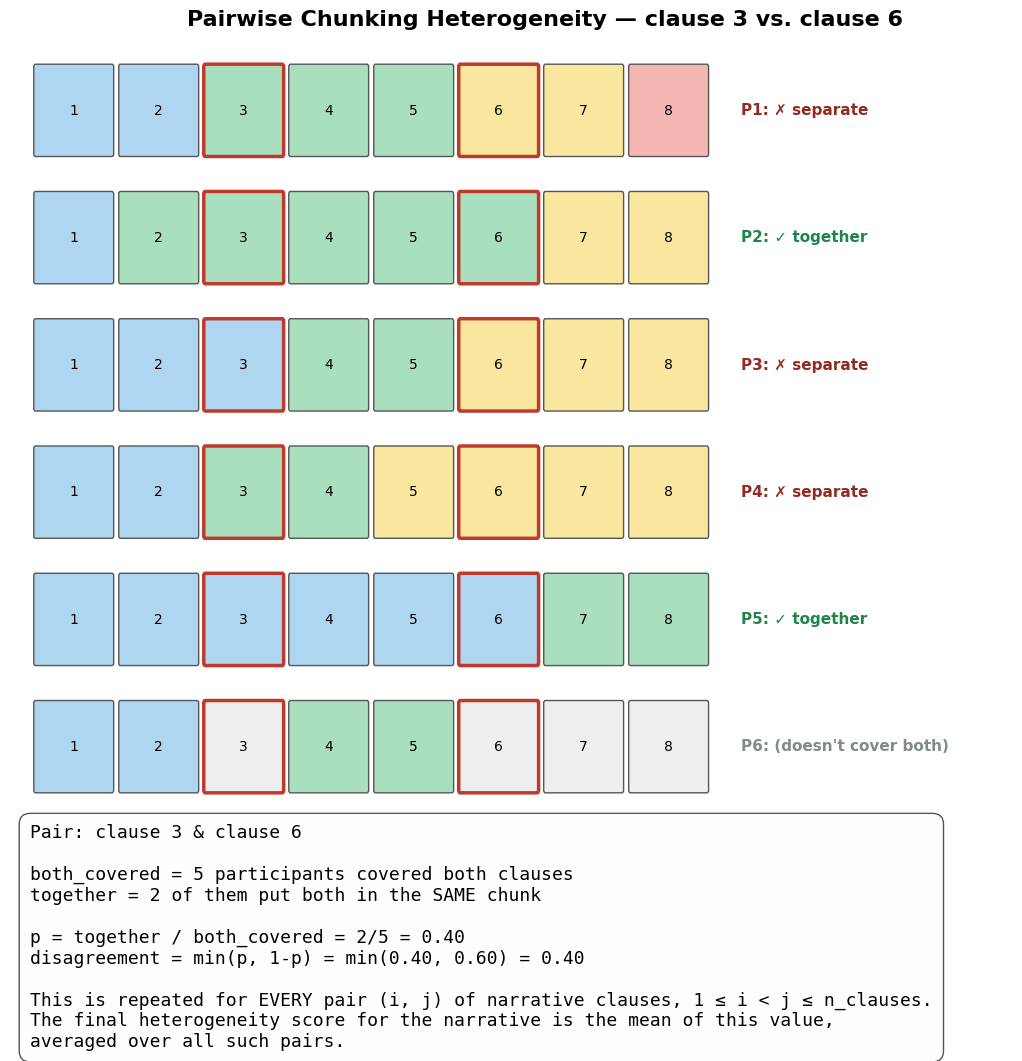

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── toy example: 8 narrative clauses, 6 participants, focus on clauses 3 & 6 ──
n_clauses = 8
clause_i, clause_j = 3, 6   # 1-indexed, the pair we're tracking

participant_chunks = [
    [[1, 2], [3, 4, 5], [6, 7], [8]],        # P1: i and j in different chunks
    [[1], [2, 3, 4, 5, 6], [7, 8]],          # P2: i and j together
    [[1, 2, 3], [4, 5], [6, 7, 8]],          # P3: i and j in different chunks
    [[1, 2], [3, 4], [5, 6, 7, 8]],          # P4: i and j in different chunks
    [[1, 2, 3, 4, 5, 6], [7, 8]],            # P5: i and j together
    [[1, 2], [4, 5]],                        # P6: didn't cover clause 3 or 6 at all (excluded)
]

chunk_palette = ["#aed6f1", "#a9dfbf", "#f9e79f", "#f5b7b1", "#d7bde2", "#f5cba7"]

fig, axes = plt.subplots(len(participant_chunks) + 1, 1, figsize=(11, 11),
                          gridspec_kw={"height_ratios": [1] * len(participant_chunks) + [1.9]})

box_w, box_h = 0.9, 0.7

together_count = 0
both_covered_count = 0

for row, (ax, chunks) in enumerate(zip(axes[:-1], participant_chunks)):
    clause_to_chunk = {}
    for c_idx, chunk in enumerate(chunks):
        for clause in chunk:
            clause_to_chunk[clause] = c_idx

    covers_i = clause_i in clause_to_chunk
    covers_j = clause_j in clause_to_chunk

    for clause in range(1, n_clauses + 1):
        x = clause - 1
        if clause in clause_to_chunk:
            color = chunk_palette[clause_to_chunk[clause] % len(chunk_palette)]
        else:
            color = "#eeeeee"
        rect = mpatches.FancyBboxPatch((x, 0), box_w, box_h,
                                        boxstyle="round,pad=0.02", linewidth=1.0,
                                        edgecolor="#555555", facecolor=color, zorder=2)
        ax.add_patch(rect)
        ax.text(x + box_w / 2, box_h / 2, str(clause), ha="center", va="center",
                fontsize=10, zorder=3)

        if clause in (clause_i, clause_j):
            highlight = mpatches.FancyBboxPatch((x, 0), box_w, box_h,
                                                 boxstyle="round,pad=0.02", linewidth=2.5,
                                                 edgecolor="#c0392b", facecolor="none", zorder=4)
            ax.add_patch(highlight)

    if covers_i and covers_j:
        both_covered_count += 1
        same = clause_to_chunk[clause_i] == clause_to_chunk[clause_j]
        if same:
            together_count += 1
            outcome = "✓ together"
            outcome_color = "#1e8449"
        else:
            outcome = "✗ separate"
            outcome_color = "#922b21"
    else:
        outcome = "(doesn't cover both)"
        outcome_color = "#7f8c8d"

    ax.text(n_clauses + 0.3, box_h / 2, f"P{row+1}: {outcome}",
            ha="left", va="center", fontsize=11, color=outcome_color, fontweight="bold")

    ax.set_xlim(-0.3, n_clauses + 3.5)
    ax.set_ylim(-0.1, box_h + 0.1)
    ax.axis("off")

# ── summary panel: p and disagreement calculation ────────────────────────────
ax_summary = axes[-1]
ax_summary.axis("off")

p = together_count / both_covered_count if both_covered_count else float("nan")
disagreement = min(p, 1 - p) if both_covered_count else float("nan")

summary_text = (
    f"Pair: clause {clause_i} & clause {clause_j}\n\n"
    f"both_covered = {both_covered_count} participants covered both clauses\n"
    f"together = {together_count} of them put both in the SAME chunk\n\n"
    f"p = together / both_covered = {together_count}/{both_covered_count} = {p:.2f}\n"
    f"disagreement = min(p, 1-p) = min({p:.2f}, {1-p:.2f}) = {disagreement:.2f}\n\n"
    f"This is repeated for EVERY pair (i, j) of narrative clauses, 1 ≤ i < j ≤ n_clauses.\n"
    f"The final heterogeneity score for the narrative is the mean of this value,\n"
    f"averaged over all such pairs."
)
ax_summary.text(0.02, 0.97, summary_text, ha="left", va="top", fontsize=13,
                 family="monospace", transform=ax_summary.transAxes,
                 bbox=dict(boxstyle="round,pad=0.6", facecolor="#fdfefe", edgecolor="#555555"))

fig.suptitle(f"Pairwise Chunking Heterogeneity — clause {clause_i} vs. clause {clause_j}",
             fontsize=16, fontweight="bold", y=0.995)

plt.tight_layout()
plt.savefig("pairwise_chunking_heterogeneity_illustration.png", dpi=150, bbox_inches="tight")
plt.show()



In [15]:
import numpy as np
from itertools import combinations

def compute_chunking_heterogeneity(story_dicts, n_clauses, only_candidate_pairs=True):
    participant_groupings = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        covered = set()
        same_chunk = {}
        for recall_idx, narrative_indices in clause_dict.items():
            for n in narrative_indices:
                if 1 <= n <= n_clauses:
                    covered.add(n)
                    same_chunk[n] = recall_idx
        participant_groupings.append((covered, same_chunk))

    pair_disagreements = []
    for i, j in combinations(range(1, n_clauses + 1), 2):
        together = 0
        both_covered = 0
        for covered, same_chunk in participant_groupings:
            if i in covered and j in covered:
                both_covered += 1
                if same_chunk[i] == same_chunk[j]:
                    together += 1
        if both_covered < 2:
            continue
        if only_candidate_pairs and together == 0:
            continue   # skip pairs nobody ever actually chunked together

        p = together / both_covered
        disagreement = 2 * min(p, 1 - p)   # 0 = full agreement, 1 = 50/50 split
        pair_disagreements.append(disagreement)

    return np.mean(pair_disagreements) if pair_disagreements else np.nan


heterogeneity_per_story = []
for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    h = compute_chunking_heterogeneity(clause_dicts_all[story_index], n_clauses)
    heterogeneity_per_story.append(h)
    print(f"Story {story_index+1}: chunking heterogeneity = {h:.3f}")


Story 1: chunking heterogeneity = 0.289
Story 2: chunking heterogeneity = 0.257
Story 3: chunking heterogeneity = 0.177
Story 4: chunking heterogeneity = 0.276
Story 5: chunking heterogeneity = 0.290
Story 6: chunking heterogeneity = 0.292
Story 7: chunking heterogeneity = 0.323
Story 8: chunking heterogeneity = 0.281
Story 9: chunking heterogeneity = 0.402
Story 10: chunking heterogeneity = 0.436
Story 11: chunking heterogeneity = 0.396
Story 12: chunking heterogeneity = 0.342


In [46]:
import numpy as np
import pandas as pd
from itertools import combinations

def compute_chunking_heterogeneity(story_dicts, n_clauses, only_candidate_pairs=True):
    """Return (mean heterogeneity, per-pair details DataFrame, number of participants)."""
    participant_groupings = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        covered = set()
        same_chunk = {}
        for recall_idx, narrative_indices in clause_dict.items():
            for n in narrative_indices:
                if 1 <= n <= n_clauses:
                    covered.add(n)
                    same_chunk[n] = recall_idx
        participant_groupings.append((covered, same_chunk))

    rows = []
    pair_disagreements = []
    for i, j in combinations(range(1, n_clauses + 1), 2):
        together = 0
        both_covered = 0
        for covered, same_chunk in participant_groupings:
            if i in covered and j in covered:
                both_covered += 1
                if same_chunk[i] == same_chunk[j]:
                    together += 1

        included = both_covered >= 2 and not (only_candidate_pairs and together == 0)
        disagreement = np.nan
        if included:
            p = together / both_covered
            disagreement = 2 * min(p, 1 - p)   # 0 = full agreement, 1 = 50/50 split
            pair_disagreements.append(disagreement)

        rows.append({'clause_i': i, 'clause_j': j,
                     'n_participants_both_recalled': both_covered,
                     'n_participants_chunked_together': together,
                     'included': included,
                     'disagreement': disagreement})

    h = np.mean(pair_disagreements) if pair_disagreements else np.nan
    return h, pd.DataFrame(rows), len(participant_groupings)


heterogeneity_per_story = []
pair_tables = []
summary_rows = []

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    h, pairs_df, n_participants = compute_chunking_heterogeneity(
        clause_dicts_all[story_index], n_clauses)
    heterogeneity_per_story.append(h)

    pairs_df.insert(0, 'story', story_index + 1)
    pair_tables.append(pairs_df)

    total_pairs   = len(pairs_df)                                   # = n(n-1)/2
    covered2      = pairs_df[pairs_df['n_participants_both_recalled'] >= 2]
    included      = pairs_df[pairs_df['included']]
    per_pair_n    = included['n_participants_both_recalled']

    summary_rows.append({
        'story':                    story_index + 1,
        'n_clauses':                n_clauses,
        'n_participants':           n_participants,
        'total_clause_pairs':       total_pairs,
        'pairs_>=2_participants':   len(covered2),
        'pairs_included':           len(included),
        'participants_per_pair_min':    per_pair_n.min()    if len(per_pair_n) else np.nan,
        'participants_per_pair_median': per_pair_n.median() if len(per_pair_n) else np.nan,
        'participants_per_pair_mean':   per_pair_n.mean()   if len(per_pair_n) else np.nan,
        'participants_per_pair_max':    per_pair_n.max()    if len(per_pair_n) else np.nan,
        'heterogeneity':            h,
    })

    print(f"Story {story_index+1}: {n_clauses} clauses, {n_participants} participants | "
          f"total pairs = {total_pairs}, pairs with >=2 participants = {len(covered2)}, "
          f"included pairs = {len(included)} | participants per included pair: "
          f"min {per_pair_n.min() if len(per_pair_n) else 'NA'}, "
          f"median {per_pair_n.median() if len(per_pair_n) else 'NA'}, "
          f"max {per_pair_n.max() if len(per_pair_n) else 'NA'} | "
          f"heterogeneity = {h:.3f}")

summary_df = pd.DataFrame(summary_rows)
all_pairs_df = pd.concat(pair_tables, ignore_index=True)

summary_df.to_csv('clause_pair_summary.csv', index=False)
all_pairs_df.to_csv('clause_pair_details.csv', index=False)

print()
print(summary_df.round(2).to_string(index=False))


Story 1: 19 clauses, 99 participants | total pairs = 171, pairs with >=2 participants = 171, included pairs = 88 | participants per included pair: min 17, median 53.0, max 75 | heterogeneity = 0.289
Story 2: 18 clauses, 56 participants | total pairs = 153, pairs with >=2 participants = 153, included pairs = 105 | participants per included pair: min 5, median 19.0, max 51 | heterogeneity = 0.257
Story 3: 18 clauses, 100 participants | total pairs = 153, pairs with >=2 participants = 153, included pairs = 105 | participants per included pair: min 9, median 46.0, max 82 | heterogeneity = 0.177
Story 4: 32 clauses, 100 participants | total pairs = 496, pairs with >=2 participants = 496, included pairs = 120 | participants per included pair: min 10, median 37.0, max 96 | heterogeneity = 0.276
Story 5: 32 clauses, 101 participants | total pairs = 496, pairs with >=2 participants = 496, included pairs = 181 | participants per included pair: min 6, median 26.0, max 83 | heterogeneity = 0.290
S

Story 1: observed rate = 0.144, baseline rate = 0.439 [0.432, 0.446], p = 0.0010
Story 2: observed rate = 0.128, baseline rate = 0.400 [0.388, 0.413], p = 0.0010
Story 3: observed rate = 0.089, baseline rate = 0.437 [0.428, 0.445], p = 0.0010
Story 4: observed rate = 0.138, baseline rate = 0.421 [0.415, 0.426], p = 0.0010
Story 5: observed rate = 0.145, baseline rate = 0.418 [0.412, 0.423], p = 0.0010
Story 6: observed rate = 0.146, baseline rate = 0.407 [0.404, 0.411], p = 0.0010
Story 7: observed rate = 0.161, baseline rate = 0.392 [0.387, 0.397], p = 0.0010
Story 8: observed rate = 0.141, baseline rate = 0.402 [0.398, 0.405], p = 0.0010
Story 9: observed rate = 0.201, baseline rate = 0.356 [0.353, 0.359], p = 0.0010
Story 10: observed rate = 0.218, baseline rate = 0.375 [0.373, 0.378], p = 0.0010
Story 11: observed rate = 0.198, baseline rate = 0.335 [0.332, 0.338], p = 0.0010
Story 12: observed rate = 0.171, baseline rate = 0.379 [0.376, 0.383], p = 0.0010

Total disagreement rate 

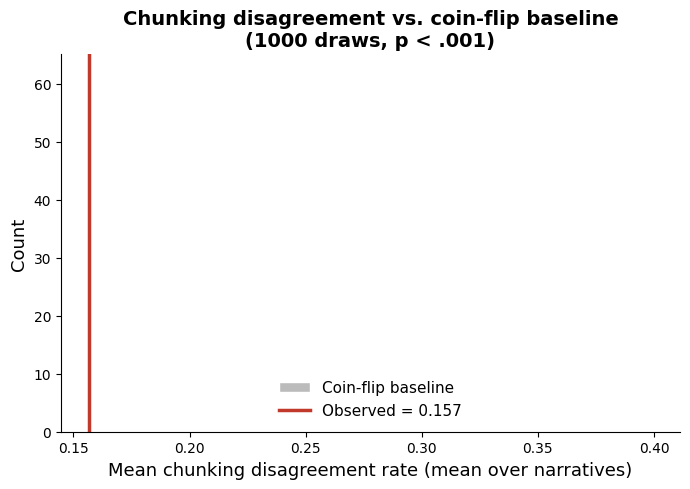

In [55]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

n_perm               = 1000      # random baselines per narrative
p_together_null      = 0.5       # chance that a participant puts a pair together (0.5 = even split)
only_candidate_pairs = True      # same filter as the observed analysis

# ── participant chunk labels: {clause (1-based): chunk id}, as in the original code ──
def participant_labels(story_dicts, n_clauses):
    labels = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        same_chunk = {}
        for recall_idx, narrative_indices in clause_dict.items():
            for n in narrative_indices:
                if 1 <= n <= n_clauses:
                    same_chunk[n] = recall_idx
        labels.append(same_chunk)
    return labels

# ── per-pair counts: b = recalled both, t = chunked together ──────────────────
def pair_counts(label_list, n_clauses):
    P = len(label_list)
    covered = np.zeros((P, n_clauses), dtype=np.int32)
    cols = []
    for p, lab in enumerate(label_list):
        by_chunk = {}
        for clause, chunk in lab.items():
            covered[p, clause - 1] = 1
            by_chunk.setdefault(chunk, []).append(clause - 1)
        for members in by_chunk.values():
            col = np.zeros(n_clauses, dtype=np.int32)
            col[members] = 1
            cols.append(col)
    M = np.stack(cols, axis=1) if cols else np.zeros((n_clauses, 1), dtype=np.int32)
    iu = np.triu_indices(n_clauses, k=1)
    return (covered.T @ covered)[iu], (M @ M.T)[iu]

def heterogeneity(b, t):
    mask = b >= 2
    if only_candidate_pairs:
        mask &= t > 0
    if not mask.any():
        return np.nan, 0, np.array([])
    p = t[mask] / b[mask]
    dis = 2 * np.minimum(p, 1 - p)                # 0 = full agreement, 1 = 50/50 split
    return dis.mean(), int(mask.sum()), dis

# ── observed + coin-flip baseline, per narrative ─────────────────────────────
n_stories = 12
obs_h     = np.full(n_stories, np.nan)
obs_pairs = np.zeros(n_stories, dtype=int)
obs_dis   = []
null_h    = np.full((n_perm, n_stories), np.nan)
null_dis_pooled = [[] for _ in range(n_perm)]
summary_rows = []

for s in range(n_stories):
    n_clauses = len(story_processed_all[s])
    labels    = participant_labels(clause_dicts_all[s], n_clauses)
    b, t      = pair_counts(labels, n_clauses)

    obs_h[s], obs_pairs[s], dis = heterogeneity(b, t)
    obs_dis.append(dis)

    eligible = b >= 2                              # pairs that can enter the score at all
    b_el     = b[eligible]
    for k in range(n_perm):
        t_null = rng.binomial(b_el, p_together_null)
        null_h[k, s], _, nd = heterogeneity(b_el, t_null)
        null_dis_pooled[k].append(nd)

    nh = null_h[:, s]
    p_low = (np.sum(nh <= obs_h[s]) + 1) / (np.sum(~np.isnan(nh)) + 1)
    summary_rows.append({
        'story': s + 1, 'n_clauses': n_clauses, 'n_participants': len(labels),
        'total_clause_pairs': n_clauses * (n_clauses - 1) // 2,
        'pairs_included': obs_pairs[s],
        'observed_rate': obs_h[s] / 2,
        'baseline_rate_mean': np.nanmean(nh) / 2,
        'baseline_rate_ci_low': np.nanpercentile(nh, 2.5) / 2,
        'baseline_rate_ci_high': np.nanpercentile(nh, 97.5) / 2,
        'p_lower_than_baseline': p_low,
    })
    print(f"Story {s+1}: observed rate = {obs_h[s]/2:.3f}, baseline rate = {np.nanmean(nh)/2:.3f} "
          f"[{np.nanpercentile(nh, 2.5)/2:.3f}, {np.nanpercentile(nh, 97.5)/2:.3f}], p = {p_low:.4f}")

# ── total: mean over narratives ──────────────────────────────────────────────
obs_total_mean  = np.nanmean(obs_h)
null_total_mean = np.nanmean(null_h, axis=1)
p_total_mean    = (np.sum(null_total_mean <= obs_total_mean) + 1) / (n_perm + 1)

obs_total_pooled  = np.concatenate(obs_dis).mean()
null_total_pooled = np.array([np.concatenate(d).mean() for d in null_dis_pooled])
p_total_pooled    = (np.sum(null_total_pooled <= obs_total_pooled) + 1) / (n_perm + 1)

print(f"\nTotal disagreement rate (mean over narratives): observed = {obs_total_mean/2:.3f}, "
      f"baseline = {null_total_mean.mean()/2:.3f}, p = {p_total_mean:.4f}")
print(f"Total disagreement rate (pooled over pairs):     observed = {obs_total_pooled/2:.3f}, "
      f"baseline = {null_total_pooled.mean()/2:.3f}, p = {p_total_pooled:.4f}")

summary_df = pd.DataFrame(summary_rows)
print()
print(summary_df.round(3).to_string(index=False))

# ── save (separate files, so the earlier shuffle baseline is kept) ───────────
np.savez_compressed('heterogeneity_coinflip_baseline_arrays.npz',
                    null_h=null_h, obs_h=obs_h, obs_pairs=obs_pairs,
                    null_total_mean=null_total_mean, null_total_pooled=null_total_pooled)
with open('heterogeneity_coinflip_baseline_meta.json', 'w', encoding='utf-8') as f:
    json.dump({'baseline': 'coin-flip per pair, t ~ Binomial(b, p)',
               'p_together_null': p_together_null, 'n_perm': n_perm,
               'only_candidate_pairs': only_candidate_pairs, 'random_seed': 0,
               'obs_total_mean': float(obs_total_mean), 'p_total_mean': float(p_total_mean),
               'obs_total_pooled': float(obs_total_pooled), 'p_total_pooled': float(p_total_pooled)},
              f, indent=1)
summary_df.to_csv('heterogeneity_coinflip_baseline.csv', index=False)

# ── plot: baseline distribution of the total vs. observed (disagreement rate) ─
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(null_total_mean / 2, bins=40, color='#bbbbbb', edgecolor='white',
        label='Coin-flip baseline')
ax.axvline(obs_total_mean / 2, color='#c0392b', lw=2.5,
           label=f'Observed = {obs_total_mean/2:.3f}')
p_txt = "p < .001" if p_total_mean < 0.001 else f"p = {p_total_mean:.3f}"
ax.set_title(f"Chunking disagreement vs. coin-flip baseline\n({n_perm} draws, {p_txt})",
             fontsize=14, fontweight='bold')
ax.set_xlabel("Mean chunking disagreement rate (mean over narratives)", fontsize=13)
ax.set_ylabel("Count", fontsize=13)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=11, frameon=False)
plt.tight_layout()
plt.savefig("heterogeneity_coinflip_baseline.png", dpi=150, bbox_inches='tight')
plt.show()


In [56]:
import json
import numpy as np
import pandas as pd

# ── 1. numeric arrays (compressed NumPy archive) ─────────────────────────────
np.savez_compressed(
    'heterogeneity_baseline_arrays.npz',
    null_h            = null_h,              # (n_perm, n_stories) baseline heterogeneity per permutation
    obs_h             = obs_h,               # (n_stories,) observed heterogeneity
    obs_pairs         = obs_pairs,           # (n_stories,) number of included pairs (observed)
    null_total_mean   = null_total_mean,     # (n_perm,) baseline total, mean over narratives
    null_total_pooled = null_total_pooled,   # (n_perm,) baseline total, pooled over all pairs
)

# ── 2. settings, totals and observed per-pair disagreement (JSON) ────────────
meta = {
    'n_perm':               n_perm,
    'null_mode':            null_mode,
    'only_candidate_pairs': only_candidate_pairs,
    'random_seed':          0,
    'n_stories':            n_stories,
    'obs_total_mean':       float(obs_total_mean),
    'p_total_mean':         float(p_total_mean),
    'obs_total_pooled':     float(obs_total_pooled),
    'p_total_pooled':       float(p_total_pooled),
    # observed disagreement of every included pair, per narrative (lengths differ)
    'obs_pair_disagreement': [[float(v) for v in d] for d in obs_dis],
}
with open('heterogeneity_baseline_meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=1)

# ── 3. per-narrative summary table (CSV) ─────────────────────────────────────
summary_df.to_csv('heterogeneity_random_baseline.csv', index=False)

print("Saved: heterogeneity_baseline_arrays.npz, heterogeneity_baseline_meta.json, "
      "heterogeneity_random_baseline.csv")

Saved: heterogeneity_baseline_arrays.npz, heterogeneity_baseline_meta.json, heterogeneity_random_baseline.csv


In [33]:
import json
import numpy as np
import pandas as pd

# ── 1. numeric arrays ────────────────────────────────────────────────────────
arrs = np.load('heterogeneity_baseline_arrays.npz')
null_h            = arrs['null_h']              # (n_perm, n_stories)
obs_h             = arrs['obs_h']               # (n_stories,)
obs_pairs         = arrs['obs_pairs']           # (n_stories,)
null_total_mean   = arrs['null_total_mean']     # (n_perm,)
null_total_pooled = arrs['null_total_pooled']   # (n_perm,)

# ── 2. settings, totals, observed per-pair disagreement ──────────────────────
with open('heterogeneity_baseline_meta.json', encoding='utf-8') as f:
    meta = json.load(f)

n_perm               = meta['n_perm']
null_mode            = meta['null_mode']
only_candidate_pairs = meta['only_candidate_pairs']
n_stories            = meta['n_stories']
obs_total_mean       = meta['obs_total_mean']
p_total_mean         = meta['p_total_mean']
obs_total_pooled     = meta['obs_total_pooled']
p_total_pooled       = meta['p_total_pooled']
obs_dis              = [np.array(d) for d in meta['obs_pair_disagreement']]

# ── 3. per-narrative summary table ───────────────────────────────────────────
summary_df = pd.read_csv('heterogeneity_random_baseline.csv')

# observed heterogeneity under the name the plotting scripts use
heterogeneity_per_story = list(obs_h)

# ── quick check ──────────────────────────────────────────────────────────────
assert null_h.shape == (n_perm, n_stories), null_h.shape
assert len(obs_dis) == n_stories
print(f"Loaded: {n_perm} permutations x {n_stories} narratives "
      f"(null_mode = {null_mode}, only_candidate_pairs = {only_candidate_pairs})")
print(f"Total (mean over narratives): observed = {obs_total_mean:.3f}, "
      f"baseline = {null_total_mean.mean():.3f}, p = {p_total_mean:.4f}")
print(f"Total (pooled over pairs):     observed = {obs_total_pooled:.3f}, "
      f"baseline = {null_total_pooled.mean():.3f}, p = {p_total_pooled:.4f}")
print()
print(summary_df.round(3).to_string(index=False))


Loaded: 1000 permutations x 12 narratives (null_mode = shuffle, only_candidate_pairs = True)
Total (mean over narratives): observed = 0.313, baseline = 0.793, p = 0.0010
Total (pooled over pairs):     observed = 0.360, baseline = 0.731, p = 0.0010

 story  n_clauses  n_participants  total_clause_pairs  pairs_included  observed_rate  baseline_rate_mean  baseline_rate_ci_low  baseline_rate_ci_high  p_lower_than_baseline
     1         19              99                 171              88          0.144               0.439                 0.432                  0.446                  0.001
     2         18              56                 153             105          0.128               0.400                 0.388                  0.413                  0.001
     3         18             100                 153             105          0.089               0.437                 0.428                  0.445                  0.001
     4         32             100                 496      

Observed mean = 0.157, baseline mean = 0.397, permutation p = 0.0010


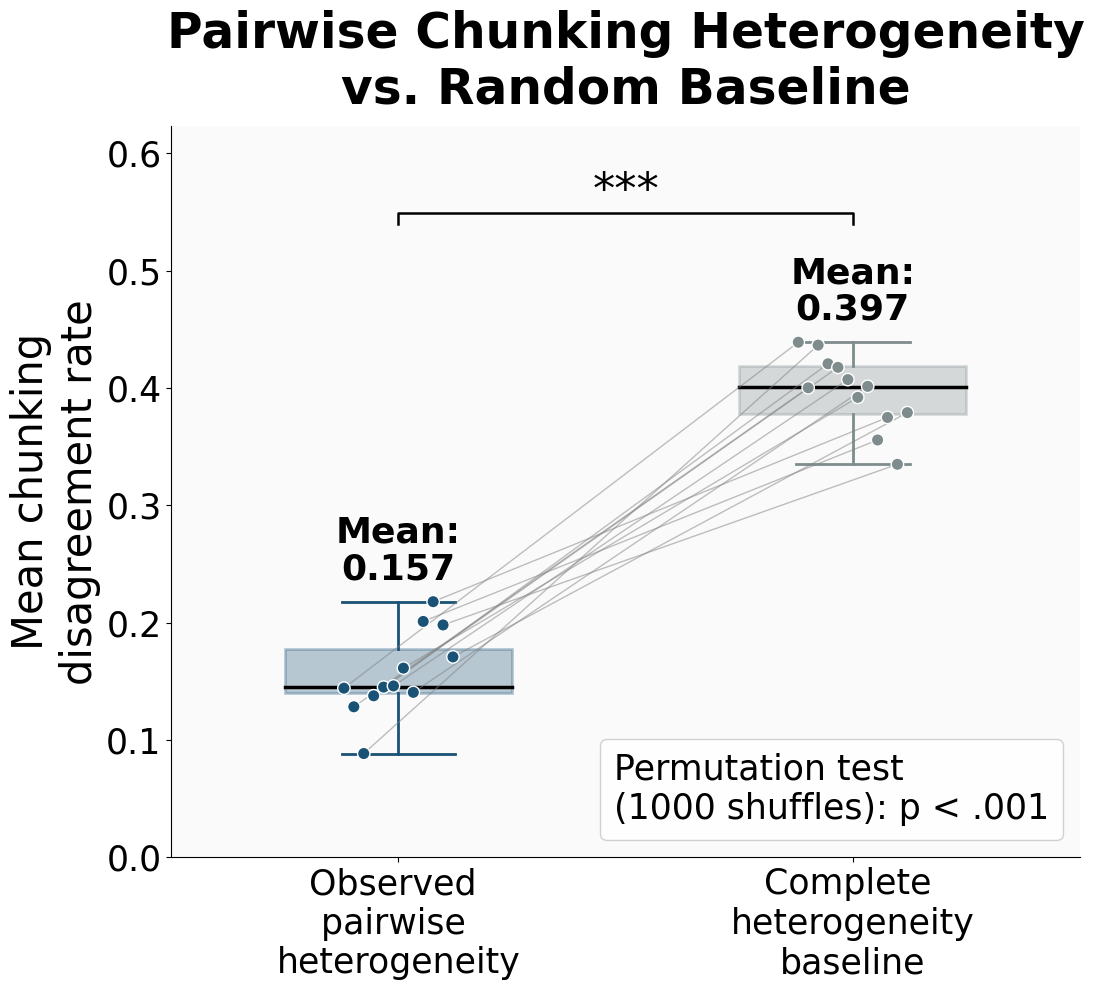

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis label 30, everything else >= 25 ───────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_mean, fs_legend, fs_star = 35, 30, 25, 25, 26, 25, 32

# observed disagreement rate = heterogeneity value / 2
observed = np.array([h / 2 for h in heterogeneity_per_story], dtype=float)

# random baseline from the permutation script (null_h: n_perm x n_stories heterogeneity)
null_rate   = null_h / 2
baseline    = np.nanmean(null_rate, axis=0)          # per-narrative baseline mean

# permutation test on the total (mean over narratives), one-sided: observed lower?
obs_total   = np.nanmean(observed)
null_totals = np.nanmean(null_rate, axis=1)
p_perm      = (np.sum(null_totals <= obs_total) + 1) / (len(null_totals) + 1)
n_perm_used = len(null_totals)
print(f"Observed mean = {obs_total:.3f}, baseline mean = {null_totals.mean():.3f}, "
      f"permutation p = {p_perm:.4f}")

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

p_text     = "p < .001" if p_perm < 0.001 else f"p = {p_perm:.3f}"
test_label = f"Permutation test\n({n_perm_used} shuffles): {p_text}"

names     = ["Observed \npairwise \nheterogeneity", "Complete \nheterogeneity\nbaseline"]
data      = [observed, baseline]
colors    = ['#1a5276', '#7f8c8d']
positions = np.arange(2)
n_stories = len(observed)

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 10))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box
y_max_all = max(np.nanmax(d) for d in data)
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.03 * y_max_all, f"Mean:\n{v.mean():.3f}",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6, linespacing=1.1)

# dots per narrative, connected between the two boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    if not np.isnan(ys).any():
        ax.plot(xs, ys, color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# significance bracket (permutation test)
yb, tick = y_max_all * 1.25, y_max_all * 0.02
ax.plot([0, 0, 1, 1], [yb - tick, yb, yb, yb - tick], color='black', lw=1.8, zorder=6)
ax.text(0.5, yb, add_stars(p_perm), ha='center', va='bottom', fontsize=fs_star, zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(names, fontsize=fs_xtick)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_ylabel("Mean chunking\ndisagreement rate", fontsize=fs_label)
ax.set_title("Pairwise Chunking Heterogeneity\nvs. Random Baseline",
             fontsize=fs_title, pad=16, fontweight='bold')
ax.set_ylim(0, y_max_all * 1.42)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[test_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig("chunking_heterogeneity_vs_baseline_boxplot.png", dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()



Ratio (observed / baseline) vs. length: slope = 0.00203, R² = 0.849, p < 0.001 ***
Mean ratio = 0.403
Difference (observed - baseline) vs. length: slope = 0.00108, R² = 0.856, p < 0.001 ***


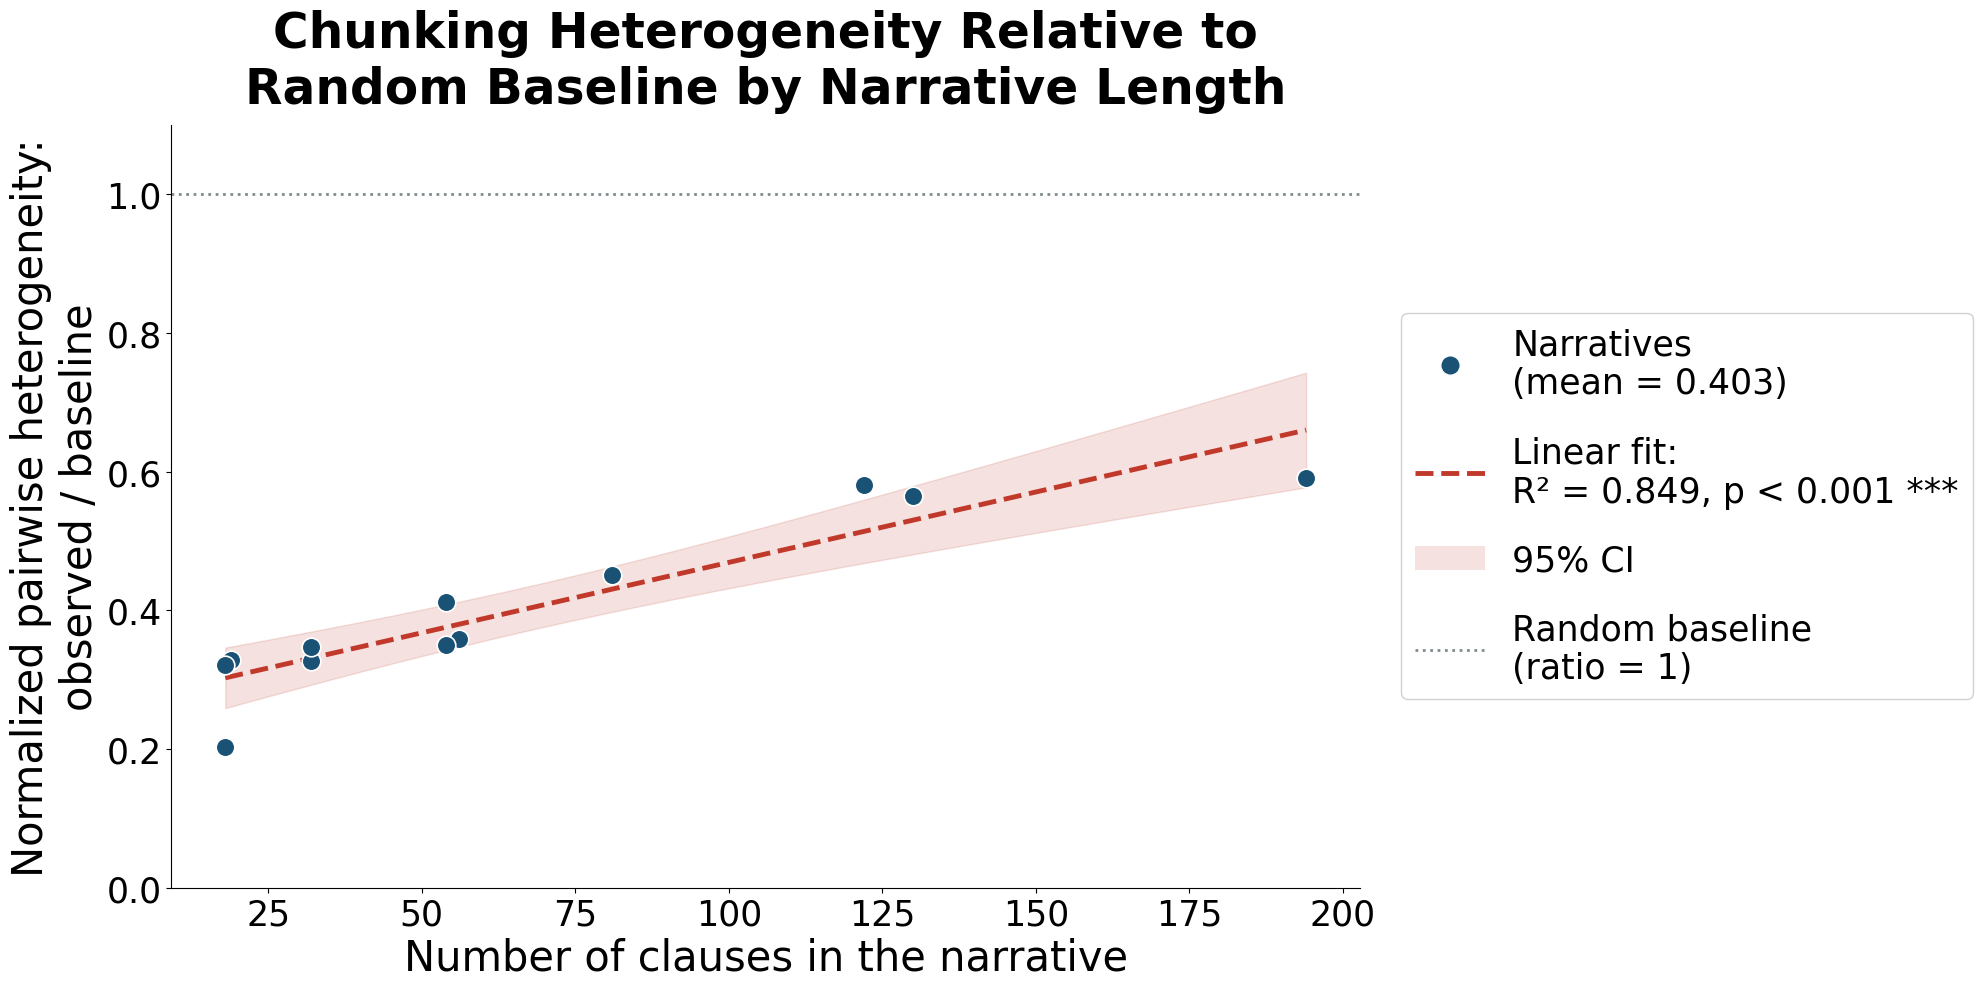

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_tick, fs_legend = 35, 30, 25, 25

story_lengths = np.array([len(story_processed_all[i]) for i in range(12)], dtype=float)

# observed disagreement rate = heterogeneity value / 2
observed = np.array([h / 2 for h in heterogeneity_per_story], dtype=float)

# coin-flip baseline from the baseline script (null_h: n_perm x n_stories heterogeneity)
baseline = np.nanmean(null_h / 2, axis=0)

# normalized net heterogeneity: 1 = as split as a 50/50 coin flip, 0 = full agreement
ratio = observed / baseline
diff  = observed - baseline          # kept for the robustness check below

def p_label_str(p):
    if p < 0.001:
        return "p < 0.001 ***"
    elif p < 0.01:
        return f"p = {p:.3f} **"
    elif p < 0.05:
        return f"p = {p:.3f} *"
    else:
        return f"p = {p:.3f}"

# ── linear regression of the ratio on narrative length ───────────────────────
model_fit = sm.OLS(ratio, sm.add_constant(story_lengths), missing='drop').fit()
slope     = model_fit.params[1]
p_value   = model_fit.pvalues[1]
r2        = model_fit.rsquared

x_reg = np.linspace(story_lengths.min(), story_lengths.max(), 200)
pred  = model_fit.get_prediction(sm.add_constant(x_reg)).summary_frame(alpha=0.05)

print(f"Ratio (observed / baseline) vs. length: slope = {slope:.5f}, R² = {r2:.3f}, "
      f"{p_label_str(p_value)}")
print(f"Mean ratio = {np.nanmean(ratio):.3f}")

# robustness: same regression on the plain difference
model_diff = sm.OLS(diff, sm.add_constant(story_lengths), missing='drop').fit()
print(f"Difference (observed - baseline) vs. length: slope = {model_diff.params[1]:.5f}, "
      f"R² = {model_diff.rsquared:.3f}, {p_label_str(model_diff.pvalues[1])}")

# ── plot (landscape) ──────────────────────────────────────────────────────────
dot_color, fit_color = '#1a5276', '#c0392b'
fig, ax = plt.subplots(figsize=(20, 10))

ax.axhline(1, color='#7f8c8d', lw=2, ls=':', zorder=1)          # = coin-flip baseline

ax.scatter(story_lengths, ratio, color=dot_color, s=180,
           edgecolor='white', linewidth=1.2, zorder=3)
ax.plot(x_reg, pred['mean'], '--', color=fit_color, lw=3.5, zorder=2)
ax.fill_between(x_reg, pred['mean_ci_lower'], pred['mean_ci_upper'],
                color=fit_color, alpha=0.15, zorder=1)

ax.set_xlabel("Number of clauses in the narrative", fontsize=fs_label)
ax.set_ylabel("Normalized pairwise heterogeneity:\nobserved / baseline", fontsize=fs_label)
ax.set_title("Chunking Heterogeneity Relative to\nRandom Baseline by Narrative Length",
             fontsize=fs_title, fontweight='bold', pad=16)
ax.set_ylim(0, max(1.1, np.nanmax(ratio) * 1.1))
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=fs_tick)

handles = [
    Line2D([0], [0], marker='o', color=dot_color, linestyle='none', markersize=14,
           markeredgecolor='white', label=f"Narratives\n(mean = {np.nanmean(ratio):.3f})"),
    Line2D([0], [0], color=fit_color, linestyle='--', lw=3.5,
           label=f"Linear fit:\nR² = {r2:.3f}, {p_label_str(p_value)}"),
    Patch(facecolor=fit_color, alpha=0.15, label="95% CI"),
    Line2D([0], [0], color='#7f8c8d', linestyle=':', lw=2,
           label="Random baseline\n(ratio = 1)"),
]
ax.legend(handles=handles, fontsize=fs_legend, loc='center left', bbox_to_anchor=(1.02, 0.5),
          frameon=True, framealpha=0.9, labelspacing=1.0)

plt.tight_layout()
plt.savefig("chunking_heterogeneity_ratio_by_length.png", dpi=150, bbox_inches='tight')
plt.show()



## 1.2. Pairwise heterogeneity distribution with clause pair similarity.

In [43]:
import numpy as np
from itertools import combinations
from scipy.spatial.distance import cosine
import matplotlib.pyplot as plt

def compute_pair_similarity_and_probability(story_dicts, n_clauses, narrative_embs, only_candidate_pairs=True):
    """
    Same pairwise qualifying logic as compute_chunking_heterogeneity, but instead
    of collapsing to a single disagreement score, returns the raw cosine similarity
    between each qualifying pair's narrative-clause embeddings, and the probability
    p (0-100%) that participants chunked them together.
    """
    participant_groupings = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        covered = set()
        same_chunk = {}
        for recall_idx, narrative_indices in clause_dict.items():
            for n in narrative_indices:
                if 1 <= n <= n_clauses:
                    covered.add(n)
                    same_chunk[n] = recall_idx
        participant_groupings.append((covered, same_chunk))

    cos_sims = []
    probabilities = []

    for i, j in combinations(range(1, n_clauses + 1), 2):
        together = 0
        both_covered = 0
        for covered, same_chunk in participant_groupings:
            if i in covered and j in covered:
                both_covered += 1
                if same_chunk[i] == same_chunk[j]:
                    together += 1
        if both_covered < 2:
            continue
        if only_candidate_pairs and together == 0:
            continue

        p = together / both_covered
        cos_sim = 1 - cosine(narrative_embs[i - 1], narrative_embs[j - 1])

        cos_sims.append(cos_sim)
        probabilities.append(p * 100)   # 0-100%

    return cos_sims, probabilities


all_cos_sims = []
all_probabilities = []

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    narrative_embs = story_emb_all[story_index]
    cos_sims, probs = compute_pair_similarity_and_probability(
        clause_dicts_all[story_index], n_clauses, narrative_embs
    )
    all_cos_sims.extend(cos_sims)
    all_probabilities.extend(probs)

print(f"Total qualifying pairs collected across all 12 stories: {len(all_cos_sims)}")


Total qualifying pairs collected across all 12 stories: 4173


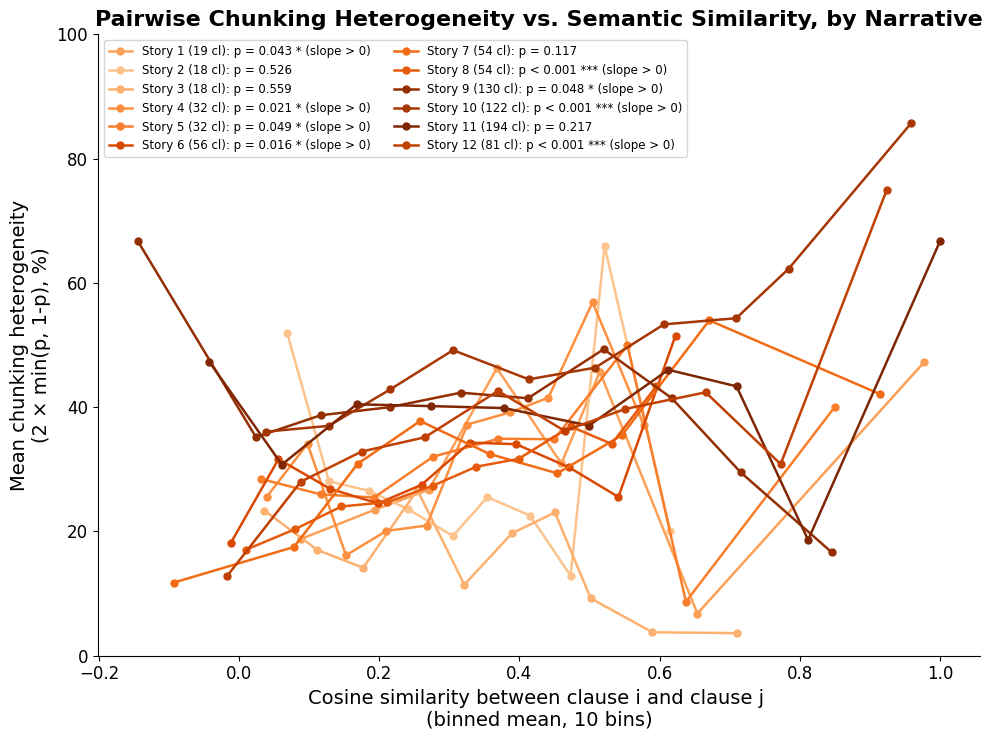

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib import cm

n_bins = 10

total_clauses_per_story = np.array([len(story_processed_all[i]) for i in range(12)])
length_rank = np.argsort(np.argsort(total_clauses_per_story))
orange_colors = cm.Oranges(np.linspace(0.3, 1.0, 12))

def p_label_str(p):
    if p < 0.001: return "p < 0.001 ***"
    elif p < 0.01: return f"p = {p:.3f} **"
    elif p < 0.05: return f"p = {p:.3f} *"
    else: return f"p = {p:.3f}"

fig, ax = plt.subplots(figsize=(10, 7.5))

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    narrative_embs = story_emb_all[story_index]
    cos_sims, probs = compute_pair_similarity_and_probability(
        clause_dicts_all[story_index], n_clauses, narrative_embs
    )

    if len(cos_sims) == 0:
        print(f"Story {story_index+1}: no qualifying pairs, skipped.")
        continue

    cos_sims = np.array(cos_sims)
    probs = np.array(probs)
    heterogeneity = 2 * np.minimum(probs, 100 - probs)   # 0-100%

    bin_edges = np.linspace(cos_sims.min(), cos_sims.max(), n_bins + 1)
    bin_indices = np.digitize(cos_sims, bin_edges) - 1
    bin_indices = np.clip(bin_indices, 0, n_bins - 1)

    bin_mean_x = []
    bin_mean_y = []

    for b in range(n_bins):
        mask = bin_indices == b
        if mask.sum() == 0:
            continue
        bin_mean_x.append(cos_sims[mask].mean())
        bin_mean_y.append(heterogeneity[mask].mean())

    color = orange_colors[length_rank[story_index]]

    # ── linear regression on the RAW (unbinned) per-pair heterogeneity, for p-value only ──
    if len(cos_sims) >= 3:
        X = sm.add_constant(cos_sims)
        model_fit = sm.OLS(heterogeneity, X).fit()
        slope = model_fit.params[1]
        p_value = model_fit.pvalues[1]
        p_str = p_label_str(p_value)
        if p_value < 0.05:
            p_str += f" (slope {'>' if slope > 0 else '<'} 0)"
    else:
        p_str = "p n/a (too few pairs)"

    ax.plot(bin_mean_x, bin_mean_y, marker="o", markersize=5, linewidth=1.8,
            color=color, label=f"Story {story_index+1} ({n_clauses} cl): {p_str}")

ax.set_ylim(0, 100)
ax.set_xlabel("Cosine similarity between clause i and clause j \n(binned mean, 10 bins)", fontsize=14)
ax.set_ylabel("Mean chunking heterogeneity\n(2 × min(p, 1-p), %)", fontsize=14)
ax.set_title("Pairwise Chunking Heterogeneity vs. Semantic Similarity, by Narrative", fontsize=16, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=12)
ax.legend(fontsize=8.5, ncol=2, loc="best")

plt.tight_layout()
plt.savefig("chunking_heterogeneity_vs_cosine_similarity_by_story.png", dpi=150, bbox_inches='tight')
plt.show()



Total/pooled fit over all 4173 pairs from 12 stories: slope=10.844, p < 0.001 ***
Leftmost bin  (x=-0.064, n=13): mean heterogeneity = 15.201
Rightmost bin (x=0.955, n=5): mean heterogeneity = 31.671


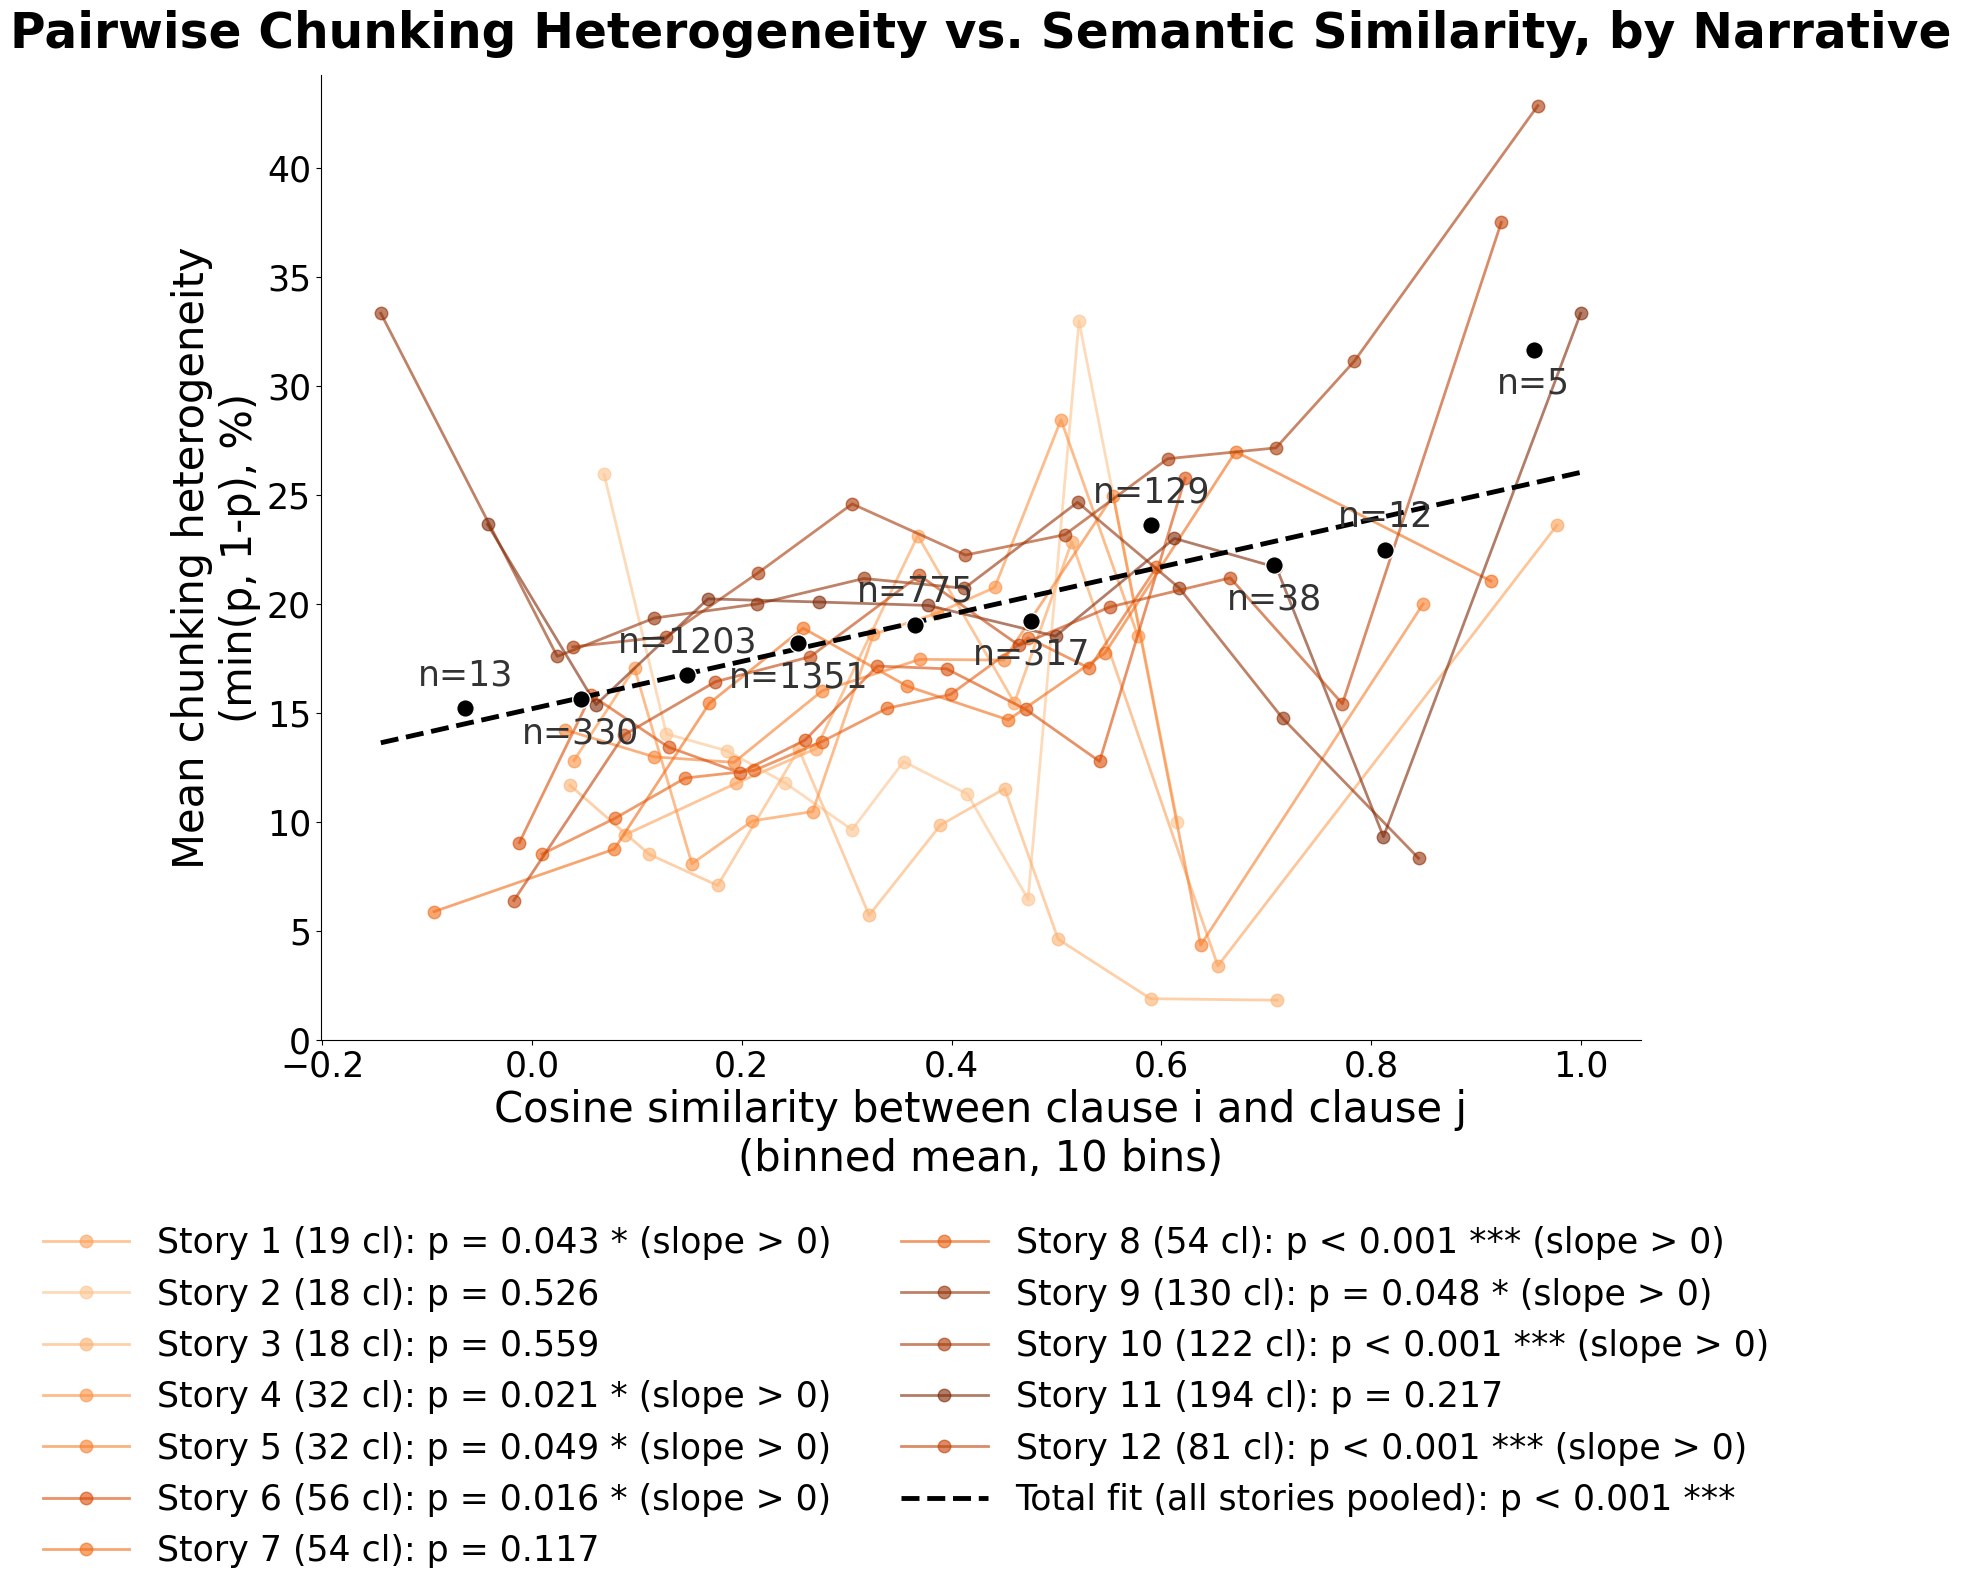

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib import cm

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_tick, fs_legend, fs_n = 35, 30, 25, 25, 25

n_bins = 10

total_clauses_per_story = np.array([len(story_processed_all[i]) for i in range(12)])
length_rank = np.argsort(np.argsort(total_clauses_per_story))
orange_colors = cm.Oranges(np.linspace(0.3, 1.0, 12))

def p_label_str(p):
    if p < 0.001: return "p < 0.001 ***"
    elif p < 0.01: return f"p = {p:.3f} **"
    elif p < 0.05: return f"p = {p:.3f} *"
    else: return f"p = {p:.3f}"

# ── compute everything per story, pool ALL pairs across stories ─────────────
story_entries = []
pooled_cos_sims_all = []
pooled_heterogeneity_all = []

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    narrative_embs = story_emb_all[story_index]
    cos_sims, probs = compute_pair_similarity_and_probability(
        clause_dicts_all[story_index], n_clauses, narrative_embs
    )

    if len(cos_sims) == 0:
        print(f"Story {story_index+1}: no qualifying pairs, skipped.")
        continue

    cos_sims = np.array(cos_sims)
    probs = np.array(probs)
    heterogeneity = np.minimum(probs, 100 - probs)   # 0-50%

    bin_edges = np.linspace(cos_sims.min(), cos_sims.max(), n_bins + 1)
    bin_indices = np.clip(np.digitize(cos_sims, bin_edges) - 1, 0, n_bins - 1)

    bin_mean_x, bin_mean_y = [], []
    for b in range(n_bins):
        mask = bin_indices == b
        if mask.sum() == 0:
            continue
        bin_mean_x.append(cos_sims[mask].mean())
        bin_mean_y.append(heterogeneity[mask].mean())

    color = orange_colors[length_rank[story_index]]

    if len(cos_sims) >= 3:
        X = sm.add_constant(cos_sims)
        model_fit = sm.OLS(heterogeneity, X).fit()
        slope = model_fit.params[1]
        p_value = model_fit.pvalues[1]
        p_str = p_label_str(p_value)
        if p_value < 0.05:
            p_str += f" (slope {'>' if slope > 0 else '<'} 0)"
    else:
        p_str = "p n/a (too few pairs)"

    story_entries.append({
        "story_index": story_index,
        "n_clauses": n_clauses,
        "bin_mean_x": bin_mean_x,
        "bin_mean_y": bin_mean_y,
        "p_str": p_str,
        "color": color,
    })

    pooled_cos_sims_all.extend(cos_sims.tolist())
    pooled_heterogeneity_all.extend(heterogeneity.tolist())

pooled_cos_sims_all = np.array(pooled_cos_sims_all)
pooled_heterogeneity_all = np.array(pooled_heterogeneity_all)

# ── total/pooled regression + re-binned points, over ALL pairs from ALL stories ──
pooled_bin_edges = np.linspace(pooled_cos_sims_all.min(), pooled_cos_sims_all.max(), n_bins + 1)
pooled_bin_indices = np.clip(np.digitize(pooled_cos_sims_all, pooled_bin_edges) - 1, 0, n_bins - 1)

pooled_bin_mean_x, pooled_bin_mean_y, pooled_bin_n = [], [], []
for b in range(n_bins):
    mask = pooled_bin_indices == b
    if mask.sum() == 0:
        continue
    pooled_bin_mean_x.append(pooled_cos_sims_all[mask].mean())
    pooled_bin_mean_y.append(pooled_heterogeneity_all[mask].mean())
    pooled_bin_n.append(mask.sum())

X_pooled = sm.add_constant(pooled_cos_sims_all)
pooled_fit = sm.OLS(pooled_heterogeneity_all, X_pooled).fit()
pooled_slope = pooled_fit.params[1]
pooled_p = pooled_fit.pvalues[1]

x_fit = np.linspace(pooled_cos_sims_all.min(), pooled_cos_sims_all.max(), 100)
y_fit = pooled_fit.params[0] + pooled_slope * x_fit

print(f"Total/pooled fit over all {len(pooled_cos_sims_all)} pairs from {len(story_entries)} stories: "
      f"slope={pooled_slope:.3f}, {p_label_str(pooled_p)}")
print(f"Leftmost bin  (x={pooled_bin_mean_x[0]:.3f}, n={pooled_bin_n[0]}): mean heterogeneity = {pooled_bin_mean_y[0]:.3f}")
print(f"Rightmost bin (x={pooled_bin_mean_x[-1]:.3f}, n={pooled_bin_n[-1]}): mean heterogeneity = {pooled_bin_mean_y[-1]:.3f}")

# ── plot: one figure, all story curves together + pooled fit ────────────────
fig, ax = plt.subplots(figsize=(15, 12))

for entry in story_entries:
    ax.plot(entry["bin_mean_x"], entry["bin_mean_y"], marker="o", markersize=9, linewidth=2,
            color=entry["color"], alpha=0.6,
            label=f"Story {entry['story_index']+1} ({entry['n_clauses']} cl): {entry['p_str']}")

# pooled, re-binned points + regression line
ax.scatter(pooled_bin_mean_x, pooled_bin_mean_y, s=160, color="black", zorder=5,
           edgecolor="white", linewidth=1)
for k, (x, y, n) in enumerate(zip(pooled_bin_mean_x, pooled_bin_mean_y, pooled_bin_n)):
    above = (k % 2 == 0)                          # alternate above / below
    ax.annotate(f"n={n}", (x, y), textcoords="offset points",
                xytext=(0, 12 if above else -12), va='bottom' if above else 'top',
                fontsize=fs_n, ha="center", color="#333333", zorder=6)

ax.plot(x_fit, y_fit, '--', linewidth=3.5, color="black", zorder=4,
        label=f"Total fit (all stories pooled): {p_label_str(pooled_p)}")

ax.set_xlabel("Cosine similarity between clause i and clause j\n(binned mean, 10 bins)",
              fontsize=fs_label)
ax.set_ylabel("Mean chunking heterogeneity\n(min(p, 1-p), %)", fontsize=fs_label)

# adapt y-axis to the data range (extra padding for the n= labels)
all_y_vals = np.concatenate([entry["bin_mean_y"] for entry in story_entries] + [pooled_bin_mean_y])
y_min, y_max = all_y_vals.min(), all_y_vals.max()
y_pad = (y_max - y_min) * 0.18
ax.set_ylim(max(0, y_min - y_pad), y_max + y_pad - 6)

ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=fs_tick)

ax.set_title("Pairwise Chunking Heterogeneity vs. Semantic Similarity, by Narrative",
             fontsize=fs_title, fontweight='bold', pad=20)

plt.tight_layout()

# legend beneath the plot (2 columns)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, fontsize=fs_legend, loc='upper center',
           bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False,
           columnspacing=2.0, handlelength=2.5)

plt.savefig("chunking_heterogeneity_vs_cosine_similarity_single_figure.png", dpi=150,
            bbox_inches='tight')
plt.show()



### 1.2.2. Sensitivity test with different bin sizes.

In [24]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

bin_sizes_to_test = [5, 8, 10, 15, 20, 30]

# ── cache raw (unbinned) cos_sims / heterogeneity per story, once ──────────
story_raw_data = {}
for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    narrative_embs = story_emb_all[story_index]
    cos_sims, probs = compute_pair_similarity_and_probability(
        clause_dicts_all[story_index], n_clauses, narrative_embs
    )
    if len(cos_sims) == 0:
        continue
    cos_sims = np.array(cos_sims)
    probs = np.array(probs)
    heterogeneity = 2 * np.minimum(probs, 100 - probs)
    story_raw_data[story_index] = (cos_sims, heterogeneity)

def ols_p_on_raw(x, y):
    if len(x) < 3:
        return np.nan
    X = sm.add_constant(x)
    return sm.OLS(y, X).fit().pvalues[1]

def ols_p_on_binned(x, y, n_bins):
    edges = np.linspace(x.min(), x.max(), n_bins + 1)
    idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
    bx, by = [], []
    for b in range(n_bins):
        mask = idx == b
        if mask.sum() == 0:
            continue
        bx.append(x[mask].mean())
        by.append(y[mask].mean())
    bx, by = np.array(bx), np.array(by)
    if len(bx) < 3:
        return np.nan
    X = sm.add_constant(bx)
    return sm.OLS(by, X).fit().pvalues[1]

def fmt_p(p):
    if np.isnan(p):
        return "n/a"
    stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    return f"{p:.4g}{stars}"

# ── build results table ─────────────────────────────────────────────────
rows = []
for story_index, (x, y) in story_raw_data.items():
    row = {"story": f"Story {story_index+1}", "n_pairs": len(x), "unbinned data": fmt_p(ols_p_on_raw(x, y))}
    for nb in bin_sizes_to_test:
        row[f"p_bins={nb}"] = fmt_p(ols_p_on_binned(x, y, nb))
    rows.append(row)

# pooled across all stories
pooled_x = np.concatenate([v[0] for v in story_raw_data.values()])
pooled_y = np.concatenate([v[1] for v in story_raw_data.values()])
pooled_row = {"story": "POOLED (all stories)", "n_pairs": len(pooled_x), "unbinned data": fmt_p(ols_p_on_raw(pooled_x, pooled_y))}
for nb in bin_sizes_to_test:
    pooled_row[f"p_bins={nb}"] = fmt_p(ols_p_on_binned(pooled_x, pooled_y, nb))
rows.append(pooled_row)

sensitivity_table = pd.DataFrame(rows)
sensitivity_table


,story,n_pairs,unbinned data,p_bins=5,p_bins=8,p_bins=10,p_bins=15,p_bins=20,p_bins=30
0,Story 1,88,0.04342*,0.5707,0.4175,0.3864,0.3145,0.3649,0.23
1,Story 2,105,0.5264,0.451,0.397,0.7412,0.473,0.7119,0.6659
2,Story 3,105,0.5589,0.1534,0.01302*,0.03264*,0.03128*,0.08868,0.145
3,Story 4,120,0.02105*,0.1321,0.05668,0.0283*,0.1709,0.02656*,0.09526
4,Story 5,181,0.04851*,0.0364*,0.5986,0.5792,0.6496,0.9944,0.817
5,Story 6,349,0.01609*,0.01504*,0.006262**,0.04109*,0.002735**,0.02431*,0.04175*
6,Story 7,239,0.1173,0.07228,0.4032,0.00666**,0.02302*,0.03834*,0.03965*
7,Story 8,248,0.0006486***,3.476e-06***,2.425e-05***,1.686e-06***,0.0001034***,2.297e-07***,0.001172**
8,Story 9,929,0.04768*,0.5772,0.4704,0.03263*,0.119,0.02032*,0.06708
9,Story 10,772,9.821e-06***,0.01129*,0.001122**,0.0003708***,2.043e-05***,0.003399**,0.0008991***


## 2. Whole chunk Jaccard dissimilarity and random baseline.

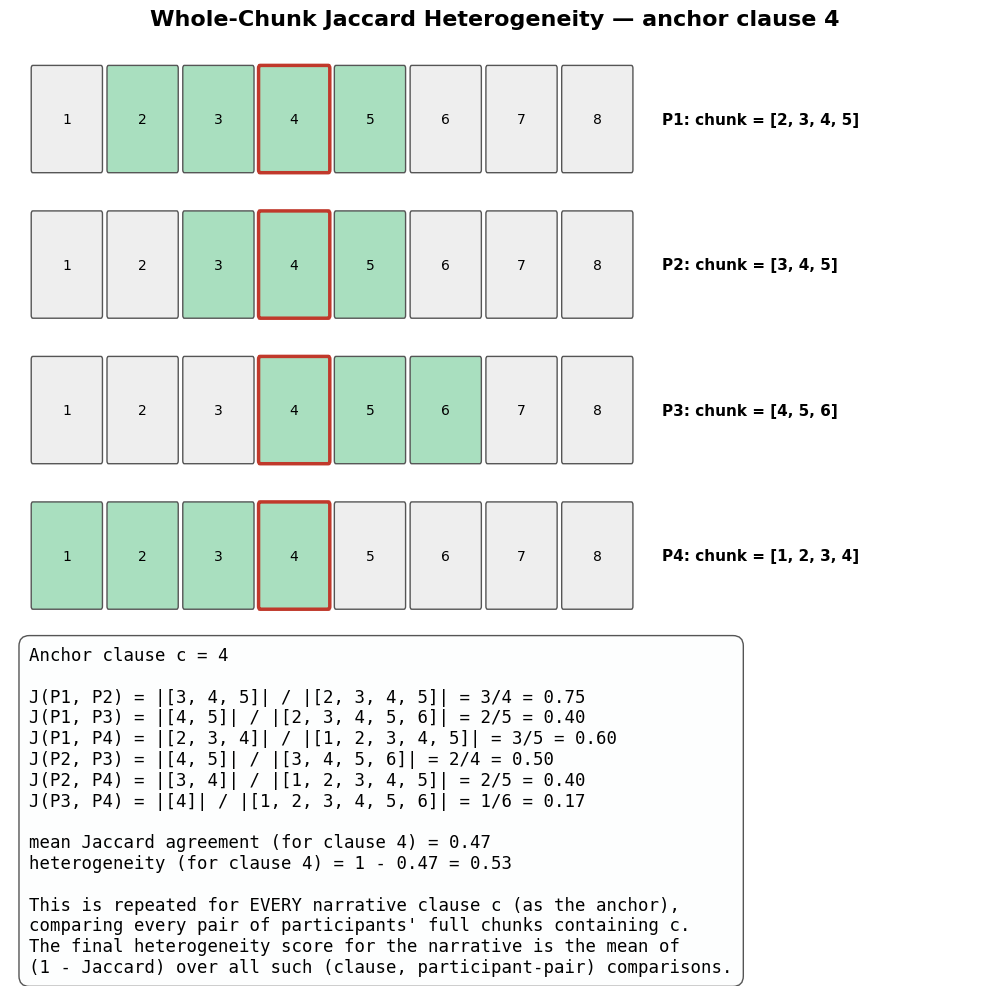

In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from itertools import combinations

# ── toy example: 8 narrative clauses, anchor clause c = 4 ───────────────────
n_clauses = 8
anchor_clause = 4

# each participant's FULL chunk containing the anchor clause (only participants
# who chunked it with something -- size >= 2 -- are shown, matching min_chunk_size)
participant_full_chunks = {
    "P1": {2, 3, 4, 5},
    "P2": {3, 4, 5},
    "P3": {4, 5, 6},
    "P4": {1, 2, 3, 4},
}

chunk_color = "#a9dfbf"
anchor_border = "#c0392b"

n_participants = len(participant_full_chunks)
fig, axes = plt.subplots(n_participants + 1, 1, figsize=(10, 10.5),
                          gridspec_kw={"height_ratios": [1] * n_participants + [2.6]})

box_w, box_h = 0.9, 0.7

for ax, (pname, chunk) in zip(axes[:-1], participant_full_chunks.items()):
    for clause in range(1, n_clauses + 1):
        x = clause - 1
        color = chunk_color if clause in chunk else "#eeeeee"
        rect = mpatches.FancyBboxPatch((x, 0), box_w, box_h,
                                        boxstyle="round,pad=0.02", linewidth=1.0,
                                        edgecolor="#555555", facecolor=color, zorder=2)
        ax.add_patch(rect)
        ax.text(x + box_w / 2, box_h / 2, str(clause), ha="center", va="center",
                fontsize=10, zorder=3)

        if clause == anchor_clause:
            highlight = mpatches.FancyBboxPatch((x, 0), box_w, box_h,
                                                 boxstyle="round,pad=0.02", linewidth=2.5,
                                                 edgecolor=anchor_border, facecolor="none", zorder=4)
            ax.add_patch(highlight)

    ax.text(n_clauses + 0.3, box_h / 2, f"{pname}: chunk = {sorted(chunk)}",
            ha="left", va="center", fontsize=11, fontweight="bold")

    ax.set_xlim(-0.3, n_clauses + 4.5)
    ax.set_ylim(-0.1, box_h + 0.1)
    ax.axis("off")

# ── summary panel: pairwise Jaccard calculation ──────────────────────────────
ax_summary = axes[-1]
ax_summary.axis("off")

lines = [f"Anchor clause c = {anchor_clause}", ""]
jaccards = []
for (name1, s1), (name2, s2) in combinations(participant_full_chunks.items(), 2):
    inter = s1 & s2
    union = s1 | s2
    j = len(inter) / len(union) if union else 1.0
    jaccards.append(j)
    lines.append(f"J({name1}, {name2}) = |{sorted(inter)}| / |{sorted(union)}| "
                 f"= {len(inter)}/{len(union)} = {j:.2f}")

mean_jaccard = sum(jaccards) / len(jaccards)
heterogeneity = 1 - mean_jaccard

lines.append("")
lines.append(f"mean Jaccard agreement (for clause {anchor_clause}) = {mean_jaccard:.2f}")
lines.append(f"heterogeneity (for clause {anchor_clause}) = 1 - {mean_jaccard:.2f} = {heterogeneity:.2f}")
lines.append("")
lines.append("This is repeated for EVERY narrative clause c (as the anchor),")
lines.append("comparing every pair of participants' full chunks containing c.")
lines.append("The final heterogeneity score for the narrative is the mean of")
lines.append("(1 - Jaccard) over all such (clause, participant-pair) comparisons.")

summary_text = "\n".join(lines)
ax_summary.text(0.02, 0.97, summary_text, ha="left", va="top", fontsize=12.5,
                 family="monospace", transform=ax_summary.transAxes,
                 bbox=dict(boxstyle="round,pad=0.6", facecolor="#fdfefe", edgecolor="#555555"))

fig.suptitle(f"Whole-Chunk Jaccard Heterogeneity — anchor clause {anchor_clause}",
             fontsize=16, fontweight="bold", y=0.995)

plt.tight_layout()
plt.savefig("chunk_jaccard_heterogeneity_illustration.png", dpi=150, bbox_inches="tight")
plt.show()


In [51]:
import numpy as np
from itertools import combinations, product

def compute_chunk_jaccard_heterogeneity(story_dicts, n_clauses, min_chunk_size=2):
    """
    For each narrative clause c, and every pair of participants who both
    covered c WITH A REAL CHUNK (size >= min_chunk_size, i.e. not recalled
    as a standalone clause on its own), compute the Jaccard similarity
    between their chunks containing c.

    A participant's clause c may appear in MULTIPLE chunks (a narrative
    clause can be split across several recall clauses) -- rather than
    silently overwriting and keeping only the last one, ALL of that
    participant's chunks containing c are kept. For a given pair of
    participants, Jaccard similarity is computed across every combination
    of their respective chunks containing c, and averaged into ONE value
    representing that pair's agreement for that clause.

    Average Jaccard similarity across all (clause, participant-pair)
    comparisons = "full-chunk agreement"; 1 - that = heterogeneity.
    """
    participant_chunks = []   # one dict per participant: clause -> LIST of full chunk sets containing it
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        clause_to_chunks = {}
        for recall_idx, narrative_indices in clause_dict.items():
            valid = set(n for n in narrative_indices if 1 <= n <= n_clauses)
            if len(valid) < min_chunk_size:
                continue   # skip single-clause "chunks" -- nothing was actually chunked
            for n in valid:
                clause_to_chunks.setdefault(n, []).append(valid)
        participant_chunks.append(clause_to_chunks)

    jaccards = []
    for c in range(1, n_clauses + 1):
        chunks_for_c = [pc[c] for pc in participant_chunks if c in pc]   # list of lists (one list per participant)
        if len(chunks_for_c) < 2:
            continue
        for chunks1, chunks2 in combinations(chunks_for_c, 2):
            pair_jaccards = []
            for s1, s2 in product(chunks1, chunks2):
                union = s1 | s2
                inter = s1 & s2
                j = len(inter) / len(union) if union else 1.0
                pair_jaccards.append(j)
            jaccards.append(np.mean(pair_jaccards))   # one averaged value per participant pair, per clause

    if not jaccards:
        return np.nan, np.nan

    mean_jaccard = np.mean(jaccards)
    heterogeneity = 1 - mean_jaccard
    return mean_jaccard, heterogeneity


for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    agreement, heterogeneity = compute_chunk_jaccard_heterogeneity(clause_dicts_all[story_index], n_clauses)
    print(f"Story {story_index+1}: mean full-chunk Jaccard agreement = {agreement:.3f}, "
          f"heterogeneity = {heterogeneity:.3f}")



Story 1: mean full-chunk Jaccard agreement = 0.581, heterogeneity = 0.419
Story 2: mean full-chunk Jaccard agreement = 0.552, heterogeneity = 0.448
Story 3: mean full-chunk Jaccard agreement = 0.606, heterogeneity = 0.394
Story 4: mean full-chunk Jaccard agreement = 0.514, heterogeneity = 0.486
Story 5: mean full-chunk Jaccard agreement = 0.574, heterogeneity = 0.426
Story 6: mean full-chunk Jaccard agreement = 0.512, heterogeneity = 0.488
Story 7: mean full-chunk Jaccard agreement = 0.543, heterogeneity = 0.457
Story 8: mean full-chunk Jaccard agreement = 0.492, heterogeneity = 0.508
Story 9: mean full-chunk Jaccard agreement = 0.433, heterogeneity = 0.567
Story 10: mean full-chunk Jaccard agreement = 0.437, heterogeneity = 0.563
Story 11: mean full-chunk Jaccard agreement = 0.372, heterogeneity = 0.628
Story 12: mean full-chunk Jaccard agreement = 0.495, heterogeneity = 0.505


Story 1: observed = 0.419 (check 0.419), baseline = 0.714 [0.712, 0.716]
Story 2: observed = 0.448 (check 0.448), baseline = 0.713 [0.708, 0.718]
Story 3: observed = 0.394 (check 0.394), baseline = 0.667 [0.665, 0.670]
Story 4: observed = 0.486 (check 0.486), baseline = 0.716 [0.714, 0.717]
Story 5: observed = 0.426 (check 0.426), baseline = 0.716 [0.715, 0.717]
Story 6: observed = 0.488 (check 0.488), baseline = 0.761 [0.760, 0.761]
Story 7: observed = 0.457 (check 0.457), baseline = 0.716 [0.715, 0.717]
Story 8: observed = 0.508 (check 0.508), baseline = 0.728 [0.727, 0.729]
Story 9: observed = 0.567 (check 0.567), baseline = 0.767 [0.766, 0.768]
Story 10: observed = 0.563 (check 0.563), baseline = 0.780 [0.779, 0.780]
Story 11: observed = 0.628 (check 0.628), baseline = 0.726 [0.725, 0.727]
Story 12: observed = 0.505 (check 0.505), baseline = 0.725 [0.725, 0.726]

Overall (mean over narratives): observed = 0.491, baseline = 0.728 [0.727, 0.728], p = 0.0010


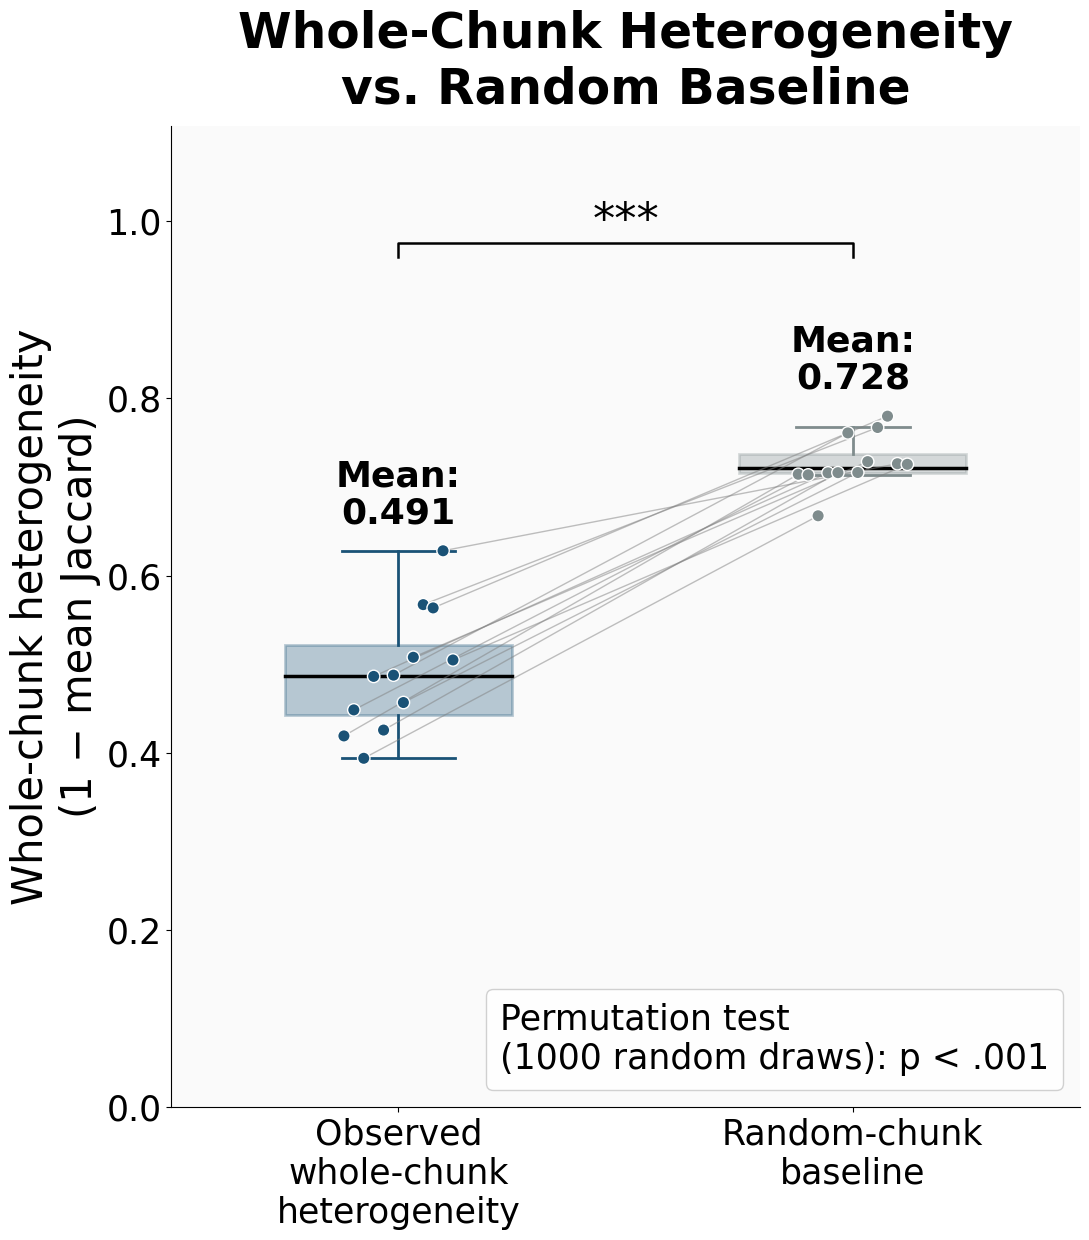

In [52]:
## baseline.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

rng = np.random.default_rng(0)

n_perm         = 1000         # random baselines per narrative
perm_batch     = 250          # permutations computed together (memory control)
min_chunk_size = 2            # same as compute_chunk_jaccard_heterogeneity
fill_from      = 'narrative'  # where the random members come from:
                              #   'narrative' : any other clause of the narrative
                              #   'recalled'  : only clauses that participant recalled
                              #   'contiguous': consecutive clauses around the anchor

# ── participants: all recalled clauses + all real chunks (as in your function) ──
def build_participants(story_dicts, n_clauses):
    parts = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        covered, chunks = set(), []
        for recall_idx, narrative_indices in clause_dict.items():
            valid = set(n for n in narrative_indices if 1 <= n <= n_clauses)
            covered |= valid
            if len(valid) >= min_chunk_size:
                chunks.append(valid)
        parts.append({'covered': covered, 'chunks': chunks})
    return parts

# ── Jaccard per participant pair, averaged over all their chunk combinations ──
def pair_jaccards(A, O, counts):
    """A: (..., R, n) chunk rows; O: (R, P) owner one-hot; counts: (P,) chunks per participant.
       Returns (..., n_pairs): one mean Jaccard per participant pair."""
    inter = A @ np.swapaxes(A, -1, -2)
    sizes = A.sum(axis=-1)
    union = sizes[..., :, None] + sizes[..., None, :] - inter
    J = inter / union
    pair_mean = (O.T @ J @ O) / np.outer(counts, counts)
    iu = np.triu_indices(len(counts), k=1)
    return pair_mean[..., iu[0], iu[1]]

# ── random chunks: same sizes, always containing the anchor ──────────────────
def random_rows(anchor, sizes, allowed, n_clauses, n_draw):
    R = len(sizes)
    if fill_from == 'contiguous':
        lo = np.maximum(1, anchor - sizes + 1)
        hi = np.minimum(anchor, n_clauses - sizes + 1)
        start = rng.integers(lo, hi + 1, size=(n_draw, R))
        idx = np.arange(1, n_clauses + 1)
        return ((idx >= start[..., None]) & (idx < (start + sizes)[..., None])).astype(np.float32)
    rand  = np.where(allowed[None], rng.random((n_draw, R, n_clauses)), 2.0)
    ranks = rand.argsort(axis=-1).argsort(axis=-1)
    k_cap = np.minimum(sizes - 1, allowed.sum(axis=1))   # other members besides the anchor
    member = ranks < k_cap[None, :, None]
    member[:, :, anchor - 1] = True
    return member.astype(np.float32)

# ── observed + baseline per narrative ────────────────────────────────────────
story_rows = []
null_story_all = np.full((n_perm, 12), np.nan)

for s in range(12):
    n_clauses = len(story_processed_all[s])
    parts     = build_participants(clause_dicts_all[s], n_clauses)

    obs_sum, obs_cnt = 0.0, 0
    null_sum = np.zeros(n_perm)

    for anchor in range(1, n_clauses + 1):
        rows, owners, sizes, allowed = [], [], [], []
        p_idx = 0
        for part in parts:
            mine = [ch for ch in part['chunks'] if anchor in ch]
            if not mine:
                continue
            pool = np.zeros(n_clauses, dtype=bool)
            if fill_from == 'recalled':
                pool[np.array(sorted(part['covered'])) - 1] = True
            else:
                pool[:] = True
            pool[anchor - 1] = False
            for ch in mine:
                row = np.zeros(n_clauses, dtype=np.float32)
                row[np.array(sorted(ch)) - 1] = 1
                rows.append(row); owners.append(p_idx)
                sizes.append(len(ch)); allowed.append(pool)
            p_idx += 1

        if p_idx < 2:                                   # need >= 2 participants
            continue
        A       = np.stack(rows)
        owners  = np.array(owners)
        sizes   = np.array(sizes)
        allowed = np.stack(allowed)
        O       = np.eye(p_idx, dtype=np.float32)[owners]
        counts  = np.bincount(owners, minlength=p_idx).astype(np.float32)

        obs_vals = pair_jaccards(A, O, counts)
        obs_sum += obs_vals.sum(); obs_cnt += len(obs_vals)

        for b0 in range(0, n_perm, perm_batch):
            nb = min(perm_batch, n_perm - b0)
            vals = pair_jaccards(random_rows(anchor, sizes, allowed, n_clauses, nb), O, counts)
            null_sum[b0:b0 + nb] += vals.sum(axis=1)

    if obs_cnt == 0:
        print(f"Story {s+1}: no comparisons, skipped.")
        continue

    obs_h  = 1 - obs_sum / obs_cnt                       # pooled over (clause, pair) comparisons
    null_h = 1 - null_sum / obs_cnt
    null_story_all[:, s] = null_h
    _, het_check = compute_chunk_jaccard_heterogeneity(clause_dicts_all[s], n_clauses)

    story_rows.append({
        'story': s + 1, 'n_clauses': n_clauses, 'n_comparisons': obs_cnt,
        'observed': obs_h, 'observed_check': het_check,
        'baseline_mean': null_h.mean(),
        'baseline_ci_low': np.percentile(null_h, 2.5),
        'baseline_ci_high': np.percentile(null_h, 97.5),
        'p_lower_than_baseline': (np.sum(null_h <= obs_h) + 1) / (n_perm + 1),
    })
    print(f"Story {s+1}: observed = {obs_h:.3f} (check {het_check:.3f}), "
          f"baseline = {null_h.mean():.3f} [{np.percentile(null_h, 2.5):.3f}, "
          f"{np.percentile(null_h, 97.5):.3f}]")

story_df = pd.DataFrame(story_rows)
assert np.allclose(story_df['observed'], story_df['observed_check']), \
    "Observed values differ from compute_chunk_jaccard_heterogeneity"

# ── overall: mean over narratives, observed vs. baseline ─────────────────────
obs_overall  = story_df['observed'].mean()
null_overall = np.nanmean(null_story_all, axis=1)       # one overall value per permutation
p_overall    = (np.sum(null_overall <= obs_overall) + 1) / (n_perm + 1)
print(f"\nOverall (mean over narratives): observed = {obs_overall:.3f}, "
      f"baseline = {null_overall.mean():.3f} "
      f"[{np.percentile(null_overall, 2.5):.3f}, {np.percentile(null_overall, 97.5):.3f}], "
      f"p = {p_overall:.4f}")

story_df.to_csv(f'whole_chunk_baseline_{fill_from}.csv', index=False)
np.savez_compressed(f'whole_chunk_baseline_{fill_from}.npz',
                    null_story_all=null_story_all, null_overall=null_overall)


In [53]:
import json
import numpy as np
import pandas as pd

tag = fill_from                                   # 'narrative' | 'recalled' | 'contiguous'

# ── 1. per-narrative table (CSV) ─────────────────────────────────────────────
story_df.to_csv(f'whole_chunk_baseline_{tag}.csv', index=False)

# ── 2. baseline distributions (NPZ) ──────────────────────────────────────────
np.savez_compressed(f'whole_chunk_baseline_{tag}.npz',
                    null_story_all=null_story_all,     # (n_perm, 12) baseline heterogeneity per narrative
                    null_overall=null_overall)         # (n_perm,) baseline mean over narratives

# ── 3. settings + overall result (JSON) ──────────────────────────────────────
meta = {
    'fill_from':      fill_from,
    'n_perm':         int(n_perm),
    'min_chunk_size': int(min_chunk_size),
    'random_seed':    0,
    'measure':        'whole-chunk heterogeneity = 1 - mean Jaccard over (clause, participant-pair) comparisons',
    'obs_overall':    float(obs_overall),
    'baseline_overall_mean': float(null_overall.mean()),
    'baseline_overall_ci':   [float(np.percentile(null_overall, 2.5)),
                              float(np.percentile(null_overall, 97.5))],
    'p_overall':      float(p_overall),
    'stories_used':   [int(s) for s in story_df['story']],
}
with open(f'whole_chunk_baseline_{tag}_meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=1)

print(f"Saved: whole_chunk_baseline_{tag}.csv, whole_chunk_baseline_{tag}.npz, "
      f"whole_chunk_baseline_{tag}_meta.json")


Saved: whole_chunk_baseline_narrative.csv, whole_chunk_baseline_narrative.npz, whole_chunk_baseline_narrative_meta.json


In [54]:
import json
import numpy as np
import pandas as pd

fill_from = 'narrative'                           # which saved run to load

# ── 1. per-narrative table ───────────────────────────────────────────────────
story_df = pd.read_csv(f'whole_chunk_baseline_{fill_from}.csv')

# ── 2. baseline distributions ────────────────────────────────────────────────
arrs           = np.load(f'whole_chunk_baseline_{fill_from}.npz')
null_story_all = arrs['null_story_all']           # (n_perm, 12)
null_overall   = arrs['null_overall']             # (n_perm,)

# ── 3. settings + overall result ─────────────────────────────────────────────
with open(f'whole_chunk_baseline_{fill_from}_meta.json', encoding='utf-8') as f:
    meta = json.load(f)

n_perm         = meta['n_perm']
min_chunk_size = meta['min_chunk_size']
obs_overall    = meta['obs_overall']
p_overall      = meta['p_overall']

# ── check ────────────────────────────────────────────────────────────────────
assert null_story_all.shape[0] == n_perm == len(null_overall)
assert list(story_df['story']) == meta['stories_used']
print(f"Loaded '{fill_from}' baseline: {n_perm} draws, {len(story_df)} narratives")
print(f"Overall: observed = {obs_overall:.3f}, baseline = {meta['baseline_overall_mean']:.3f} "
      f"{[round(v, 3) for v in meta['baseline_overall_ci']]}, p = {p_overall:.4f}")
print()
print(story_df.round(3).to_string(index=False))


Loaded 'narrative' baseline: 1000 draws, 12 narratives
Overall: observed = 0.491, baseline = 0.728 [0.727, 0.728], p = 0.0010

 story  n_clauses  n_comparisons  observed  observed_check  baseline_mean  baseline_ci_low  baseline_ci_high  p_lower_than_baseline
     1         19          18489     0.419           0.419          0.714            0.712             0.716                  0.001
     2         18           2251     0.448           0.448          0.713            0.708             0.718                  0.001
     3         18          11805     0.394           0.394          0.667            0.665             0.670                  0.001
     4         32          17918     0.486           0.486          0.716            0.714             0.717                  0.001
     5         32          18885     0.426           0.426          0.716            0.715             0.717                  0.001
     6         56          50314     0.488           0.488          0.761        

Observed mean = 0.491, baseline mean = 0.728, permutation p = 0.0010


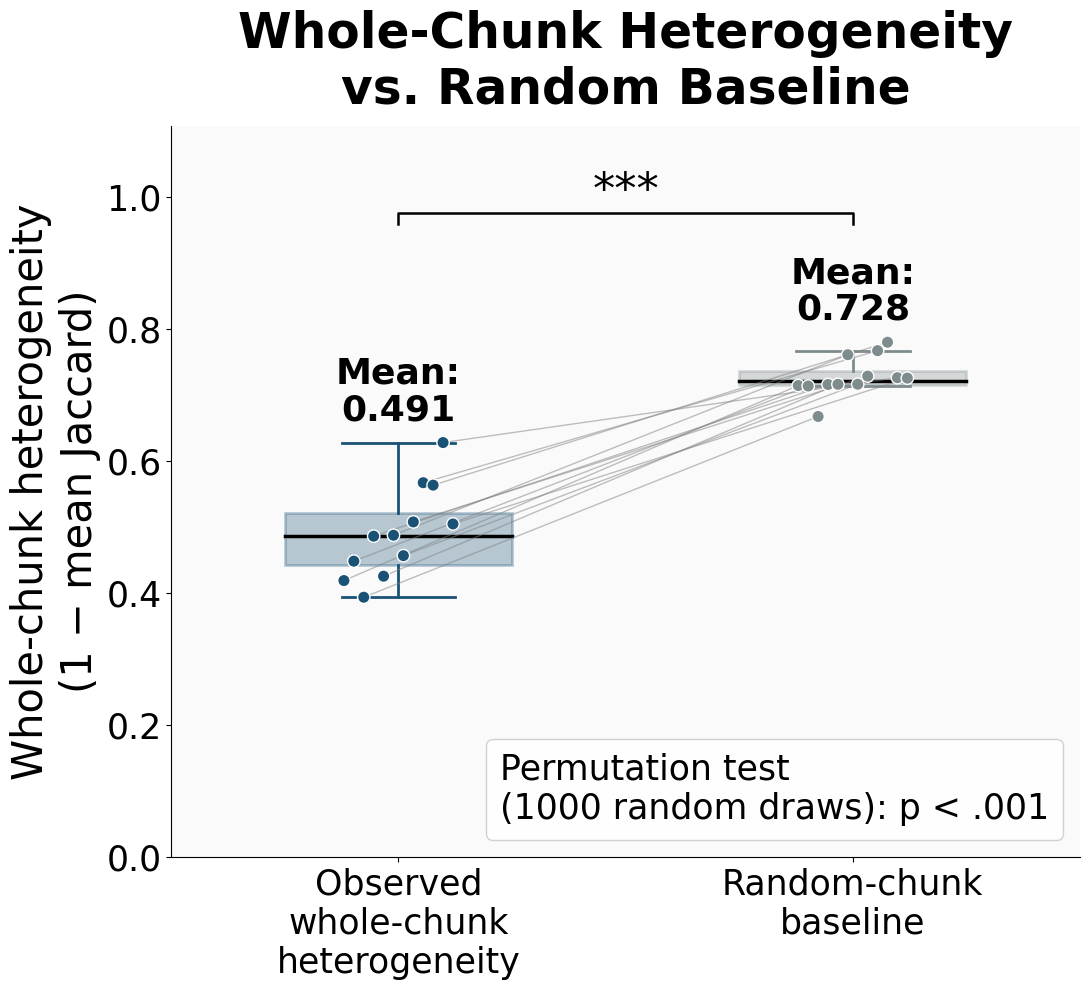

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis label 30, everything else >= 25 ───────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_mean, fs_legend, fs_star = 35, 30, 25, 25, 26, 25, 32

fill_from = 'narrative'      # which saved baseline to plot: 'narrative' | 'recalled' | 'contiguous'

# ── load the whole-chunk baseline results ────────────────────────────────────
story_df       = pd.read_csv(f'whole_chunk_baseline_{fill_from}.csv')
arrs           = np.load(f'whole_chunk_baseline_{fill_from}.npz')
null_story_all = arrs['null_story_all']                 # (n_perm, 12) baseline heterogeneity

story_idx = story_df['story'].to_numpy() - 1            # narratives that had comparisons
observed  = story_df['observed'].to_numpy(dtype=float)  # whole-chunk heterogeneity (1 - mean Jaccard)
null_used = null_story_all[:, story_idx]                # (n_perm, n_used)
baseline  = null_used.mean(axis=0)                      # per-narrative baseline mean

# permutation test on the total (mean over narratives), one-sided: observed lower?
obs_total   = observed.mean()
null_totals = null_used.mean(axis=1)
p_perm      = (np.sum(null_totals <= obs_total) + 1) / (len(null_totals) + 1)
n_perm_used = len(null_totals)
print(f"Observed mean = {obs_total:.3f}, baseline mean = {null_totals.mean():.3f}, "
      f"permutation p = {p_perm:.4f}")

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

p_text     = "p < .001" if p_perm < 0.001 else f"p = {p_perm:.3f}"
test_label = f"Permutation test\n({n_perm_used} random draws): {p_text}"

names     = ["Observed\nwhole-chunk\nheterogeneity", "Random-chunk\nbaseline"]
data      = [observed, baseline]
colors    = ['#1a5276', '#7f8c8d']
positions = np.arange(2)
n_stories = len(observed)

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 10))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box
y_max_all = max(np.nanmax(d) for d in data)
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.03 * y_max_all, f"Mean:\n{v.mean():.3f}",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6, linespacing=1.1)

# dots per narrative, connected between the two boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    if not np.isnan(ys).any():
        ax.plot(xs, ys, color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# significance bracket (permutation test)
yb, tick = y_max_all * 1.25, y_max_all * 0.02
ax.plot([0, 0, 1, 1], [yb - tick, yb, yb, yb - tick], color='black', lw=1.8, zorder=6)
ax.text(0.5, yb, add_stars(p_perm), ha='center', va='bottom', fontsize=fs_star, zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(names, fontsize=fs_xtick)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_ylabel("Whole-chunk heterogeneity\n(1 − mean Jaccard)", fontsize=fs_label)
ax.set_title("Whole-Chunk Heterogeneity\nvs. Random Baseline",
             fontsize=fs_title, pad=16, fontweight='bold')
ax.set_ylim(0, y_max_all * 1.42)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[test_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"whole_chunk_heterogeneity_vs_baseline_boxplot_{fill_from}.png", dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()


Ratio (observed / baseline) vs. length: slope = 0.00135, R² = 0.874, p < 0.001 ***
Mean ratio = 0.673
Difference (observed - baseline) vs. length: slope = 0.00088, R² = 0.814, p < 0.001 ***


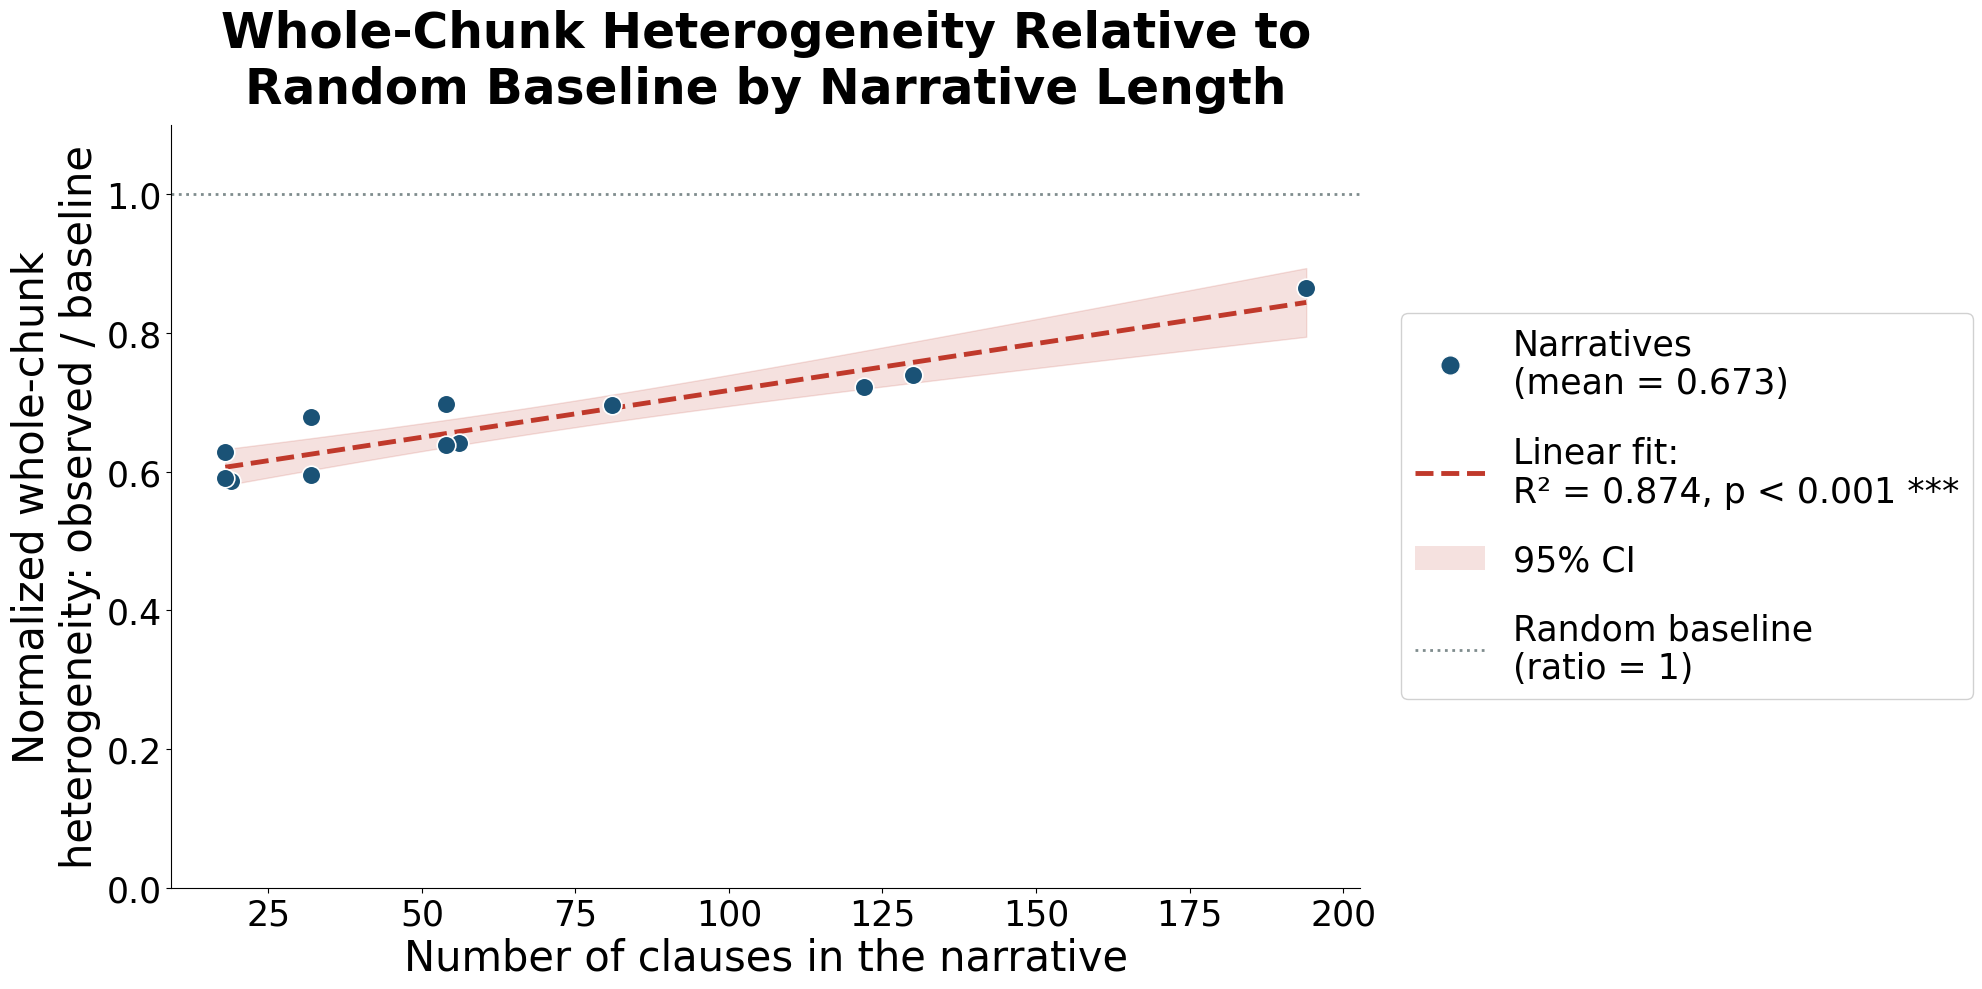

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_tick, fs_legend = 35, 30, 25, 25

fill_from = 'narrative'      # which saved baseline to use: 'narrative' | 'recalled' | 'contiguous'

# ── load observed whole-chunk heterogeneity + its random-chunk baseline ──────
story_df = pd.read_csv(f'whole_chunk_baseline_{fill_from}.csv')

story_lengths = story_df['n_clauses'].to_numpy(dtype=float)
observed      = story_df['observed'].to_numpy(dtype=float)        # 1 - mean Jaccard
baseline      = story_df['baseline_mean'].to_numpy(dtype=float)   # same, for random chunks

# normalized whole-chunk heterogeneity: 1 = as different as random chunks, 0 = identical chunks
ratio = observed / baseline
diff  = observed - baseline          # kept for the robustness check below

def p_label_str(p):
    if p < 0.001:
        return "p < 0.001 ***"
    elif p < 0.01:
        return f"p = {p:.3f} **"
    elif p < 0.05:
        return f"p = {p:.3f} *"
    else:
        return f"p = {p:.3f}"

# ── linear regression of the ratio on narrative length ───────────────────────
model_fit = sm.OLS(ratio, sm.add_constant(story_lengths), missing='drop').fit()
slope     = model_fit.params[1]
p_value   = model_fit.pvalues[1]
r2        = model_fit.rsquared

x_reg = np.linspace(story_lengths.min(), story_lengths.max(), 200)
pred  = model_fit.get_prediction(sm.add_constant(x_reg)).summary_frame(alpha=0.05)

print(f"Ratio (observed / baseline) vs. length: slope = {slope:.5f}, R² = {r2:.3f}, "
      f"{p_label_str(p_value)}")
print(f"Mean ratio = {np.nanmean(ratio):.3f}")

# robustness: same regression on the plain difference
model_diff = sm.OLS(diff, sm.add_constant(story_lengths), missing='drop').fit()
print(f"Difference (observed - baseline) vs. length: slope = {model_diff.params[1]:.5f}, "
      f"R² = {model_diff.rsquared:.3f}, {p_label_str(model_diff.pvalues[1])}")

# ── plot (landscape) ──────────────────────────────────────────────────────────
dot_color, fit_color = '#1a5276', '#c0392b'
fig, ax = plt.subplots(figsize=(20, 10))

ax.axhline(1, color='#7f8c8d', lw=2, ls=':', zorder=1)          # = random-chunk baseline

ax.scatter(story_lengths, ratio, color=dot_color, s=180,
           edgecolor='white', linewidth=1.2, zorder=3)
ax.plot(x_reg, pred['mean'], '--', color=fit_color, lw=3.5, zorder=2)
ax.fill_between(x_reg, pred['mean_ci_lower'], pred['mean_ci_upper'],
                color=fit_color, alpha=0.15, zorder=1)

ax.set_xlabel("Number of clauses in the narrative", fontsize=fs_label)
ax.set_ylabel("Normalized whole-chunk\nheterogeneity: observed / baseline", fontsize=fs_label)
ax.set_title("Whole-Chunk Heterogeneity Relative to\nRandom Baseline by Narrative Length",
             fontsize=fs_title, fontweight='bold', pad=16)
ax.set_ylim(0, max(1.1, np.nanmax(ratio) * 1.1))
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=fs_tick)

handles = [
    Line2D([0], [0], marker='o', color=dot_color, linestyle='none', markersize=14,
           markeredgecolor='white', label=f"Narratives\n(mean = {np.nanmean(ratio):.3f})"),
    Line2D([0], [0], color=fit_color, linestyle='--', lw=3.5,
           label=f"Linear fit:\nR² = {r2:.3f}, {p_label_str(p_value)}"),
    Patch(facecolor=fit_color, alpha=0.15, label="95% CI"),
    Line2D([0], [0], color='#7f8c8d', linestyle=':', lw=2,
           label="Random baseline\n(ratio = 1)"),
]
ax.legend(handles=handles, fontsize=fs_legend, loc='center left', bbox_to_anchor=(1.02, 0.5),
          frameon=True, framealpha=0.9, labelspacing=1.0)

plt.tight_layout()
plt.savefig(f"whole_chunk_heterogeneity_ratio_by_length_{fill_from}.png", dpi=150,
            bbox_inches='tight')
plt.show()


## ~ compare normalized heterogeneity of pairwise and whole-chunk, with narrative length.

Pairwise: mean ratio = 0.403, slope = 0.00203, R² = 0.849, p < 0.001 ***, SE per narrative = [0.0337 0.0292 0.025  0.0308 0.0237 0.0166 0.0228 0.0206 0.0127 0.0144
 0.0164 0.0167]
Whole-chunk: mean ratio = 0.673, slope = 0.00135, R² = 0.874, p < 0.001 ***, SE per narrative = [0.0028 0.0089 0.0044 0.0027 0.0029 0.0016 0.0027 0.0024 0.0022 0.0012
 0.0027 0.0024]


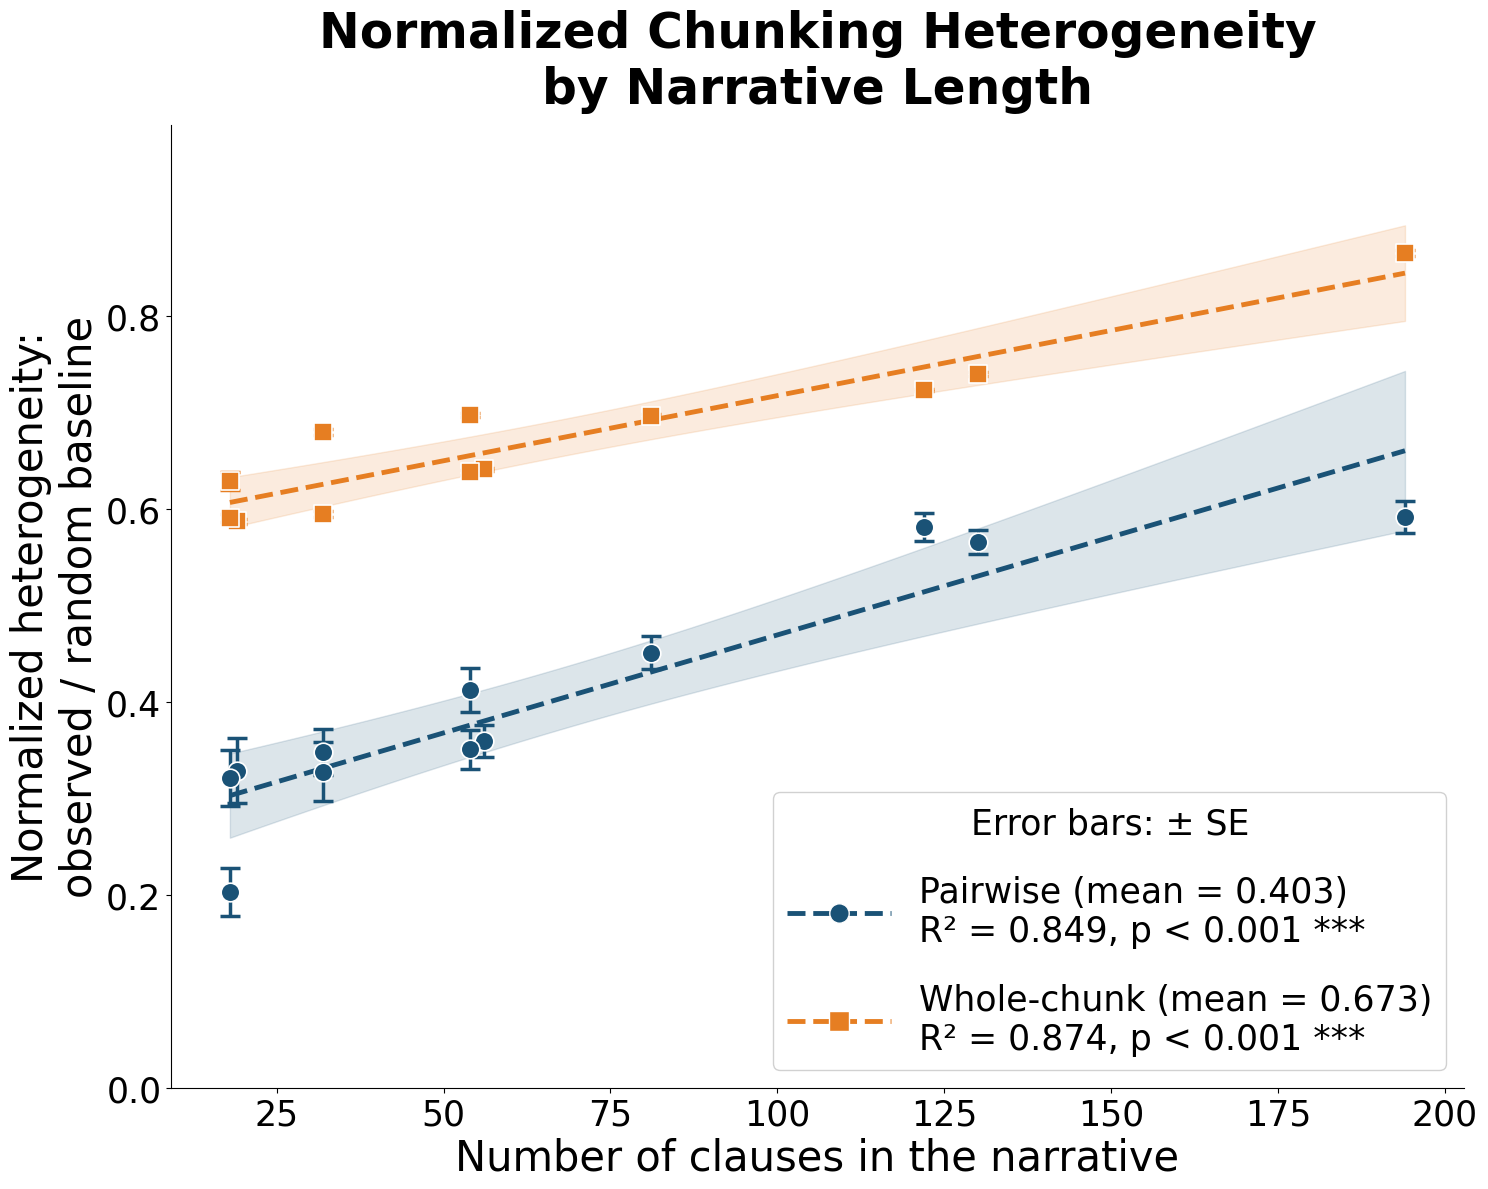

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from itertools import combinations, product
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_tick, fs_legend = 35, 30, 25, 25

clauses   = [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]   # clauses per narrative
fill_from = 'narrative'      # whole-chunk baseline to use: 'narrative' | 'recalled' | 'contiguous'
min_chunk_size = 2           # as in compute_chunk_jaccard_heterogeneity

# ══ per-comparison values from the original data ══════════════════════════════

# pairwise: per-pair disagreement 2 * min(p, 1 - p), same rules as the baseline script
def participant_labels(story_dicts, n_clauses):
    labels = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        same_chunk = {}
        for recall_idx, narrative_indices in clause_dict.items():
            for n in narrative_indices:
                if 1 <= n <= n_clauses:
                    same_chunk[n] = recall_idx
        labels.append(same_chunk)
    return labels

def pairwise_disagreements(story_dicts, n_clauses):
    labels = participant_labels(story_dicts, n_clauses)
    P = len(labels)
    covered = np.zeros((P, n_clauses), dtype=np.int32)
    cols = []
    for p, lab in enumerate(labels):
        by_chunk = {}
        for clause, chunk in lab.items():
            covered[p, clause - 1] = 1
            by_chunk.setdefault(chunk, []).append(clause - 1)
        for members in by_chunk.values():
            col = np.zeros(n_clauses, dtype=np.int32)
            col[members] = 1
            cols.append(col)
    M = np.stack(cols, axis=1) if cols else np.zeros((n_clauses, 1), dtype=np.int32)
    iu = np.triu_indices(n_clauses, k=1)
    b, t = (covered.T @ covered)[iu], (M @ M.T)[iu]
    mask = (b >= 2) & (t > 0)
    p = t[mask] / b[mask]
    return 2 * np.minimum(p, 1 - p)

# whole-chunk: per (clause, participant-pair) Jaccard, same rules as your function
def whole_chunk_jaccards(story_dicts, n_clauses):
    participant_chunks = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        clause_to_chunks = {}
        for recall_idx, narrative_indices in clause_dict.items():
            valid = set(n for n in narrative_indices if 1 <= n <= n_clauses)
            if len(valid) < min_chunk_size:
                continue
            for n in valid:
                clause_to_chunks.setdefault(n, []).append(valid)
        participant_chunks.append(clause_to_chunks)
    jaccards = []
    for c in range(1, n_clauses + 1):
        chunks_for_c = [pc[c] for pc in participant_chunks if c in pc]
        if len(chunks_for_c) < 2:
            continue
        for chunks1, chunks2 in combinations(chunks_for_c, 2):
            jaccards.append(np.mean([len(s1 & s2) / len(s1 | s2)
                                     for s1, s2 in product(chunks1, chunks2)]))
    return np.array(jaccards)

def sem(v):
    return np.std(v, ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan

# ── pairwise: observed vs. coin-flip baseline ────────────────────────────────
pw = np.load('heterogeneity_coinflip_baseline_arrays.npz')
pw_obs      = pw['obs_h'].astype(float)                  # (12,) heterogeneity
pw_baseline = np.nanmean(pw['null_h'], axis=0)           # (12,) baseline mean
pw_x        = np.array(clauses, dtype=float)
pw_ratio    = pw_obs / pw_baseline

pw_se_obs = np.full(12, np.nan)
for s in range(12):
    d = pairwise_disagreements(clause_dicts_all[s], len(story_processed_all[s]))
    assert np.isclose(d.mean(), pw_obs[s]), f"pairwise story {s+1}: rebuilt mean differs"
    pw_se_obs[s] = sem(d)
pw_se_ratio = pw_se_obs / pw_baseline                     # SE on the normalized scale

# ── whole-chunk: observed vs. random-chunk baseline ──────────────────────────
wc = pd.read_csv(f'whole_chunk_baseline_{fill_from}.csv')
wc_x        = wc['n_clauses'].to_numpy(dtype=float)
wc_obs      = wc['observed'].to_numpy(dtype=float)
wc_baseline = wc['baseline_mean'].to_numpy(dtype=float)
wc_ratio    = wc_obs / wc_baseline

wc_se_obs = np.full(len(wc), np.nan)
for k, s in enumerate(wc['story'].to_numpy() - 1):
    j = whole_chunk_jaccards(clause_dicts_all[s], len(story_processed_all[s]))
    assert np.isclose(1 - j.mean(), wc_obs[k]), f"whole-chunk story {s+1}: rebuilt mean differs"
    wc_se_obs[k] = sem(j)                                 # SE of mean Jaccard = SE of 1 - mean
wc_se_ratio = wc_se_obs / wc_baseline

def p_label_str(p):
    if p < 0.001:
        return "p < 0.001 ***"
    elif p < 0.01:
        return f"p = {p:.3f} **"
    elif p < 0.05:
        return f"p = {p:.3f} *"
    else:
        return f"p = {p:.3f}"

def fit_line(x, y):
    m = sm.OLS(y, sm.add_constant(x), missing='drop').fit()
    x_reg = np.linspace(np.nanmin(x), np.nanmax(x), 200)
    pred  = m.get_prediction(sm.add_constant(x_reg)).summary_frame(alpha=0.05)
    return m, x_reg, pred

series = [  # (name, x, ratio, SE, color, marker)
    ("Pairwise",    pw_x, pw_ratio, pw_se_ratio, '#1a5276', 'o'),
    ("Whole-chunk", wc_x, wc_ratio, wc_se_ratio, '#e67e22', 's'),
]

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 12))

handles = []
for name, x, ratio, se, color, marker in series:
    m, x_reg, pred = fit_line(x, ratio)
    print(f"{name}: mean ratio = {np.nanmean(ratio):.3f}, slope = {m.params[1]:.5f}, "
          f"R² = {m.rsquared:.3f}, {p_label_str(m.pvalues[1])}, "
          f"SE per narrative = {np.round(se, 4)}")

    ax.errorbar(x, ratio, yerr=se, fmt='none', ecolor=color, elinewidth=2.5,
                capsize=7, capthick=2.5, zorder=3)
    ax.scatter(x, ratio, color=color, marker=marker, s=180,
               edgecolor='white', linewidth=1.2, zorder=4)
    ax.plot(x_reg, pred['mean'], '--', color=color, lw=3.5, zorder=2)
    ax.fill_between(x_reg, pred['mean_ci_lower'], pred['mean_ci_upper'],
                    color=color, alpha=0.15, zorder=1)

    # one legend entry per measure: its marker + dashed fit line, in its own color
    handles.append(
        Line2D([0], [0], marker=marker, color=color, linestyle='--', lw=3.5,
               markersize=14, markeredgecolor='white',
               label=f"{name} (mean = {np.nanmean(ratio):.3f})\n"
                     f"R² = {m.rsquared:.3f}, {p_label_str(m.pvalues[1])}"))

ax.set_xlabel("Number of clauses in the narrative", fontsize=fs_label)
ax.set_ylabel("Normalized heterogeneity:\nobserved / random baseline", fontsize=fs_label)
ax.set_title("Normalized Chunking Heterogeneity\nby Narrative Length",
             fontsize=fs_title, fontweight='bold', pad=16)
y_top = np.nanmax(np.concatenate([pw_ratio + pw_se_ratio, wc_ratio + wc_se_ratio]))
ax.set_ylim(0, y_top * 1.15)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=fs_tick)

# legend inside the plot, bottom right; the two measures back to back
ax.legend(handles=handles, fontsize=fs_legend, loc='lower right',
          frameon=True, framealpha=0.9, labelspacing=1.0, handlelength=3,
          title="Error bars: ± SE", title_fontsize=fs_legend)

plt.tight_layout()
plt.savefig(f"normalized_heterogeneity_pairwise_wholechunk_{fill_from}.png", dpi=150,
            bbox_inches='tight')
plt.show()


## 2.2. Whole chunk heterogeneity distribution with the location of the anchor clause in the narrative.

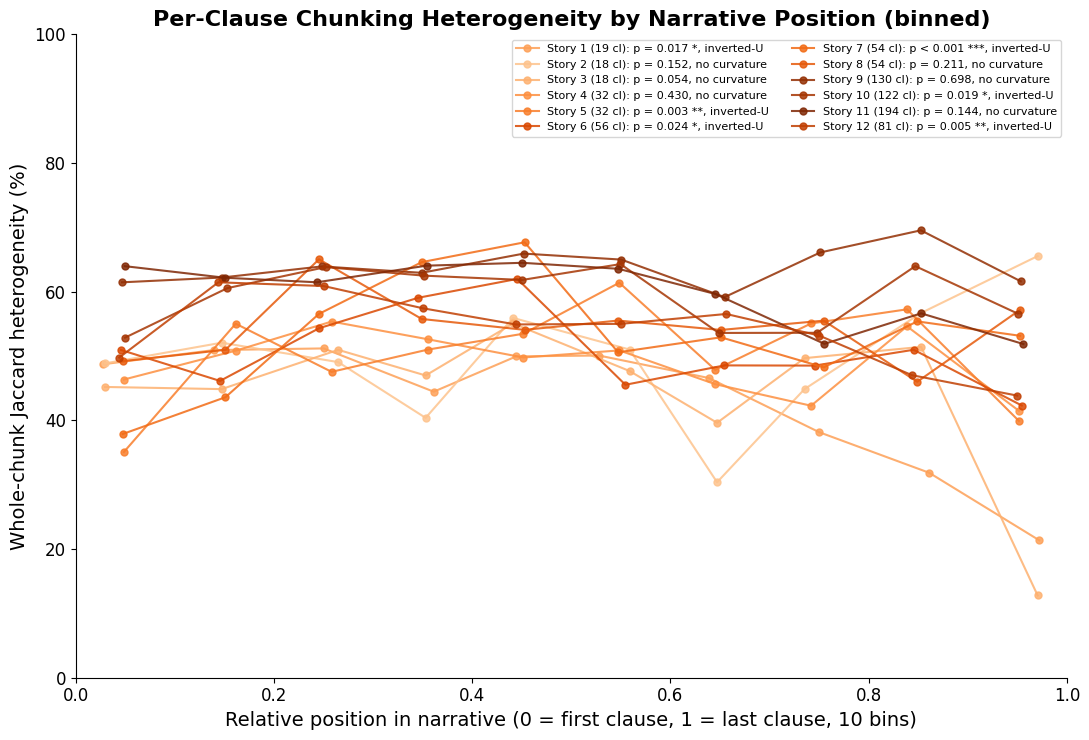

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from itertools import combinations, product

def compute_chunk_jaccard_heterogeneity_per_clause(story_dicts, n_clauses, min_chunk_size=2):
    """
    Same logic as compute_chunk_jaccard_heterogeneity, but returns the
    heterogeneity value for EACH narrative clause c individually (as a
    percentage, 0-100%), instead of collapsing to one story-level mean.
    """
    participant_chunks = []
    for clause_dict in story_dicts:
        if clause_dict is None:
            continue
        clause_to_chunks = {}
        for recall_idx, narrative_indices in clause_dict.items():
            valid = set(n for n in narrative_indices if 1 <= n <= n_clauses)
            if len(valid) < min_chunk_size:
                continue
            for n in valid:
                clause_to_chunks.setdefault(n, []).append(valid)
        participant_chunks.append(clause_to_chunks)

    heterogeneity_per_clause = {}
    for c in range(1, n_clauses + 1):
        chunks_for_c = [pc[c] for pc in participant_chunks if c in pc]
        if len(chunks_for_c) < 2:
            heterogeneity_per_clause[c] = np.nan
            continue

        jaccards = []
        for chunks1, chunks2 in combinations(chunks_for_c, 2):
            pair_jaccards = []
            for s1, s2 in product(chunks1, chunks2):
                union = s1 | s2
                inter = s1 & s2
                j = len(inter) / len(union) if union else 1.0
                pair_jaccards.append(j)
            jaccards.append(np.mean(pair_jaccards))

        mean_jaccard = np.mean(jaccards)
        heterogeneity_per_clause[c] = (1 - mean_jaccard) * 100

    return heterogeneity_per_clause

############################# plot 

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib import cm

n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)

total_clauses_per_story = np.array([len(story_processed_all[i]) for i in range(12)])
length_rank = np.argsort(np.argsort(total_clauses_per_story))
orange_colors = cm.Oranges(np.linspace(0.3, 1.0, 12))

def p_label_str(p):
    if p < 0.001: return "p < 0.001 ***"
    elif p < 0.01: return f"p = {p:.3f} **"
    elif p < 0.05: return f"p = {p:.3f} *"
    else: return f"p = {p:.3f}"

def test_quadratic_shape(relative_positions, heterogeneity_values):
    """
    Fits heterogeneity ~ b0 + b1*x + b2*x^2 and reports the quadratic
    coefficient's sign/significance -- b2 < 0 (significant) means an
    inverted-U shape (low at both ends, peak in the middle).
    """
    x = np.array(relative_positions, dtype=float)
    y = np.array(heterogeneity_values, dtype=float)

    X = np.column_stack([x, x**2])
    X = sm.add_constant(X)
    model_fit = sm.OLS(y, X).fit()

    b1, b2 = model_fit.params[1], model_fit.params[2]
    p_linear, p_quad = model_fit.pvalues[1], model_fit.pvalues[2]

    return b1, p_linear, b2, p_quad, model_fit


fig, ax = plt.subplots(figsize=(11, 7.5))

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    het_per_clause = compute_chunk_jaccard_heterogeneity_per_clause(clause_dicts_all[story_index], n_clauses)

    clause_indices = sorted(het_per_clause.keys())
    heterogeneity_values = np.array([het_per_clause[c] for c in clause_indices], dtype=float)
    relative_positions = np.array(
        [(c - 1) / (n_clauses - 1) if n_clauses > 1 else 0.0 for c in clause_indices]
    )

    valid_mask = ~np.isnan(heterogeneity_values)
    x_raw = relative_positions[valid_mask]
    y_raw = heterogeneity_values[valid_mask]

    if len(x_raw) == 0:
        continue

    # ── quadratic shape test on the RAW per-clause data ──────────────────────
    if len(x_raw) >= 5:
        b1, p_linear, b2, p_quad, model_fit = test_quadratic_shape(x_raw, y_raw)
        if p_quad < 0.05:
            shape_label = "inverted-U" if b2 < 0 else "U-shape"
        else:
            shape_label = "no curvature"
        quad_str = f"{p_label_str(p_quad)}, {shape_label}"
    else:
        quad_str = "p n/a (too few clauses)"

    # ── binned means, for the plotted line ───────────────────────────────────
    bin_indices = np.clip(np.digitize(x_raw, bin_edges) - 1, 0, n_bins - 1)
    bin_mean_x, bin_mean_y = [], []
    for b in range(n_bins):
        mask = bin_indices == b
        if mask.sum() == 0:
            continue
        bin_mean_x.append(x_raw[mask].mean())
        bin_mean_y.append(y_raw[mask].mean())

    color = orange_colors[length_rank[story_index]]
    ax.plot(bin_mean_x, bin_mean_y, marker="o", markersize=5, linewidth=1.5,
            color=color, label=f"Story {story_index+1} ({n_clauses} cl): {quad_str}", alpha=0.85)

ax.set_xlabel("Relative position in narrative (0 = first clause, 1 = last clause, 10 bins)", fontsize=14)
ax.set_ylabel("Whole-chunk Jaccard heterogeneity (%)", fontsize=14)
ax.set_title("Per-Clause Chunking Heterogeneity by Narrative Position (binned)", fontsize=16, fontweight='bold')
ax.set_xlim(0, 1)
ax.set_ylim(0, 100)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=12)
ax.legend(fontsize=8, ncol=2, loc="best")

plt.tight_layout()
plt.savefig("per_clause_chunk_jaccard_heterogeneity_by_position_binned.png", dpi=150, bbox_inches='tight')
plt.show()




Pooled quadratic fit over all 762 points from 12 stories: b2=-30.240, p < 0.001 ***


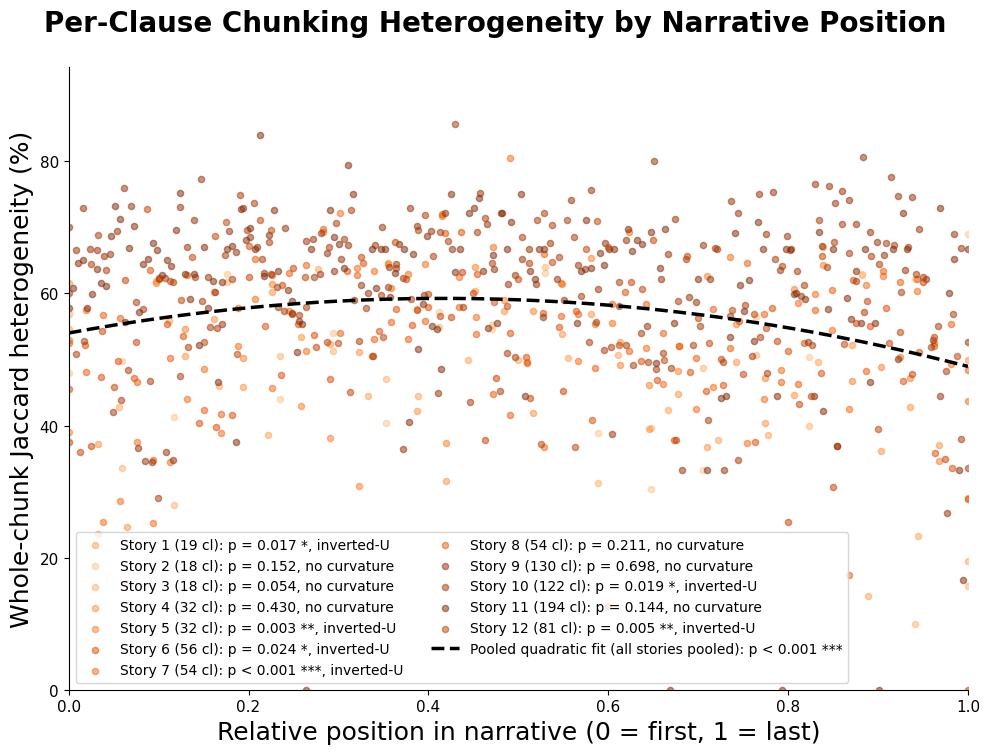

Peak of fitted curve: x = 0.417, y = 59.250
Left end (x=0):  y = 54.008
Right end (x=1): y = 48.949


In [38]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib import cm

total_clauses_per_story = np.array([len(story_processed_all[i]) for i in range(12)])
length_rank = np.argsort(np.argsort(total_clauses_per_story))
orange_colors = cm.Oranges(np.linspace(0.3, 1.0, 12))

def p_label_str(p):
    if p < 0.001: return "p < 0.001 ***"
    elif p < 0.01: return f"p = {p:.3f} **"
    elif p < 0.05: return f"p = {p:.3f} *"
    else: return f"p = {p:.3f}"

def test_quadratic_shape(relative_positions, heterogeneity_values):
    x = np.array(relative_positions, dtype=float)
    y = np.array(heterogeneity_values, dtype=float)
    X = np.column_stack([x, x**2])
    X = sm.add_constant(X)
    model_fit = sm.OLS(y, X).fit()
    b1, b2 = model_fit.params[1], model_fit.params[2]
    p_linear, p_quad = model_fit.pvalues[1], model_fit.pvalues[2]
    return b1, p_linear, b2, p_quad, model_fit


# ── compute everything per story, pool ALL pairs across stories ─────────────
story_entries = []
pooled_x_all = []
pooled_y_all = []

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    het_per_clause = compute_chunk_jaccard_heterogeneity_per_clause(clause_dicts_all[story_index], n_clauses)

    clause_indices = sorted(het_per_clause.keys())
    heterogeneity_values = np.array([het_per_clause[c] for c in clause_indices], dtype=float)
    relative_positions = np.array(
        [(c - 1) / (n_clauses - 1) if n_clauses > 1 else 0.0 for c in clause_indices]
    )

    valid_mask = ~np.isnan(heterogeneity_values)
    x_raw = relative_positions[valid_mask]
    y_raw = heterogeneity_values[valid_mask]

    if len(x_raw) < 5:
        quad_str = "p n/a (too few clauses)"
    else:
        b1, p_linear, b2, p_quad, model_fit = test_quadratic_shape(x_raw, y_raw)
        if p_quad < 0.05:
            shape_label = "inverted-U" if b2 < 0 else "U-shape"
        else:
            shape_label = "no curvature"
        quad_str = f"{p_label_str(p_quad)}, {shape_label}"

    story_entries.append({
        "story_index": story_index,
        "n_clauses": n_clauses,
        "x_raw": x_raw,
        "y_raw": y_raw,
        "quad_str": quad_str,
        "color": orange_colors[length_rank[story_index]],
    })

    pooled_x_all.extend(x_raw.tolist())
    pooled_y_all.extend(y_raw.tolist())

pooled_x_all = np.array(pooled_x_all)
pooled_y_all = np.array(pooled_y_all)

# ── pooled quadratic fit over ALL raw points from ALL stories ───────────────
b1_pool, p_linear_pool, b2_pool, p_quad_pool, pooled_model_fit = test_quadratic_shape(pooled_x_all, pooled_y_all)

x_fit = np.linspace(0, 1, 200)
X_fit = sm.add_constant(np.column_stack([x_fit, x_fit**2]))
y_fit = pooled_model_fit.predict(X_fit)

print(f"Pooled quadratic fit over all {len(pooled_x_all)} points from {len(story_entries)} stories: "
      f"b2={b2_pool:.3f}, {p_label_str(p_quad_pool)}")

# ── plot: one figure, all raw points together + pooled quadratic fit ────────
fig, ax = plt.subplots(figsize=(10, 7.5))

for entry in story_entries:
    ax.scatter(entry["x_raw"], entry["y_raw"], s=20, color=entry["color"], alpha=0.5,
               label=f"Story {entry['story_index']+1} ({entry['n_clauses']} cl): {entry['quad_str']}")

ax.plot(x_fit, y_fit, '--', linewidth=2.5, color="black", zorder=4,
        label=f"Pooled quadratic fit (all stories pooled): {p_label_str(p_quad_pool)}")

ax.set_xlabel("Relative position in narrative (0 = first, 1 = last)", fontsize=18)
ax.set_ylabel("Whole-chunk Jaccard heterogeneity (%)", fontsize=18)
ax.set_xlim(0, 1)

# adapt y-axis to the data range instead of fixing it to 0-100
all_y_vals = np.concatenate([entry["y_raw"] for entry in story_entries])
y_min, y_max = all_y_vals.min(), all_y_vals.max()
y_pad = (y_max - y_min) * 0.1
ax.set_ylim(max(0, y_min - y_pad), y_max + y_pad)

ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=11)
ax.legend(fontsize=10, loc="best", ncol=2)

fig.suptitle("Per-Clause Chunking Heterogeneity by Narrative Position", fontsize=20, fontweight='bold', y=1.0)

plt.tight_layout()
plt.savefig("per_clause_heterogeneity_single_figure_unbinned.png", dpi=150, bbox_inches='tight')
plt.show()

peak_idx = np.argmax(y_fit)
print(f"Peak of fitted curve: x = {x_fit[peak_idx]:.3f}, y = {y_fit[peak_idx]:.3f}")
print(f"Left end (x=0):  y = {y_fit[0]:.3f}")
print(f"Right end (x=1): y = {y_fit[-1]:.3f}")


Pooled quadratic fit over all 762 points from 12 stories: b2=-30.240, p < 0.001 ***
Peak of fitted curve: x = 0.417, y = 59.250
Left end (x=0):  y = 54.008
Right end (x=1): y = 48.949

Pooled bin means (n_bins = 10):
  x = 0.046, mean y = 53.522, n = 86
  x = 0.150, mean y = 57.278, n = 79
  x = 0.249, mean y = 59.892, n = 77
  x = 0.351, mean y = 60.043, n = 76
  x = 0.449, mean y = 60.747, n = 73
  x = 0.549, mean y = 58.270, n = 74
  x = 0.650, mean y = 54.220, n = 71
  x = 0.750, mean y = 53.351, n = 71
  x = 0.849, mean y = 56.913, n = 77
  x = 0.954, mean y = 50.548, n = 78


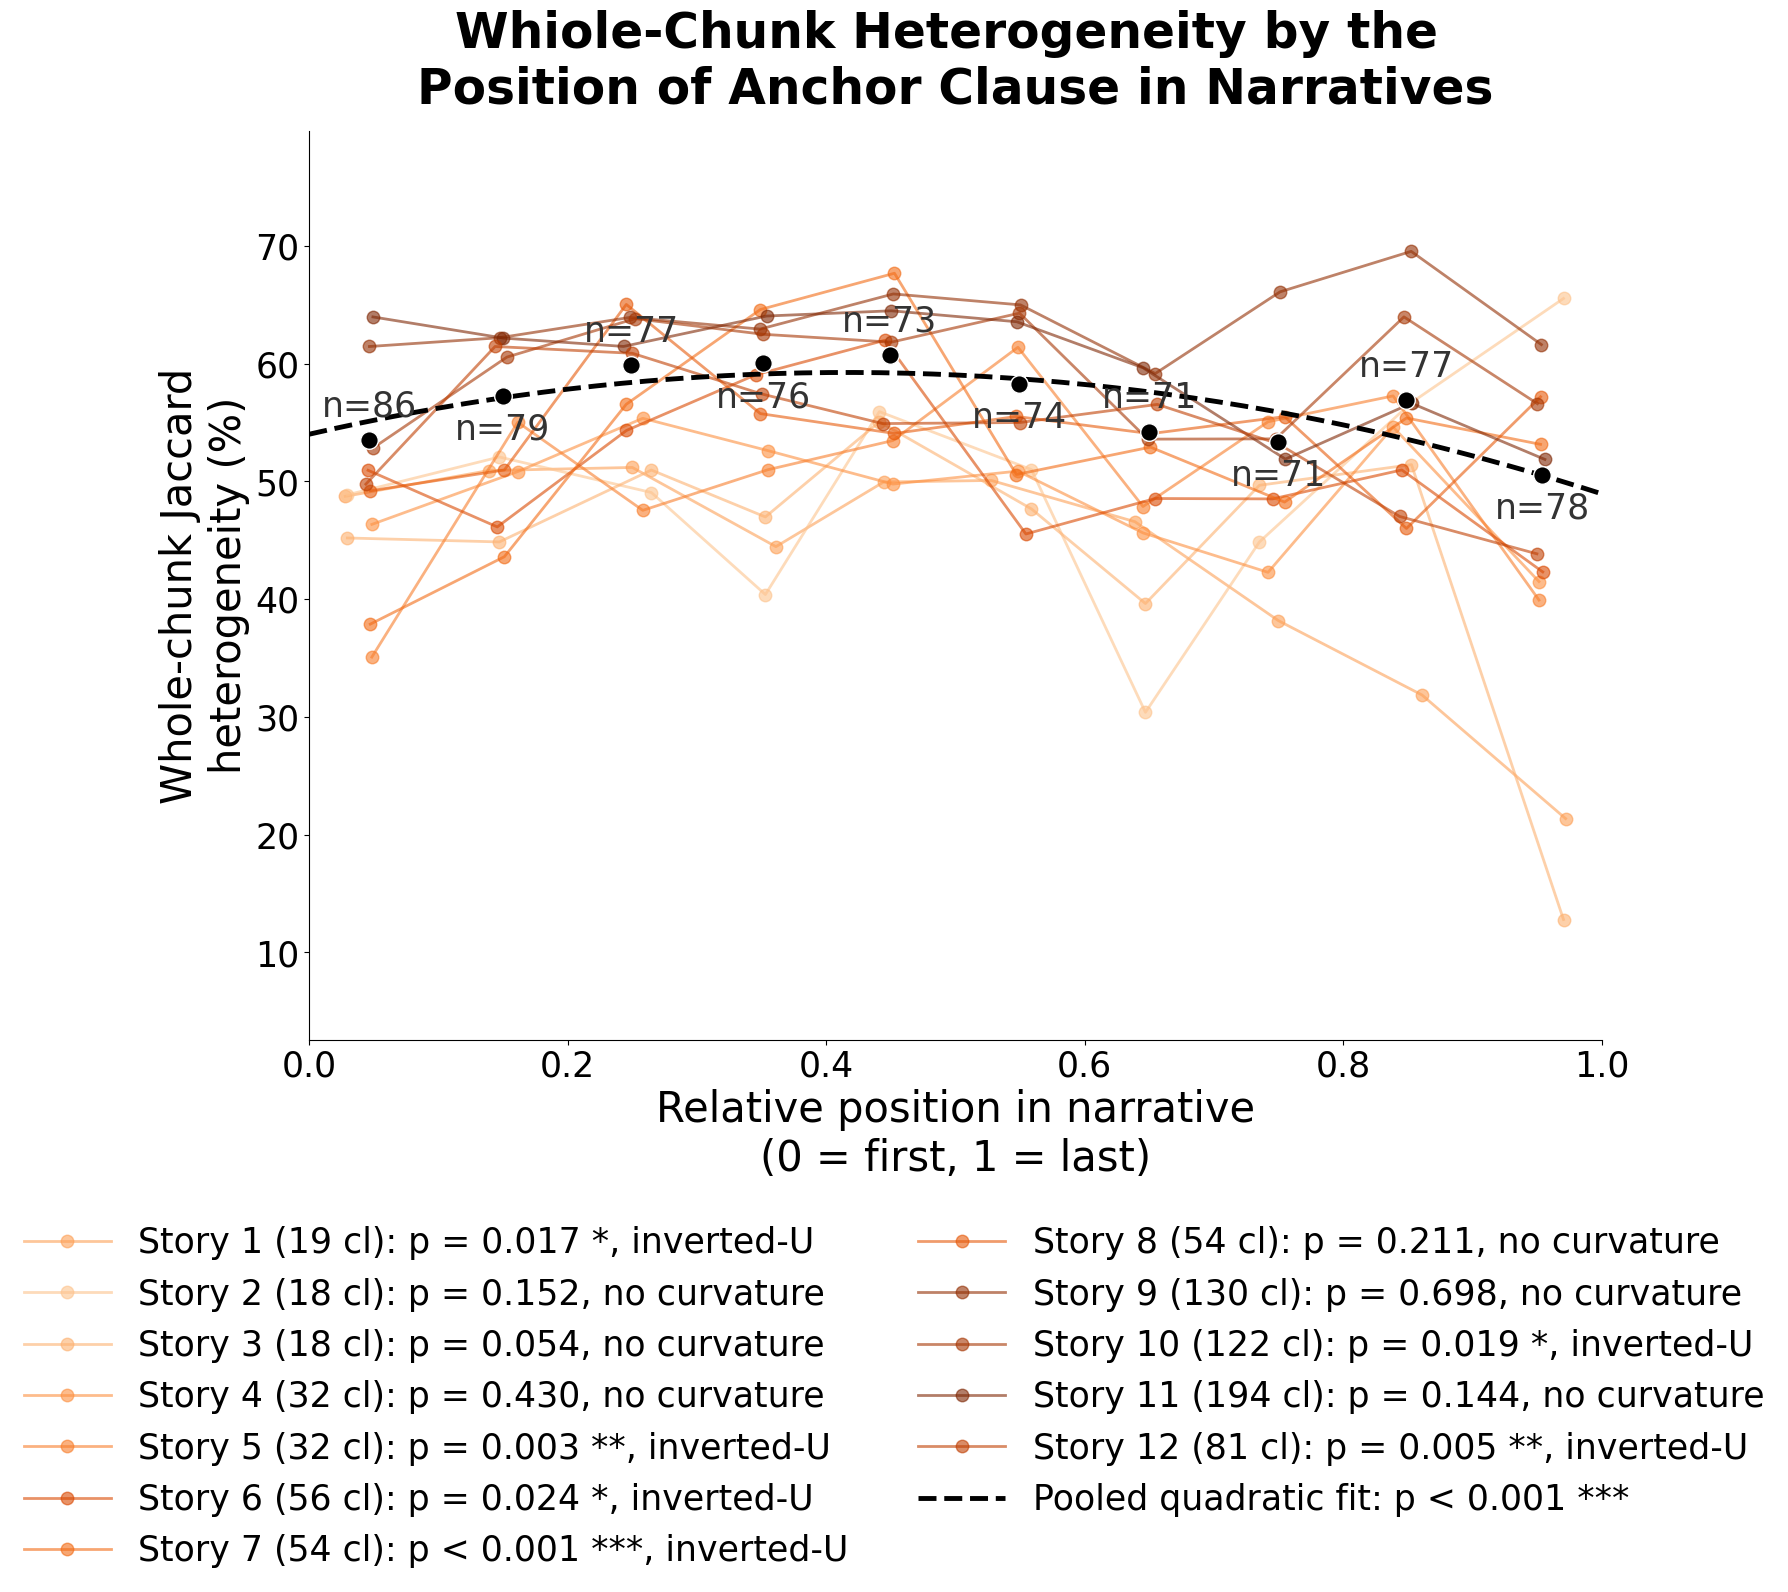

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib import cm

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_tick, fs_legend, fs_n = 35, 30, 25, 25, 25

n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)

total_clauses_per_story = np.array([len(story_processed_all[i]) for i in range(12)])
length_rank = np.argsort(np.argsort(total_clauses_per_story))
orange_colors = cm.Oranges(np.linspace(0.3, 1.0, 12))

def p_label_str(p):
    if p < 0.001: return "p < 0.001 ***"
    elif p < 0.01: return f"p = {p:.3f} **"
    elif p < 0.05: return f"p = {p:.3f} *"
    else: return f"p = {p:.3f}"

def test_quadratic_shape(relative_positions, heterogeneity_values):
    x = np.array(relative_positions, dtype=float)
    y = np.array(heterogeneity_values, dtype=float)
    X = np.column_stack([x, x**2])
    X = sm.add_constant(X)
    model_fit = sm.OLS(y, X).fit()
    b1, b2 = model_fit.params[1], model_fit.params[2]
    p_linear, p_quad = model_fit.pvalues[1], model_fit.pvalues[2]
    return b1, p_linear, b2, p_quad, model_fit


# ── compute everything per story, pool ALL pairs across stories ─────────────
story_entries = []
pooled_x_all = []
pooled_y_all = []

for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    het_per_clause = compute_chunk_jaccard_heterogeneity_per_clause(clause_dicts_all[story_index], n_clauses)

    clause_indices = sorted(het_per_clause.keys())
    heterogeneity_values = np.array([het_per_clause[c] for c in clause_indices], dtype=float)
    relative_positions = np.array(
        [(c - 1) / (n_clauses - 1) if n_clauses > 1 else 0.0 for c in clause_indices]
    )

    valid_mask = ~np.isnan(heterogeneity_values)
    x_raw = relative_positions[valid_mask]
    y_raw = heterogeneity_values[valid_mask]

    if len(x_raw) < 5:
        quad_str = "p n/a (too few clauses)"
    else:
        b1, p_linear, b2, p_quad, model_fit = test_quadratic_shape(x_raw, y_raw)
        if p_quad < 0.05:
            shape_label = "inverted-U" if b2 < 0 else "U-shape"
        else:
            shape_label = "no curvature"
        quad_str = f"{p_label_str(p_quad)}, {shape_label}"

    bin_indices = np.clip(np.digitize(x_raw, bin_edges) - 1, 0, n_bins - 1) if len(x_raw) else np.array([])
    bin_mean_x, bin_mean_y = [], []
    for b in range(n_bins):
        mask = bin_indices == b
        if mask.sum() == 0:
            continue
        bin_mean_x.append(x_raw[mask].mean())
        bin_mean_y.append(y_raw[mask].mean())

    story_entries.append({
        "story_index": story_index,
        "n_clauses": n_clauses,
        "bin_mean_x": bin_mean_x,
        "bin_mean_y": bin_mean_y,
        "quad_str": quad_str,
        "color": orange_colors[length_rank[story_index]],
    })

    pooled_x_all.extend(x_raw.tolist())
    pooled_y_all.extend(y_raw.tolist())

pooled_x_all = np.array(pooled_x_all)
pooled_y_all = np.array(pooled_y_all)

# ── pooled quadratic fit + re-binned points, over ALL pairs from ALL stories ──
pooled_bin_edges = np.linspace(0, 1, n_bins + 1)
pooled_bin_indices = np.clip(np.digitize(pooled_x_all, pooled_bin_edges) - 1, 0, n_bins - 1)

pooled_bin_mean_x, pooled_bin_mean_y, pooled_bin_n = [], [], []
for b in range(n_bins):
    mask = pooled_bin_indices == b
    if mask.sum() == 0:
        continue
    pooled_bin_mean_x.append(pooled_x_all[mask].mean())
    pooled_bin_mean_y.append(pooled_y_all[mask].mean())
    pooled_bin_n.append(mask.sum())

b1_pool, p_linear_pool, b2_pool, p_quad_pool, pooled_model_fit = test_quadratic_shape(pooled_x_all, pooled_y_all)

x_fit = np.linspace(0, 1, 200)
X_fit = sm.add_constant(np.column_stack([x_fit, x_fit**2]))
y_fit = pooled_model_fit.predict(X_fit)

print(f"Pooled quadratic fit over all {len(pooled_x_all)} points from {len(story_entries)} stories: "
      f"b2={b2_pool:.3f}, {p_label_str(p_quad_pool)}")

peak_idx = np.argmax(y_fit)
print(f"Peak of fitted curve: x = {x_fit[peak_idx]:.3f}, y = {y_fit[peak_idx]:.3f}")
print(f"Left end (x=0):  y = {y_fit[0]:.3f}")
print(f"Right end (x=1): y = {y_fit[-1]:.3f}")

print("\nPooled bin means (n_bins = 10):")
for x, y, n in zip(pooled_bin_mean_x, pooled_bin_mean_y, pooled_bin_n):
    print(f"  x = {x:.3f}, mean y = {y:.3f}, n = {n}")

# ── plot: one figure, all story curves together + pooled quadratic fit ──────
fig, ax = plt.subplots(figsize=(15, 12))

for entry in story_entries:
    ax.plot(entry["bin_mean_x"], entry["bin_mean_y"], marker="o", markersize=9, linewidth=2,
            color=entry["color"], alpha=0.6,
            label=f"Story {entry['story_index']+1} ({entry['n_clauses']} cl): {entry['quad_str']}")

ax.scatter(pooled_bin_mean_x, pooled_bin_mean_y, s=160, color="black", zorder=5,
           edgecolor="white", linewidth=1)
for k, (x, y, n) in enumerate(zip(pooled_bin_mean_x, pooled_bin_mean_y, pooled_bin_n)):
    above = (k % 2 == 0)                          # alternate above / below
    ax.annotate(f"n={n}", (x, y), textcoords="offset points",
                xytext=(0, 12 if above else -12), va='bottom' if above else 'top',
                fontsize=fs_n, ha="center", color="#333333", zorder=6)

ax.plot(x_fit, y_fit, '--', linewidth=3.5, color="black", zorder=4,
        label=f"Pooled quadratic fit: {p_label_str(p_quad_pool)}")

ax.set_xlabel("Relative position in narrative\n(0 = first, 1 = last)", fontsize=fs_label)
ax.set_ylabel("Whole-chunk Jaccard\nheterogeneity (%)", fontsize=fs_label)
ax.set_xlim(0, 1)

# adapt y-axis to the data range (extra padding for the n= labels)
all_y_vals = np.concatenate([entry["bin_mean_y"] for entry in story_entries] + [pooled_bin_mean_y])
y_min, y_max = all_y_vals.min(), all_y_vals.max()
y_pad = (y_max - y_min) * 0.18
ax.set_ylim(max(0, y_min - y_pad), y_max + y_pad)

ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=fs_tick)

ax.set_title("Whiole-Chunk Heterogeneity by the \nPosition of Anchor Clause in Narratives",
             fontsize=fs_title, fontweight='bold', pad=20)

plt.tight_layout()

# legend beneath the plot (2 columns)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, fontsize=fs_legend, loc='upper center',
           bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False,
           columnspacing=2.0, handlelength=2.5)

plt.savefig("per_clause_heterogeneity_single_figure_bin10.png", dpi=150, bbox_inches='tight')
plt.show()


## 2.2.2. sensitivity test of different bin sizes.

In [30]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

bin_sizes_to_test = [5, 8, 10, 15, 20, 30]

# ── cache raw (unbinned) relative_position / heterogeneity per story, once ──
story_raw_data = {}
for story_index in range(12):
    n_clauses = len(story_processed_all[story_index])
    het_per_clause = compute_chunk_jaccard_heterogeneity_per_clause(clause_dicts_all[story_index], n_clauses)

    clause_indices = sorted(het_per_clause.keys())
    heterogeneity_values = np.array([het_per_clause[c] for c in clause_indices], dtype=float)
    relative_positions = np.array(
        [(c - 1) / (n_clauses - 1) if n_clauses > 1 else 0.0 for c in clause_indices]
    )

    valid_mask = ~np.isnan(heterogeneity_values)
    x_raw = relative_positions[valid_mask]
    y_raw = heterogeneity_values[valid_mask]

    if len(x_raw) < 5:
        continue
    story_raw_data[story_index] = (x_raw, y_raw)

def quad_p_on_raw(x, y):
    if len(x) < 5:
        return np.nan
    X = sm.add_constant(np.column_stack([x, x**2]))
    return sm.OLS(y, X).fit().pvalues[2]   # p for x^2 term

def quad_p_on_binned(x, y, n_bins):
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
    bx, by = [], []
    for b in range(n_bins):
        mask = idx == b
        if mask.sum() == 0:
            continue
        bx.append(x[mask].mean())
        by.append(y[mask].mean())
    bx, by = np.array(bx), np.array(by)
    if len(bx) < 5:
        return np.nan
    X = sm.add_constant(np.column_stack([bx, bx**2]))
    return sm.OLS(by, X).fit().pvalues[2]

def fmt_p(p):
    if np.isnan(p):
        return "n/a"
    stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    return f"{p:.4g}{stars}"

# ── build results table ─────────────────────────────────────────────────
rows = []
for story_index, (x, y) in story_raw_data.items():
    row = {"story": f"Story {story_index+1}", "n_points": len(x), "unbinned data": fmt_p(quad_p_on_raw(x, y))}
    for nb in bin_sizes_to_test:
        row[f"p_bins={nb}"] = fmt_p(quad_p_on_binned(x, y, nb))
    rows.append(row)

# pooled across all stories
pooled_x = np.concatenate([v[0] for v in story_raw_data.values()])
pooled_y = np.concatenate([v[1] for v in story_raw_data.values()])
pooled_row = {"story": "POOLED (all stories)", "n_points": len(pooled_x), "unbinned data": fmt_p(quad_p_on_raw(pooled_x, pooled_y))}
for nb in bin_sizes_to_test:
    pooled_row[f"p_bins={nb}"] = fmt_p(quad_p_on_binned(pooled_x, pooled_y, nb))
rows.append(pooled_row)

sensitivity_table_quad = pd.DataFrame(rows)
sensitivity_table_quad


,story,n_points,unbinned data,p_bins=5,p_bins=8,p_bins=10,p_bins=15,p_bins=20,p_bins=30
0,Story 1,19,0.01706*,0.07585,0.07884,0.001375**,0.03862*,0.01706*,0.01706*
1,Story 2,18,0.1522,0.4666,0.4266,0.1347,0.1734,0.1522,0.1522
2,Story 3,18,0.0535,0.01387*,0.01614*,0.05618,0.1655,0.0535,0.0535
3,Story 4,32,0.43,0.6775,0.283,0.2976,0.29,0.4964,0.3668
4,Story 5,32,0.002714**,0.09108,0.05054,0.03404*,0.04308*,0.03888*,0.01755*
5,Story 6,56,0.02417*,0.1988,0.2277,0.1465,0.1379,0.06244,0.07059
6,Story 7,54,0.0008163***,0.2873,0.09828,0.06959,0.01458*,0.008881**,0.005935**
7,Story 8,54,0.2105,0.2772,0.3917,0.4208,0.2099,0.2686,0.225
8,Story 9,123,0.6977,0.7904,0.6161,0.6268,0.8683,0.855,0.7153
9,Story 10,122,0.0192*,0.6972,0.3089,0.2838,0.1913,0.1928,0.162


## 3. Finding proportion of each chunk type by abstraction score.

In [20]:
import ast
import re

integration_score_prompt_template = """
********************Instructions******************************

You will be given pairs of: a recalled clause from a memory experiment, and the narrative clauses it was matched to. The recalled clause covers the meaning of all the corresponding narrative clauses.

For each pair, rate how the recalled clause relates to its covered narrative clauses, on a continuous scale from 0 to 2:

- 0 = Redundancy removal: the covered narrative clauses are parallel, near-duplicate, or highly similar statements, and the recalled clause is simply a restatement of that repeated content (no real combination of distinct information).
- 1 = Integration: the covered narrative clauses contain distinct pieces of information, and the recalled clause break the original clauses down and recombine them together into one statement, while staying at the same level of detail/specificity as the originals.
- 2 = Abstraction: the recalled clause goes beyond simply combining the covered narrative clauses -- it re-expresses their content as a higher-level, more general or abstract representation (a summary concept) rather than restating their specific details.
                   
Also, distinguish incomplete recall with important piece of information lost, and abstraction of the full meaning into a higher representation. The incomplete recall should not be given a score of 2, but be recognized as a partial integration with a score between 0-1.

The score can be any continuous value between 0 and 2 (not just the integers 0, 1, 2) to reflect intermediate cases.

Return only a valid Python dictionary mapping each recalled clause's number to its score, e.g. {"1": 0.5, "2": 1.8}. Do not include explanations, headings, or Markdown code fences.

************** Narrative, broken down into numbered clauses: ******************
<<NARRATIVE_SEGMENTATION>>

************** Recall, broken down into numbered clauses: ******************
<<RECALL_SEGMENTATION>>

**********************Pairs to score: ************************
<<PAIRS>>

"""

def build_narrative_segmentation(clauses):
    return "\n".join(f"{i+1}. {clause}" for i, clause in enumerate(clauses))


def build_integration_score_prompt(story_index, participant_index):
    clause_dict = clause_dicts_all[story_index][participant_index]
    if clause_dict is None:
        return None

    recall_clauses    = recall_processed_all[story_index][participant_index]
    narrative_clauses = story_processed_all[story_index]

    narrative_segmentation = build_narrative_segmentation(narrative_clauses)
    recall_segmentation    = build_narrative_segmentation(recall_clauses)

    pair_blocks = []
    for recall_idx, narrative_indices in clause_dict.items():
        if not (1 <= recall_idx <= len(recall_clauses)):
            continue
        valid_narrative_indices = [i for i in narrative_indices if 1 <= i <= len(narrative_clauses)]
        if len(valid_narrative_indices) <= 1:
            continue   # only chunks with size > 1 are sent to GPT

        recall_text = recall_clauses[recall_idx - 1]
        narrative_lines = "\n".join(
            f"     - [{i}] \"{narrative_clauses[i - 1]}\"" for i in valid_narrative_indices
        )
        pair_blocks.append(
            f"Recalled clause [{recall_idx}]: \"{recall_text}\"\n   Narrative clauses covered:\n{narrative_lines}"
        )

    if not pair_blocks:
        return None

    pairs_text = "\n\n".join(pair_blocks)
    prompt = integration_score_prompt_template.replace("<<NARRATIVE_SEGMENTATION>>", narrative_segmentation)
    prompt = prompt.replace("<<RECALL_SEGMENTATION>>", recall_segmentation)
    prompt = prompt.replace("<<PAIRS>>", pairs_text)
    return prompt


def safe_parse_score_dict(raw_text):
    """Extract a Python dict literal from GPT's response and parse it into {int: float}."""
    text = raw_text.strip()
    text = re.sub(r"^```(?:python)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    try:
        result = ast.literal_eval(text)
    except (SyntaxError, ValueError):
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match:
            result = ast.literal_eval(match.group(0))
        else:
            raise

    if not isinstance(result, dict):
        raise ValueError(f"Parsed object is not a dict: {type(result)}")

    parsed = {}
    for k, v in result.items():
        if v is None:
            continue
        try:
            int_k   = int(k)
            float_v = float(v)
        except (ValueError, TypeError):
            continue
        parsed[int_k] = float_v
    return parsed


def apply_single_clause_rule(scores, clause_dict, narrative_clauses):
    """Force score=0 for any recall clause matched to only one narrative clause,
    overriding whatever GPT returned for it."""
    corrected = {}
    for recall_idx, score in scores.items():
        narrative_indices = clause_dict.get(recall_idx, [])
        valid_narrative_indices = [i for i in narrative_indices if 1 <= i <= len(narrative_clauses)]
        corrected[recall_idx] = 0.0 if len(valid_narrative_indices) <= 1 else score
    return corrected


# ── build prompts for every participant, every story ──────────────────────────
integration_score_prompts_all = []
for story_index in range(12):
    story_prompts = []
    for participant_index in range(len(clause_dicts_all[story_index])):
        story_prompts.append(build_integration_score_prompt(story_index, participant_index))
    integration_score_prompts_all.append(story_prompts)

print(integration_score_prompts_all[0][0])



********************Instructions******************************

You will be given pairs of: a recalled clause from a memory experiment, and the narrative clauses it was matched to. The recalled clause covers the meaning of all the corresponding narrative clauses.

For each pair, rate how the recalled clause relates to its covered narrative clauses, on a continuous scale from 0 to 2:

- 0 = Redundancy removal: the covered narrative clauses are parallel, near-duplicate, or highly similar statements, and the recalled clause is simply a restatement of that repeated content (no real combination of distinct information).
- 1 = Integration: the covered narrative clauses contain distinct pieces of information, and the recalled clause break the original clauses down and recombine them together into one statement, while staying at the same level of detail/specificity as the originals.
- 2 = Abstraction: the recalled clause goes beyond simply combining the covered narrative clauses -- it re-expr

##### Test the prompt with a few participants.

In [58]:
integration_score_raw_all = [[None] * len(integration_score_prompts_all[s]) for s in range(12)]

test_story_index    = 3
n_test_participants = 5

for p in range(n_test_participants):
    prompt = integration_score_prompts_all[test_story_index][p]
    if prompt is None:
        print(f"Story {test_story_index}: participant {p + 1}/{n_test_participants} has no multi-clause chunks, skipping.")
        continue

    out_full = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=temp
    )
    integration_score_raw_all[test_story_index][p] = out_full.choices[0].message.content
    print(f"Story {test_story_index}: participant {p + 1}/{n_test_participants} done.")

print(f"Story {test_story_index} finished — {n_test_participants} total.\n")


Story 3: participant 1/5 done.
Story 3: participant 2/5 done.
Story 3: participant 3/5 done.
Story 3: participant 4/5 done.
Story 3: participant 5/5 done.
Story 3 finished — 5 total.



In [16]:
import ast
import re

def safe_parse_score_dict(raw_text):
    """Same defensive parsing as safe_parse_clause_dict, but values are floats (scores), not lists."""
    text = raw_text.strip()
    text = re.sub(r"^```(?:python)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    try:
        result = ast.literal_eval(text)
    except (SyntaxError, ValueError):
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match:
            result = ast.literal_eval(match.group(0))
        else:
            raise

    if not isinstance(result, dict):
        raise ValueError(f"Parsed object is not a dict: {type(result)}")

    parsed = {}
    for k, v in result.items():
        if v is None:
            continue
        try:
            int_k   = int(k)
            float_v = float(v)
        except (ValueError, TypeError):
            continue
        parsed[int_k] = float_v
    return parsed




In [ ]:
narrative_clauses = story_processed_all[test_story_index]

for p in range(n_test_participants):
    raw = integration_score_raw_all[test_story_index][p]
    if raw is None:
        print(f"Participant {p}: no result.")
        continue

    try:
        scores = safe_parse_score_dict(raw)
    except (SyntaxError, ValueError) as e:
        print(f"Participant {p}: failed to parse -- {e}")
        continue

    clause_dict    = clause_dicts_all[test_story_index][p]
    recall_clauses = recall_processed_all[test_story_index][p]

    print(f"=== Participant {p} ===")
    for recall_idx, score in scores.items():
        if not (1 <= recall_idx <= len(recall_clauses)):
            continue
        narrative_indices = clause_dict.get(recall_idx, [])
        valid_narrative_indices = [i for i in narrative_indices if 1 <= i <= len(narrative_clauses)]

        recall_text = recall_clauses[recall_idx - 1]
        print(f"  Recall [{recall_idx}]: \"{recall_text}\"  -> score = {score:.2f}")
        for n_idx in valid_narrative_indices:
            print(f"      Narrative [{n_idx}]: \"{narrative_clauses[n_idx - 1]}\"")
    print()


### run through the full dataset.

In [14]:
import time

integration_score_raw_all = [[None] * len(integration_score_prompts_all[s]) for s in range(12)]

start_time      = time.time()
checkpoint_time = start_time
total_done      = 0

for story_index in range(12):
    n_participants = len(integration_score_prompts_all[story_index])

    for p in range(n_participants):
        prompt = integration_score_prompts_all[story_index][p]
        if prompt is None:
            continue

        out_full = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
            temperature=temp
        )
        integration_score_raw_all[story_index][p] = out_full.choices[0].message.content

        total_done += 1
        if total_done % 20 == 0:
            now = time.time()
            interval = now - checkpoint_time
            elapsed  = now - start_time
            checkpoint_time = now
            print(f"  [{total_done} participants scored total] +{interval:.1f}s for this batch, "
                  f"{elapsed/60:.1f} min elapsed")

    print(f"Story {story_index} finished — {n_participants} total participants checked.\n")

print(f"\nAll done. {total_done} participants scored in {(time.time()-start_time)/60:.1f} minutes total.")


  [20 participants scored total] +33.9s for this batch, 0.6 min elapsed
  [40 participants scored total] +12.0s for this batch, 0.8 min elapsed
  [60 participants scored total] +12.2s for this batch, 1.0 min elapsed
  [80 participants scored total] +12.1s for this batch, 1.2 min elapsed
Story 0 finished — 100 total participants checked.

  [100 participants scored total] +12.1s for this batch, 1.4 min elapsed
  [120 participants scored total] +11.7s for this batch, 1.6 min elapsed
  [140 participants scored total] +11.4s for this batch, 1.8 min elapsed
Story 1 finished — 56 total participants checked.

  [160 participants scored total] +11.8s for this batch, 2.0 min elapsed
  [180 participants scored total] +11.6s for this batch, 2.1 min elapsed
  [200 participants scored total] +12.2s for this batch, 2.4 min elapsed
  [220 participants scored total] +12.3s for this batch, 2.6 min elapsed
Story 2 finished — 100 total participants checked.

  [240 participants scored total] +12.8s for t

In [15]:
import json

with open("integration_score_raw_all.json", "w", encoding="utf-8") as f:
    json.dump(integration_score_raw_all, f, ensure_ascii=False, indent=2)

print(f"Saved integration_score_raw_all to integration_score_raw_all.json "
      f"({total_done} participants scored).")


Saved integration_score_raw_all to integration_score_raw_all.json (1082 participants scored).


In [18]:
import json

with open("integration_score_raw_all.json", "r", encoding="utf-8") as f:
    integration_score_raw_all = json.load(f)


In [16]:
import numpy as np

def apply_single_clause_rule(scores, clause_dict, narrative_clauses):
    """Force score=0 for any recall clause matched to only one narrative clause,
    overriding whatever GPT returned for it."""
    corrected = {}
    for recall_idx, score in scores.items():
        narrative_indices = clause_dict.get(recall_idx, [])
        valid_narrative_indices = [i for i in narrative_indices if 1 <= i <= len(narrative_clauses)]
        corrected[recall_idx] = 0.0 if len(valid_narrative_indices) <= 1 else score
    return corrected

integration_score_mean_per_story = []

for story_index in range(12):
    narrative_clauses = story_processed_all[story_index]
    participant_means = []

    for participant_index in range(len(integration_score_raw_all[story_index])):
        raw = integration_score_raw_all[story_index][participant_index]
        if raw is None:
            continue

        try:
            scores = safe_parse_score_dict(raw)
        except (SyntaxError, ValueError) as e:
            print(f"Story {story_index}, participant {participant_index}: failed to parse -- {e}")
            continue

        clause_dict = clause_dicts_all[story_index][participant_index]
        if clause_dict is None:
            continue

        scores = apply_single_clause_rule(scores, clause_dict, narrative_clauses)

        if scores:
            participant_means.append(np.mean(list(scores.values())))

    story_mean = np.mean(participant_means) if participant_means else np.nan
    integration_score_mean_per_story.append(story_mean)
    print(f"Story {story_index+1}: mean integration score = {story_mean:.3f} "
          f"(from {len(participant_means)} participants)")


Story 1: mean integration score = 1.086 (from 96 participants)
Story 2: mean integration score = 1.062 (from 48 participants)
Story 3: mean integration score = 0.929 (from 93 participants)
Story 4: mean integration score = 1.021 (from 94 participants)
Story 5: mean integration score = 0.981 (from 95 participants)
Story 6: mean integration score = 1.046 (from 99 participants)
Story 7: mean integration score = 1.018 (from 93 participants)
Story 8: mean integration score = 1.133 (from 96 participants)
Story 9: mean integration score = 1.270 (from 90 participants)
Story 10: mean integration score = 0.739 (from 100 participants)
Story 11: mean integration score = 1.094 (from 90 participants)
Story 12: mean integration score = 1.157 (from 88 participants)


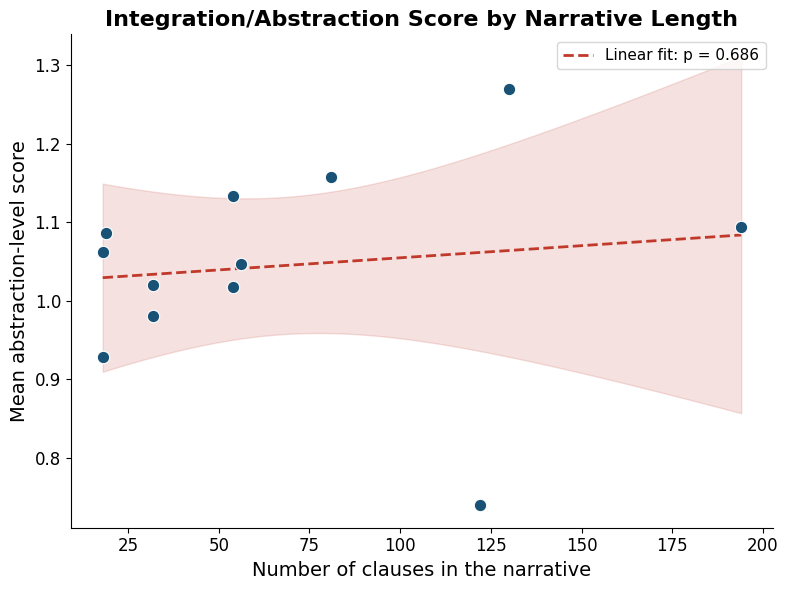

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

story_lengths = [len(story_processed_all[i]) for i in range(12)]

X = sm.add_constant(story_lengths)
model_fit = sm.OLS(integration_score_mean_per_story, X, missing='drop').fit()
p_value = model_fit.pvalues[1]

x_reg = np.linspace(min(story_lengths), max(story_lengths), 200)
X_reg = sm.add_constant(x_reg)
pred = model_fit.get_prediction(X_reg).summary_frame(alpha=0.05)

def p_label_str(p):
    if p < 0.001:
        return "p < 0.001 ***"
    elif p < 0.01:
        return f"p = {p:.3f} **"
    elif p < 0.05:
        return f"p = {p:.3f} *"
    else:
        return f"p = {p:.3f}"

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(story_lengths, integration_score_mean_per_story, color='#1a5276', s=80,
           edgecolor='white', linewidth=0.8, zorder=3)
ax.plot(x_reg, pred['mean'], '--', color='#c0392b', lw=2, zorder=2,
        label=f"Linear fit: {p_label_str(p_value)}")
ax.fill_between(x_reg, pred['mean_ci_lower'], pred['mean_ci_upper'], color='#c0392b', alpha=0.15, zorder=1)

ax.set_xlabel("Number of clauses in the narrative", fontsize=14)
ax.set_ylabel("Mean abstraction-level score", fontsize=14)
ax.set_title("Integration/Abstraction Score by Narrative Length", fontsize=16, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig("integration_score_by_story_length.png", dpi=150, bbox_inches='tight')
plt.show()


## 3.2. composition of the three chunk types.

In [21]:
import numpy as np

prop0_score_mean_per_story = []
prop1_score_mean_per_story = []
prop2_score_mean_per_story = []

for story_index in range(12):
    narrative_clauses = story_processed_all[story_index]
    p0_list, p1_list, p2_list = [], [], []

    for participant_index in range(len(integration_score_raw_all[story_index])):
        raw = integration_score_raw_all[story_index][participant_index]
        if raw is None:
            continue

        try:
            scores = safe_parse_score_dict(raw)
        except (SyntaxError, ValueError) as e:
            print(f"Story {story_index}, participant {participant_index}: failed to parse -- {e}")
            continue

        clause_dict = clause_dicts_all[story_index][participant_index]
        if clause_dict is None:
            continue

        scores = apply_single_clause_rule(scores, clause_dict, narrative_clauses)
        if not scores:
            continue

        # round half up (0.5 -> 1, 1.5 -> 2), clipped to the 0-2 range
        rounded = np.clip(np.floor(np.array(list(scores.values())) + 0.5), 0, 2)

        p0_list.append(np.mean(rounded == 0))
        p1_list.append(np.mean(rounded == 1))
        p2_list.append(np.mean(rounded == 2))

    mean_p0 = np.mean(p0_list) if p0_list else np.nan
    mean_p1 = np.mean(p1_list) if p1_list else np.nan
    mean_p2 = np.mean(p2_list) if p2_list else np.nan

    prop0_score_mean_per_story.append(mean_p0)
    prop1_score_mean_per_story.append(mean_p1)
    prop2_score_mean_per_story.append(mean_p2)

    print(f"Story {story_index+1}: prop(score≈0)={mean_p0:.3f}, prop(score≈1)={mean_p1:.3f}, "
          f"prop(score≈2)={mean_p2:.3f}  (from {len(p0_list)} participants)")


Story 1: prop(score≈0)=0.050, prop(score≈1)=0.593, prop(score≈2)=0.357  (from 96 participants)
Story 2: prop(score≈0)=0.047, prop(score≈1)=0.577, prop(score≈2)=0.376  (from 48 participants)
Story 3: prop(score≈0)=0.051, prop(score≈1)=0.701, prop(score≈2)=0.248  (from 93 participants)
Story 4: prop(score≈0)=0.035, prop(score≈1)=0.675, prop(score≈2)=0.290  (from 94 participants)
Story 5: prop(score≈0)=0.069, prop(score≈1)=0.646, prop(score≈2)=0.285  (from 95 participants)
Story 6: prop(score≈0)=0.060, prop(score≈1)=0.593, prop(score≈2)=0.347  (from 99 participants)
Story 7: prop(score≈0)=0.052, prop(score≈1)=0.625, prop(score≈2)=0.324  (from 93 participants)
Story 8: prop(score≈0)=0.035, prop(score≈1)=0.527, prop(score≈2)=0.438  (from 96 participants)
Story 9: prop(score≈0)=0.018, prop(score≈1)=0.425, prop(score≈2)=0.557  (from 90 participants)
Story 10: prop(score≈0)=0.167, prop(score≈1)=0.675, prop(score≈2)=0.158  (from 100 participants)
Story 11: prop(score≈0)=0.023, prop(score≈1)=0.6

In [23]:
import math
import numpy as np

clause_story = [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]

score_se = [   # (label, SE list per story)
    ("Score ≈ 0", prop0_score_se_per_story),
    ("Score ≈ 1", prop1_score_se_per_story),
    ("Score ≈ 2", prop2_score_se_per_story),
]

for label, se_list in score_se:
    # keep story number and clause count with each SE; drop missing values
    rows = [(s + 1, clause_story[s], float(se)) for s, se in enumerate(se_list)
            if se is not None and not math.isnan(float(se))]
    rows.sort(key=lambda r: r[2])                     # min to max

    print("=" * 60)
    if not rows:
        print(f"{label}: no SE values")
        continue
    se_vals = np.array([r[2] for r in rows])
    print(f"{label}  ({len(rows)} narratives)   SE as proportion (× 100 = percentage points)")
    print(f"  min = {se_vals.min():.4f}, max = {se_vals.max():.4f}, "
          f"mean = {se_vals.mean():.4f}, median = {np.median(se_vals):.4f}")
    print(f"  {'rank':>4} {'story':>6} {'clauses':>8} {'SE':>8}")
    for rank, (story, n_clauses, se) in enumerate(rows, start=1):
        print(f"  {rank:>4} {story:>6} {n_clauses:>8} {se:>8.4f}")


Score ≈ 0  (12 narratives)   SE as proportion (× 100 = percentage points)
  min = 0.0053, max = 0.0295, mean = 0.0147, median = 0.0132
  rank  story  clauses       SE
     1      9      130   0.0053
     2     12       81   0.0058
     3     11      194   0.0066
     4      7       54   0.0121
     5      6       56   0.0126
     6      4       32   0.0130
     7      8       54   0.0134
     8      3       18   0.0180
     9      1       19   0.0188
    10     10      122   0.0198
    11      5       32   0.0219
    12      2       18   0.0295
Score ≈ 1  (12 narratives)   SE as proportion (× 100 = percentage points)
  min = 0.0208, max = 0.0550, mean = 0.0296, median = 0.0283
  rank  story  clauses       SE
     1      6       56   0.0208
     2     10      122   0.0215
     3      8       54   0.0259
     4      9      130   0.0268
     5      4       32   0.0279
     6      1       19   0.0281
     7     11      194   0.0285
     8      7       54   0.0285
     9     12       81   0

Source  ddof1  ddof2          F        p-unc    p-GG-corr      ng2      eps  sphericity  W-spher  p-spher
 score      2     22 108.168449 4.145199e-12 6.936131e-08 0.907694 0.583854       False 0.287243 0.001955
        A         B          T        p-unc       p-corr sig    hedges
Score ≈ 0 Score ≈ 1 -28.969352 9.750024e-12 2.925007e-11 *** -8.949641
Score ≈ 0 Score ≈ 2  -7.696232 9.420338e-06 2.826101e-05 *** -3.736766
Score ≈ 1 Score ≈ 2   5.273374 2.629496e-04 7.888488e-04 ***  2.862705


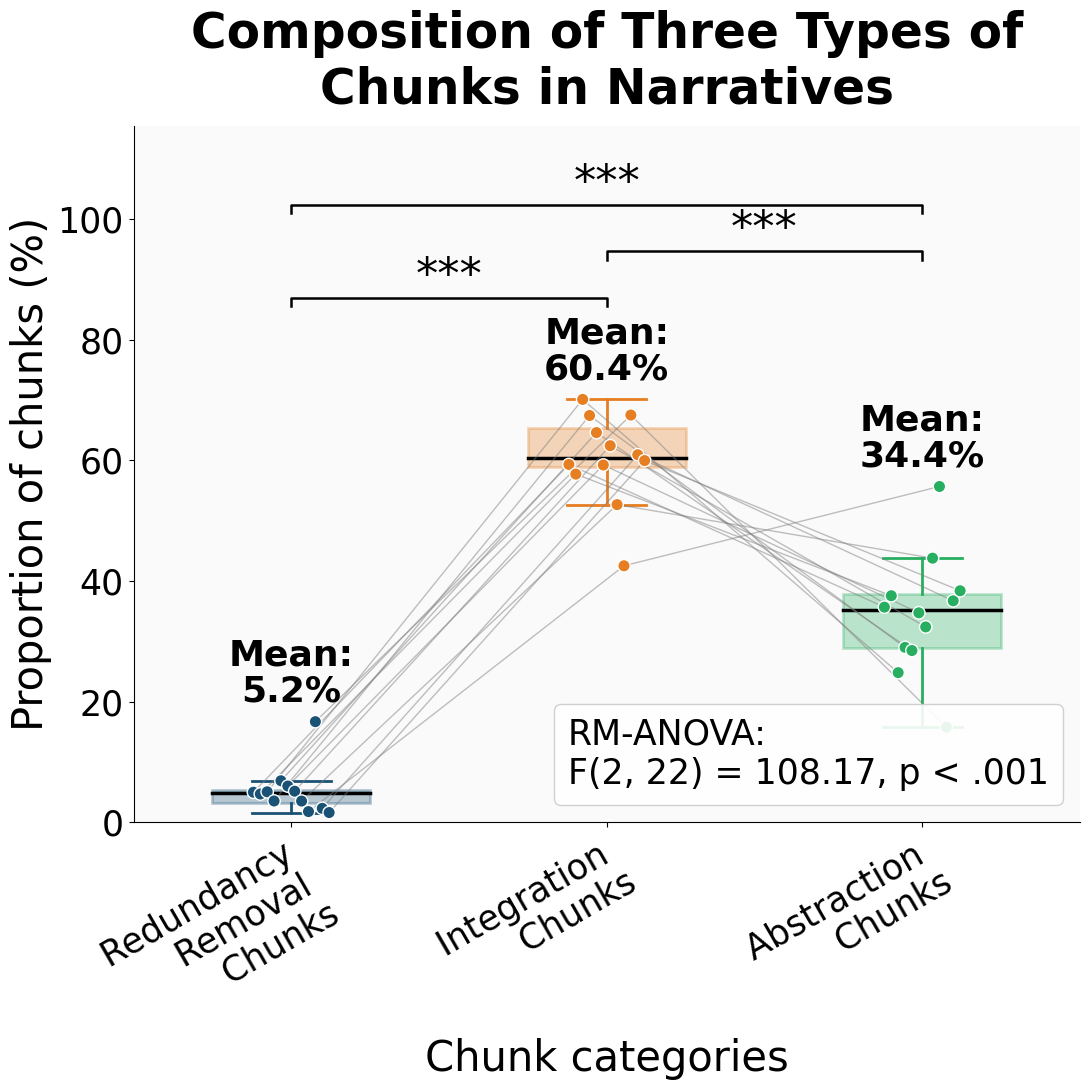

In [21]:
import numpy as np
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_mean, fs_legend, fs_star = 35, 30, 25, 25, 26, 25, 32

# (label, per-narrative proportion of chunks [0-1], color)
score_specs = [
    ("Score ≈ 0", prop0_score_mean_per_story, '#1a5276'),
    ("Score ≈ 1", prop1_score_mean_per_story, '#e67e22'),
    ("Score ≈ 2", prop2_score_mean_per_story, '#27ae60'),
]
# tick labels shown on the x-axis (same order as score_specs)
tick_labels = ["Redundancy \nRemoval \nChunks", "Integration \nChunks", "Abstraction \nChunks"]

n_stories = 12
names     = [s[0] for s in score_specs]
data      = [100 * np.array(s[1][:n_stories], dtype=float) for s in score_specs]   # in %
colors    = [s[2] for s in score_specs]
positions = np.arange(len(score_specs))

# ── repeated measures ANOVA + post-hoc tests ──────────────────────────────────
df = pd.DataFrame([{'story': s, 'score': name, 'prop': d[s]}
                   for name, d in zip(names, data) for s in range(n_stories)
                   if not np.isnan(d[s])])
aov = pg.rm_anova(data=df, dv='prop', within='score', subject='story')
print(aov.to_string(index=False))

F_val, p_val = aov['F'].iloc[0], aov['p-unc'].iloc[0]
df1, df2     = aov['ddof1'].iloc[0], aov['ddof2'].iloc[0]
p_text    = "p < .001" if p_val < 0.001 else f"p = {p_val:.3f}"
aov_label = f"RM-ANOVA:\nF({df1:.0f}, {df2:.0f}) = {F_val:.2f}, {p_text}"

posthoc = pg.pairwise_tests(data=df, dv='prop', within='score',
                            subject='story', padjust='bonf', effsize='hedges')

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

posthoc['sig'] = posthoc['p-corr'].apply(add_stars)
print(posthoc[['A', 'B', 'T', 'p-unc', 'p-corr', 'sig', 'hedges']].to_string(index=False))

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 11))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box, written above its highest point
y_max_all = max(np.nanmax(d) for d in data)
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.03 * y_max_all, f"Mean:\n{v.mean():.1f}%",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6, linespacing=1.1)

# dots per narrative, connected only between adjacent boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    for i in range(len(data) - 1):
        if not (np.isnan(ys[i]) or np.isnan(ys[i + 1])):
            ax.plot(xs[i:i + 2], ys[i:i + 2], color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# ── significance brackets for all pairs (Bonferroni-corrected) ────────────────
idx = {n: i for i, n in enumerate(names)}
pairs = posthoc.copy()
pairs['i'] = [min(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs['j'] = [max(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs = pairs.assign(span=pairs['j'] - pairs['i']).sort_values(['span', 'i'])

base = y_max_all * 1.24          # first bracket level, above the two-line mean labels
step = y_max_all * 0.11          # vertical distance between bracket levels
tick = y_max_all * 0.02          # length of the bracket's downward ends
levels = []
for _, row in pairs.iterrows():
    i, j = int(row['i']), int(row['j'])
    lvl = next((L for L, occ in enumerate(levels)
                if all(j < a or i > b for a, b in occ)), len(levels))
    if lvl == len(levels):
        levels.append([])
    levels[lvl].append((i - 0.1, j + 0.1))
    y = base + lvl * step
    ax.plot([i, i, j, j], [y - tick, y, y, y - tick], color='black', lw=1.8, zorder=6)
    ax.text((i + j) / 2, y, row['sig'], ha='center', va='bottom',
            fontsize=fs_star, color='black', zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, fontsize=fs_xtick, rotation=30, ha='right',
                   rotation_mode='anchor', linespacing=1.1)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_xlabel('Chunk categories', fontsize=fs_label, labelpad=0)
ax.set_ylabel('Proportion of chunks (%)', fontsize=fs_label)
ax.set_title('Composition of Three Types of\nChunks in Narratives',
             fontsize=fs_title, fontweight='bold', pad=16)
ax.set_ylim(0, base + max(len(levels), 1) * step + step * 0.7)
ax.spines[['top', 'right']].set_visible(False)

# ANOVA result as a legend, lower right
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[aov_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig('integration_score_boxplot.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()



## 3.3. Similarity Range of Narrative Clauses covered in a Chunk

In [35]:
import json

with open("clause_scoring_dicts_all.json", "r", encoding="utf-8") as f:
    loaded = json.load(f)

clause_dicts_all_raw = [
    [{int(k): v for k, v in d.items()} if d is not None else None for d in story_dicts]
    for story_dicts in loaded
]

clause_dicts_all = []
for story_index in range(12):
    story_dicts = clause_dicts_all_raw[story_index]
    n_dicts = len(story_dicts)
    n_embs  = len(recall_emb_all[story_index])

    if n_dicts != n_embs:
        n_keep = min(n_dicts, n_embs)
        print(f"Story {story_index+1}: MISALIGNED -- clause_dicts n={n_dicts}, recall_emb n={n_embs}. "
              f"Dropping {n_dicts - n_keep} entries to align to length {n_keep}.")
        story_dicts = story_dicts[:n_keep]
    else:
        print(f"Story {story_index+1}: aligned ({n_dicts} entries).")

    clause_dicts_all.append(story_dicts)


Story 1: aligned (100 entries).
Story 2: aligned (56 entries).
Story 3: aligned (100 entries).
Story 4: aligned (100 entries).
Story 5: aligned (101 entries).
Story 6: aligned (100 entries).
Story 7: aligned (98 entries).
Story 8: aligned (100 entries).
Story 9: aligned (99 entries).
Story 10: aligned (100 entries).
Story 11: aligned (93 entries).
Story 12: aligned (95 entries).


In [36]:
import numpy as np
from scipy.spatial.distance import cosine

mean_similarity_per_story = []

for story_index in range(12):
    narrative_embs = story_emb_all[story_index]   # index i -> clause i+1

    participant_means = []
    skipped = 0

    for participant_index, clause_dict in enumerate(clause_dicts_all[story_index]):
        if clause_dict is None or len(clause_dict) == 0:
            continue

        try:
            recall_embs = recall_emb_all[story_index][participant_index]   # index i -> clause i+1
        except IndexError:
            skipped += 1
            continue   # mismatched case -- removed

        recall_clause_sims = []
        for recall_idx, narrative_indices in clause_dict.items():
            if not (1 <= recall_idx <= len(recall_embs)):
                continue
            valid_narrative_indices = [n for n in narrative_indices if 1 <= n <= len(narrative_embs)]
            if not valid_narrative_indices:
                continue

            recall_emb = recall_embs[recall_idx - 1]
            sims = [1 - cosine(recall_emb, narrative_embs[n - 1]) for n in valid_narrative_indices]
            recall_clause_sims.append(np.mean(sims))

        if recall_clause_sims:
            participant_means.append(np.mean(recall_clause_sims))

    story_mean = np.mean(participant_means) if participant_means else np.nan
    mean_similarity_per_story.append(story_mean)
    print(f"Story {story_index+1}: mean cosine similarity = {story_mean:.3f} "
          f"(from {len(participant_means)} participants, {skipped} mismatched cases removed)")



Story 1: mean cosine similarity = 0.463 (from 99 participants, 0 mismatched cases removed)
Story 2: mean cosine similarity = 0.565 (from 56 participants, 0 mismatched cases removed)
Story 3: mean cosine similarity = 0.501 (from 100 participants, 0 mismatched cases removed)
Story 4: mean cosine similarity = 0.437 (from 100 participants, 0 mismatched cases removed)
Story 5: mean cosine similarity = 0.442 (from 100 participants, 0 mismatched cases removed)
Story 6: mean cosine similarity = 0.414 (from 100 participants, 0 mismatched cases removed)
Story 7: mean cosine similarity = 0.439 (from 98 participants, 0 mismatched cases removed)
Story 8: mean cosine similarity = 0.425 (from 100 participants, 0 mismatched cases removed)
Story 9: mean cosine similarity = 0.367 (from 98 participants, 0 mismatched cases removed)
Story 10: mean cosine similarity = 0.232 (from 100 participants, 0 mismatched cases removed)
Story 11: mean cosine similarity = 0.415 (from 93 participants, 0 mismatched cases 

In [41]:
import numpy as np
from scipy.spatial.distance import cosine

max_similarity_per_story = []

for story_index in range(12):
    narrative_embs = story_emb_all[story_index]   # index i -> clause i+1

    participant_means = []

    for participant_index, clause_dict in enumerate(clause_dicts_all[story_index]):
        if clause_dict is None or len(clause_dict) == 0:
            continue

        recall_embs = recall_emb_all[story_index][participant_index]   # index i -> clause i+1

        recall_clause_sims = []
        for recall_idx, narrative_indices in clause_dict.items():
            if not (1 <= recall_idx <= len(recall_embs)):
                continue
            valid_narrative_indices = [n for n in narrative_indices if 1 <= n <= len(narrative_embs)]
            if not valid_narrative_indices:
                continue

            recall_emb = recall_embs[recall_idx - 1]
            sims = [1 - cosine(recall_emb, narrative_embs[n - 1]) for n in valid_narrative_indices]
            recall_clause_sims.append(np.max(sims))

        if recall_clause_sims:
            participant_means.append(np.mean(recall_clause_sims))

    story_mean = np.mean(participant_means) if participant_means else np.nan
    max_similarity_per_story.append(story_mean)
    print(f"Story {story_index+1}: mean of max cosine similarity = {story_mean:.3f} "
          f"(from {len(participant_means)} participants)")


Story 1: mean of max cosine similarity = 0.515 (from 99 participants)
Story 2: mean of max cosine similarity = 0.597 (from 56 participants)
Story 3: mean of max cosine similarity = 0.542 (from 100 participants)
Story 4: mean of max cosine similarity = 0.478 (from 100 participants)
Story 5: mean of max cosine similarity = 0.482 (from 100 participants)
Story 6: mean of max cosine similarity = 0.489 (from 100 participants)
Story 7: mean of max cosine similarity = 0.483 (from 98 participants)
Story 8: mean of max cosine similarity = 0.468 (from 100 participants)
Story 9: mean of max cosine similarity = 0.415 (from 98 participants)
Story 10: mean of max cosine similarity = 0.455 (from 100 participants)
Story 11: mean of max cosine similarity = 0.451 (from 93 participants)
Story 12: mean of max cosine similarity = 0.418 (from 94 participants)


In [61]:
import numpy as np
from scipy.spatial.distance import cosine

min_similarity_per_story = []

for story_index in range(12):
    narrative_embs = story_emb_all[story_index]   # index i -> clause i+1

    participant_means = []

    for participant_index, clause_dict in enumerate(clause_dicts_all[story_index]):
        if clause_dict is None or len(clause_dict) == 0:
            continue

        recall_embs = recall_emb_all[story_index][participant_index]   # index i -> clause i+1

        recall_clause_sims = []
        for recall_idx, narrative_indices in clause_dict.items():
            if not (1 <= recall_idx <= len(recall_embs)):
                continue
            valid_narrative_indices = [n for n in narrative_indices if 1 <= n <= len(narrative_embs)]
            if not valid_narrative_indices:
                continue

            recall_emb = recall_embs[recall_idx - 1]
            sims = [1 - cosine(recall_emb, narrative_embs[n - 1]) for n in valid_narrative_indices]
            recall_clause_sims.append(np.min(sims))

        if recall_clause_sims:
            participant_means.append(np.mean(recall_clause_sims))

    story_mean = np.mean(participant_means) if participant_means else np.nan
    min_similarity_per_story.append(story_mean)
    print(f"Story {story_index+1}: mean of min cosine similarity = {story_mean:.3f} "
          f"(from {len(participant_means)} participants)")


Story 1: mean of min cosine similarity = 0.414 (from 99 participants)
Story 2: mean of min cosine similarity = 0.534 (from 56 participants)
Story 3: mean of min cosine similarity = 0.462 (from 100 participants)
Story 4: mean of min cosine similarity = 0.397 (from 100 participants)
Story 5: mean of min cosine similarity = 0.403 (from 100 participants)
Story 6: mean of min cosine similarity = 0.344 (from 100 participants)
Story 7: mean of min cosine similarity = 0.396 (from 98 participants)
Story 8: mean of min cosine similarity = 0.383 (from 100 participants)
Story 9: mean of min cosine similarity = 0.322 (from 98 participants)
Story 10: mean of min cosine similarity = 0.286 (from 100 participants)
Story 11: mean of min cosine similarity = 0.381 (from 93 participants)
Story 12: mean of min cosine similarity = 0.306 (from 94 participants)


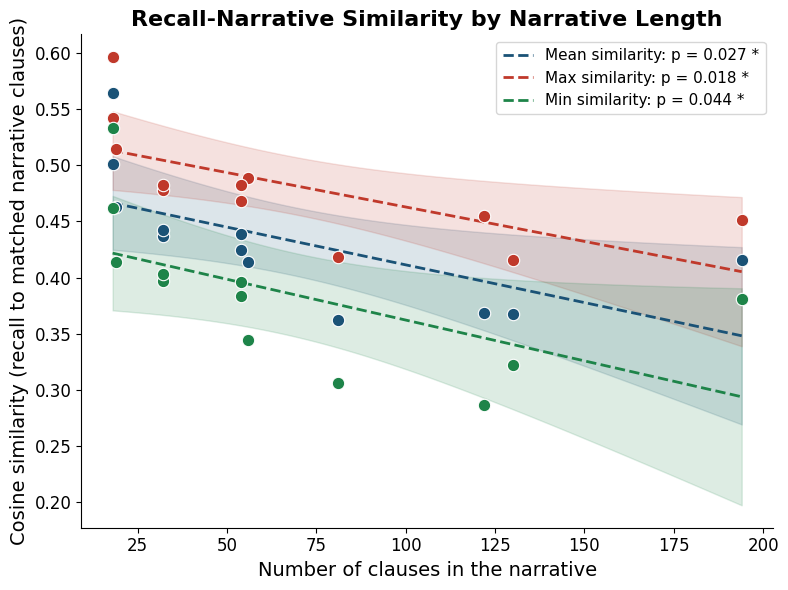

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

story_lengths = [len(story_processed_all[i]) for i in range(12)]

def fit_ols(y_values, x_values):
    X = sm.add_constant(x_values)
    model_fit = sm.OLS(y_values, X, missing='drop').fit()
    p_value = model_fit.pvalues[1]

    x_reg = np.linspace(min(x_values), max(x_values), 200)
    X_reg = sm.add_constant(x_reg)
    pred = model_fit.get_prediction(X_reg).summary_frame(alpha=0.05)
    return x_reg, pred, p_value

def p_label_str(p):
    if p < 0.001:
        return "p < 0.001 ***"
    elif p < 0.01:
        return f"p = {p:.3f} **"
    elif p < 0.05:
        return f"p = {p:.3f} *"
    else:
        return f"p = {p:.3f}"

x_reg_mean, pred_mean, p_mean = fit_ols(mean_similarity_per_story, story_lengths)
x_reg_max,  pred_max,  p_max  = fit_ols(max_similarity_per_story, story_lengths)
x_reg_min,  pred_min,  p_min  = fit_ols(min_similarity_per_story, story_lengths)

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(story_lengths, mean_similarity_per_story, color='#1a5276', s=80,
           edgecolor='white', linewidth=0.8, zorder=3)
ax.plot(x_reg_mean, pred_mean['mean'], '--', color='#1a5276', lw=2, zorder=2,
        label=f"Mean similarity: {p_label_str(p_mean)}")
ax.fill_between(x_reg_mean, pred_mean['mean_ci_lower'], pred_mean['mean_ci_upper'],
                color='#1a5276', alpha=0.15, zorder=1)

ax.scatter(story_lengths, max_similarity_per_story, color='#c0392b', s=80,
           edgecolor='white', linewidth=0.8, zorder=3)
ax.plot(x_reg_max, pred_max['mean'], '--', color='#c0392b', lw=2, zorder=2,
        label=f"Max similarity: {p_label_str(p_max)}")
ax.fill_between(x_reg_max, pred_max['mean_ci_lower'], pred_max['mean_ci_upper'],
                color='#c0392b', alpha=0.15, zorder=1)

ax.scatter(story_lengths, min_similarity_per_story, color='#1e8449', s=80,
           edgecolor='white', linewidth=0.8, zorder=3)
ax.plot(x_reg_min, pred_min['mean'], '--', color='#1e8449', lw=2, zorder=2,
        label=f"Min similarity: {p_label_str(p_min)}")
ax.fill_between(x_reg_min, pred_min['mean_ci_lower'], pred_min['mean_ci_upper'],
                color='#1e8449', alpha=0.15, zorder=1)

ax.set_xlabel("Number of clauses in the narrative", fontsize=14)
ax.set_ylabel("Cosine similarity (recall to matched narrative clauses)", fontsize=14)
ax.set_title("Recall-Narrative Similarity by Narrative Length", fontsize=16, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig("similarity_combined_by_story_length.png", dpi=150, bbox_inches='tight')
plt.show()


### 3.4. Pure extraction and real chunk proportion. and the mean chunk size.

In [23]:
fanin_per_participant_all = []   # baseline: as-is, includes 0-length matches
fanin_mean_all = []

fanin_per_participant_excl0 = []   # excludes chunk size == 0
fanin_mean_excl0 = []

fanin_per_participant_excl01 = []  # excludes chunk size == 0 and == 1
fanin_mean_excl01 = []

for story_index in range(12):
    story_dicts = clause_dicts_all[story_index]

    participant_fanins        = []
    participant_fanins_excl0  = []
    participant_fanins_excl01 = []

    for p, d in enumerate(story_dicts):
        if d is None or len(d) == 0:
            continue

        list_lengths = [len(v) for v in d.values()]   # number of narrative indices matched to each recall key

        # ── as-is: everything included ───────────────────────────────────────
        participant_fanin = np.mean(list_lengths)
        participant_fanins.append(participant_fanin)

        # ── excluding chunk size == 0 ─────────────────────────────────────────
        lengths_excl0 = [n for n in list_lengths if n != 0]
        if lengths_excl0:
            participant_fanins_excl0.append(np.mean(lengths_excl0))

        # ── excluding chunk size == 0 and == 1 ────────────────────────────────
        lengths_excl01 = [n for n in list_lengths if n not in (0, 1)]
        if lengths_excl01:
            participant_fanins_excl01.append(np.mean(lengths_excl01))

    fanin_per_participant_all.append(participant_fanins)
    mean_fanin = np.mean(participant_fanins) if participant_fanins else np.nan
    fanin_mean_all.append(mean_fanin)

    fanin_per_participant_excl0.append(participant_fanins_excl0)
    mean_fanin_excl0 = np.mean(participant_fanins_excl0) if participant_fanins_excl0 else np.nan
    fanin_mean_excl0.append(mean_fanin_excl0)

    fanin_per_participant_excl01.append(participant_fanins_excl01)
    mean_fanin_excl01 = np.mean(participant_fanins_excl01) if participant_fanins_excl01 else np.nan
    fanin_mean_excl01.append(mean_fanin_excl01)

    print(f"Story {story_index}: mean fan-in = {mean_fanin:.3f} (all, n={len(participant_fanins)}), "
          f"{mean_fanin_excl0:.3f} (excl. 0, n={len(participant_fanins_excl0)}), "
          f"{mean_fanin_excl01:.3f} (excl. 0 & 1, n={len(participant_fanins_excl01)})")


Story 0: mean fan-in = 1.684 (all, n=99), 1.700 (excl. 0, n=99), 2.703 (excl. 0 & 1, n=96)
Story 1: mean fan-in = 1.593 (all, n=56), 1.595 (excl. 0, n=56), 2.690 (excl. 0 & 1, n=48)
Story 2: mean fan-in = 1.460 (all, n=100), 1.460 (excl. 0, n=100), 2.221 (excl. 0 & 1, n=93)
Story 3: mean fan-in = 1.534 (all, n=100), 1.535 (excl. 0, n=100), 2.416 (excl. 0 & 1, n=94)
Story 4: mean fan-in = 1.565 (all, n=100), 1.568 (excl. 0, n=100), 2.433 (excl. 0 & 1, n=95)
Story 5: mean fan-in = 2.111 (all, n=100), 2.124 (excl. 0, n=100), 2.629 (excl. 0 & 1, n=99)
Story 6: mean fan-in = 1.553 (all, n=98), 1.559 (excl. 0, n=98), 2.310 (excl. 0 & 1, n=93)
Story 7: mean fan-in = 1.557 (all, n=100), 1.560 (excl. 0, n=100), 2.359 (excl. 0 & 1, n=96)
Story 8: mean fan-in = 1.863 (all, n=98), 1.865 (excl. 0, n=98), 2.673 (excl. 0 & 1, n=92)
Story 9: mean fan-in = 2.240 (all, n=100), 2.253 (excl. 0, n=100), 2.747 (excl. 0 & 1, n=100)
Story 10: mean fan-in = 1.465 (all, n=93), 1.485 (excl. 0, n=93), 2.286 (excl

In [24]:
import math
import numpy as np

clause_story = [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]

def mean_and_se(values):
    """Mean and SE across participants (SE = SD / sqrt(n), ddof=1)."""
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    se = values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
    return values.mean(), se

fanin_per_participant_all = []   # baseline: as-is, includes 0-length matches
fanin_mean_all = []
fanin_se_all   = []

fanin_per_participant_excl0 = []   # excludes chunk size == 0
fanin_mean_excl0 = []
fanin_se_excl0   = []

fanin_per_participant_excl01 = []  # excludes chunk size == 0 and == 1
fanin_mean_excl01 = []
fanin_se_excl01   = []

for story_index in range(12):
    story_dicts = clause_dicts_all[story_index]

    participant_fanins        = []
    participant_fanins_excl0  = []
    participant_fanins_excl01 = []

    for p, d in enumerate(story_dicts):
        if d is None or len(d) == 0:
            continue

        list_lengths = [len(v) for v in d.values()]   # number of narrative indices matched to each recall key

        # ── as-is: everything included ───────────────────────────────────────
        participant_fanin = np.mean(list_lengths)
        participant_fanins.append(participant_fanin)

        # ── excluding chunk size == 0 ─────────────────────────────────────────
        lengths_excl0 = [n for n in list_lengths if n != 0]
        if lengths_excl0:
            participant_fanins_excl0.append(np.mean(lengths_excl0))

        # ── excluding chunk size == 0 and == 1 ────────────────────────────────
        lengths_excl01 = [n for n in list_lengths if n not in (0, 1)]
        if lengths_excl01:
            participant_fanins_excl01.append(np.mean(lengths_excl01))

    fanin_per_participant_all.append(participant_fanins)
    mean_fanin, se_fanin = mean_and_se(participant_fanins)
    fanin_mean_all.append(mean_fanin)
    fanin_se_all.append(se_fanin)

    fanin_per_participant_excl0.append(participant_fanins_excl0)
    mean_fanin_excl0, se_fanin_excl0 = mean_and_se(participant_fanins_excl0)
    fanin_mean_excl0.append(mean_fanin_excl0)
    fanin_se_excl0.append(se_fanin_excl0)

    fanin_per_participant_excl01.append(participant_fanins_excl01)
    mean_fanin_excl01, se_fanin_excl01 = mean_and_se(participant_fanins_excl01)
    fanin_mean_excl01.append(mean_fanin_excl01)
    fanin_se_excl01.append(se_fanin_excl01)

    print(f"Story {story_index}: mean fan-in = {mean_fanin:.3f} ± {se_fanin:.3f} (all, n={len(participant_fanins)}), "
          f"{mean_fanin_excl0:.3f} ± {se_fanin_excl0:.3f} (excl. 0, n={len(participant_fanins_excl0)}), "
          f"{mean_fanin_excl01:.3f} ± {se_fanin_excl01:.3f} (excl. 0 & 1, n={len(participant_fanins_excl01)})")

# ── SE range per version, min to max ─────────────────────────────────────────
fanin_se = [   # (label, SE list per story)
    ("Fan-in, all chunk sizes",          fanin_se_all),
    ("Fan-in, excluding size 0",         fanin_se_excl0),
    ("Fan-in, excluding sizes 0 and 1",  fanin_se_excl01),
]

for label, se_list in fanin_se:
    rows = [(s + 1, clause_story[s], float(se)) for s, se in enumerate(se_list)
            if se is not None and not math.isnan(float(se))]
    rows.sort(key=lambda r: r[2])                     # min to max

    print("=" * 60)
    if not rows:
        print(f"{label}: no SE values")
        continue
    se_vals = np.array([r[2] for r in rows])
    print(f"{label}  ({len(rows)} narratives)   SE in clauses")
    print(f"  min = {se_vals.min():.4f}, max = {se_vals.max():.4f}, "
          f"mean = {se_vals.mean():.4f}, median = {np.median(se_vals):.4f}")
    print(f"  {'rank':>4} {'story':>6} {'clauses':>8} {'SE':>8}")
    for rank, (story, n_clauses, se) in enumerate(rows, start=1):
        print(f"  {rank:>4} {story:>6} {n_clauses:>8} {se:>8.4f}")


Story 0: mean fan-in = 1.684 ± 0.053 (all, n=99), 1.700 ± 0.052 (excl. 0, n=99), 2.703 ± 0.099 (excl. 0 & 1, n=96)
Story 1: mean fan-in = 1.593 ± 0.196 (all, n=56), 1.595 ± 0.195 (excl. 0, n=56), 2.690 ± 0.205 (excl. 0 & 1, n=48)
Story 2: mean fan-in = 1.460 ± 0.050 (all, n=100), 1.460 ± 0.050 (excl. 0, n=100), 2.221 ± 0.053 (excl. 0 & 1, n=93)
Story 3: mean fan-in = 1.534 ± 0.049 (all, n=100), 1.535 ± 0.050 (excl. 0, n=100), 2.416 ± 0.051 (excl. 0 & 1, n=94)
Story 4: mean fan-in = 1.565 ± 0.068 (all, n=100), 1.568 ± 0.068 (excl. 0, n=100), 2.433 ± 0.082 (excl. 0 & 1, n=95)
Story 5: mean fan-in = 2.111 ± 0.066 (all, n=100), 2.124 ± 0.066 (excl. 0, n=100), 2.629 ± 0.055 (excl. 0 & 1, n=99)
Story 6: mean fan-in = 1.553 ± 0.045 (all, n=98), 1.559 ± 0.045 (excl. 0, n=98), 2.310 ± 0.035 (excl. 0 & 1, n=93)
Story 7: mean fan-in = 1.557 ± 0.047 (all, n=100), 1.560 ± 0.047 (excl. 0, n=100), 2.359 ± 0.041 (excl. 0 & 1, n=96)
Story 8: mean fan-in = 1.863 ± 0.101 (all, n=98), 1.865 ± 0.101 (excl.

Source  ddof1  ddof2          F        p-unc      ng2      eps
  cond      2     22 221.133821 2.705185e-15 0.729291 0.500911
      A           B          T        p-unc       p-corr sig    hedges
    All     Excl. 0  -3.917572 2.402844e-03 7.208531e-03  ** -0.028233
    All Excl. 0 & 1 -15.016550 1.126506e-08 3.379517e-08 *** -3.395545
Excl. 0 Excl. 0 & 1 -14.734929 1.374740e-08 4.124221e-08 *** -3.343718


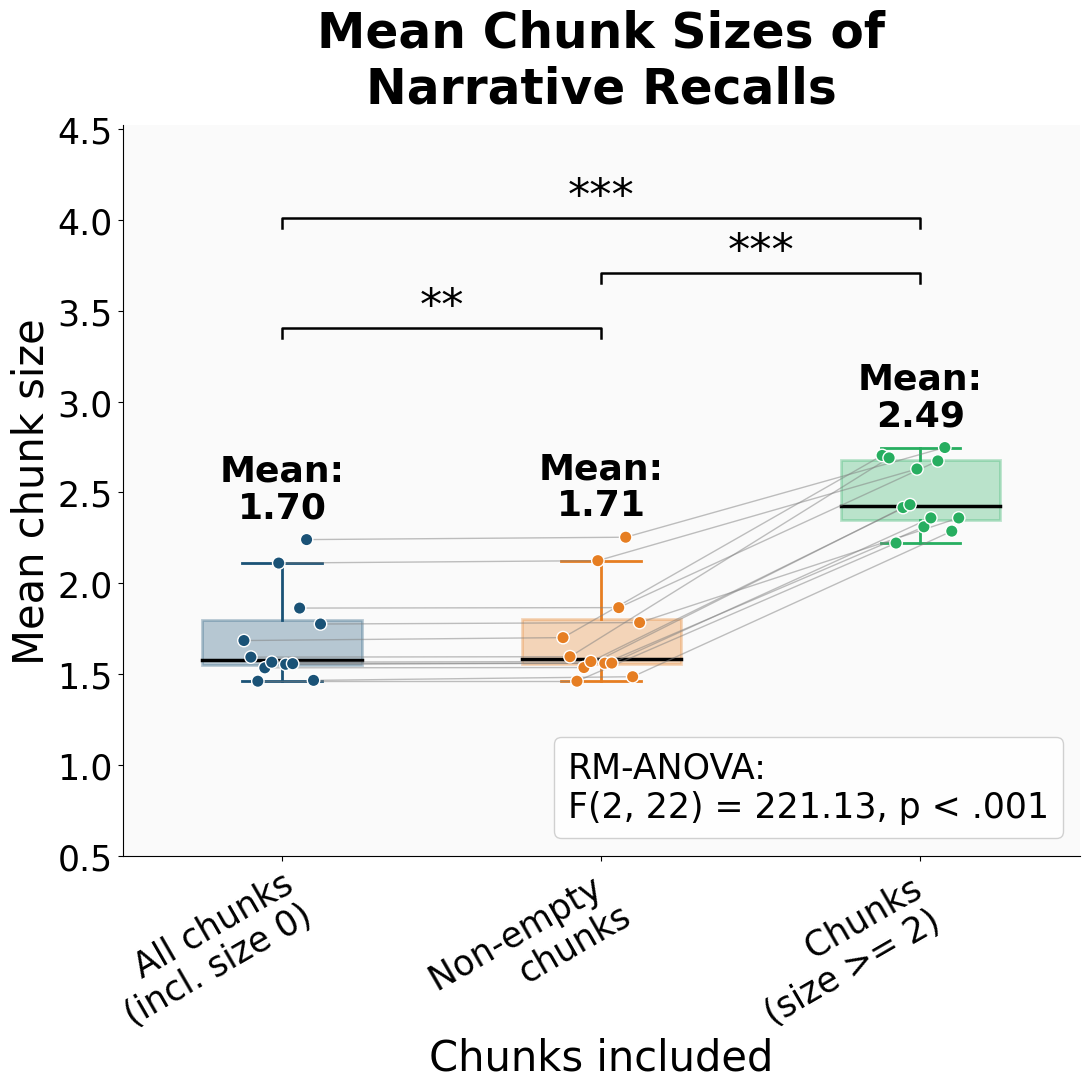

In [28]:
import numpy as np
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_mean, fs_legend, fs_star = 35, 30, 25, 25, 26, 25, 32

# (internal name, per-narrative mean fan-in, color)
fanin_specs = [
    ("All",          fanin_mean_all,    '#1a5276'),
    ("Excl. 0",      fanin_mean_excl0,  '#e67e22'),
    ("Excl. 0 & 1",  fanin_mean_excl01, '#27ae60'),
]
# tick labels shown on the x-axis (same order as fanin_specs)
tick_labels = ["All chunks\n(incl. size 0)", "Non-empty \nchunks", "Chunks \n(size >= 2) "]

n_stories = 12
names     = [s[0] for s in fanin_specs]
data      = [np.array(s[1][:n_stories], dtype=float) for s in fanin_specs]
colors    = [s[2] for s in fanin_specs]
positions = np.arange(len(fanin_specs))

# ── repeated measures ANOVA + post-hoc tests ──────────────────────────────────
df = pd.DataFrame([{'story': s, 'cond': name, 'fanin': d[s]}
                   for name, d in zip(names, data) for s in range(n_stories)
                   if not np.isnan(d[s])])
aov = pg.rm_anova(data=df, dv='fanin', within='cond', subject='story')
print(aov.to_string(index=False))

F_val, p_val = aov['F'].iloc[0], aov['p-unc'].iloc[0]
df1, df2     = aov['ddof1'].iloc[0], aov['ddof2'].iloc[0]
p_text    = "p < .001" if p_val < 0.001 else f"p = {p_val:.3f}"
aov_label = f"RM-ANOVA:\nF({df1:.0f}, {df2:.0f}) = {F_val:.2f}, {p_text}"

posthoc = pg.pairwise_tests(data=df, dv='fanin', within='cond',
                            subject='story', padjust='bonf', effsize='hedges')

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

posthoc['sig'] = posthoc['p-corr'].apply(add_stars)
print(posthoc[['A', 'B', 'T', 'p-unc', 'p-corr', 'sig', 'hedges']].to_string(index=False))

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 11))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box, written above its highest point
y_max_all = max(np.nanmax(d) for d in data)
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.03 * y_max_all, f"Mean:\n{v.mean():.2f}",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6, linespacing=1.1)

# dots per narrative, connected only between adjacent boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    for i in range(len(data) - 1):
        if not (np.isnan(ys[i]) or np.isnan(ys[i + 1])):
            ax.plot(xs[i:i + 2], ys[i:i + 2], color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# ── significance brackets for all pairs (Bonferroni-corrected) ────────────────
idx = {n: i for i, n in enumerate(names)}
pairs = posthoc.copy()
pairs['i'] = [min(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs['j'] = [max(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs = pairs.assign(span=pairs['j'] - pairs['i']).sort_values(['span', 'i'])

base = y_max_all * 1.24          # first bracket level, above the two-line mean labels
step = y_max_all * 0.11          # vertical distance between bracket levels
tick = y_max_all * 0.02          # length of the bracket's downward ends
levels = []
for _, row in pairs.iterrows():
    i, j = int(row['i']), int(row['j'])
    lvl = next((L for L, occ in enumerate(levels)
                if all(j < a or i > b for a, b in occ)), len(levels))
    if lvl == len(levels):
        levels.append([])
    levels[lvl].append((i - 0.1, j + 0.1))
    y = base + lvl * step
    ax.plot([i, i, j, j], [y - tick, y, y, y - tick], color='black', lw=1.8, zorder=6)
    ax.text((i + j) / 2, y, row['sig'], ha='center', va='bottom',
            fontsize=fs_star, color='black', zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, fontsize=fs_xtick, rotation=30, ha='right',
                   rotation_mode='anchor', linespacing=1.1)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_xlabel('Chunks included', fontsize=fs_label)
ax.set_ylabel('Mean chunk size', fontsize=fs_label)
ax.set_title('Mean Chunk Sizes of\nNarrative Recalls', fontsize=fs_title,
             fontweight='bold', pad=16)
ax.set_ylim(0.5, base + max(len(levels), 1) * step + step * 0.7)
ax.spines[['top', 'right']].set_visible(False)

# ANOVA result as a legend, lower right
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[aov_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig("mean_fanin_boxplot.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()



Non-empty chunks: n = 12 narratives, mean = 1.71, SD = 0.26, range = [1.46, 2.25]


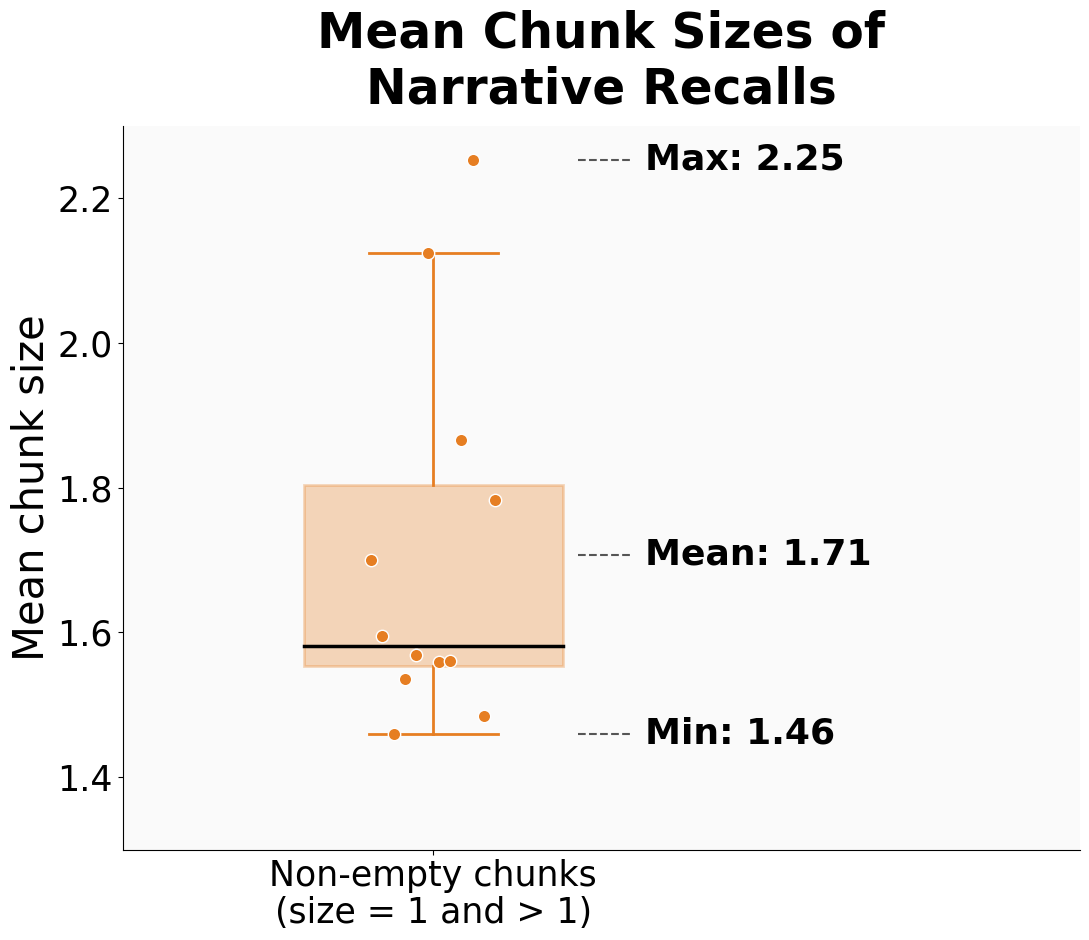

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_stat = 35, 30, 25, 25, 26

n_stories  = 12
data       = np.array(fanin_mean_excl0[:n_stories], dtype=float)   # per-narrative mean fan-in
color      = '#e67e22'
tick_label = "Non-empty chunks\n(size = 1 and > 1)"

v = data[~np.isnan(data)]
print(f"Non-empty chunks: n = {len(v)} narratives, mean = {v.mean():.2f}, "
      f"SD = {v.std(ddof=1):.2f}, range = [{v.min():.2f}, {v.max():.2f}]")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 9.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

box_w = 0.5
bp = ax.boxplot([v], positions=[0], widths=box_w, patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
bp['boxes'][0].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
for part in ('whiskers', 'caps'):
    for line in bp[part]:
        line.set(color=color, lw=2)

# one dot per narrative
offsets = np.linspace(-0.12, 0.12, n_stories)
ok = ~np.isnan(data)
ax.scatter(offsets[ok], data[ok], color=color, s=80,
           edgecolors='white', linewidths=1, zorder=5)

# ── max / mean / min labels on the right side of the box ─────────────────────
x_line0 = box_w / 2 + 0.03            # short dashed guide from the box edge ...
x_text  = box_w / 2 + 0.16            # ... to the label
for label, value in [("Max", v.max()), ("Mean", v.mean()), ("Min", v.min())]:
    ax.plot([x_line0, x_text - 0.03], [value, value], color='#555555', lw=1.5,
            ls='--', zorder=4)
    ax.text(x_text, value, f"{label}: {value:.2f}", ha='left', va='center',
            fontsize=fs_stat, fontweight='bold', color='black', zorder=6)

# axes & labels
ax.set_xticks([0])
ax.set_xticklabels([tick_label], fontsize=fs_xtick, linespacing=1.1)
ax.set_xlim(-0.6, 1.25)
ax.set_ylim(1.3, 2.3)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_ylabel('Mean chunk size', fontsize=fs_label)
ax.set_title('Mean Chunk Sizes of\nNarrative Recalls', fontsize=fs_title,
             fontweight='bold', pad=16)
pad = 0.12 * (v.max() - v.min())
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig("mean_fanin_nonempty_boxplot.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()



In [29]:
prop0_per_participant_all = []   # prop0_per_participant_all[story_index] = list of per-participant prop(size=0)
prop1_per_participant_all = []
prop2_per_participant_all = []

prop0_mean_all, prop1_mean_all, prop2_mean_all = [], [], []

for story_index in range(12):
    story_dicts = clause_dicts_all[story_index]

    p0_list, p1_list, p2_list = [], [], []

    for d in story_dicts:
        if d is None or len(d) == 0:
            continue
        list_lengths = np.array([len(v) for v in d.values()])
        total = len(list_lengths)

        p0_list.append(np.mean(list_lengths == 0))
        p1_list.append(np.mean(list_lengths == 1))
        p2_list.append(np.mean(list_lengths >= 2))

    prop0_per_participant_all.append(p0_list)
    prop1_per_participant_all.append(p1_list)
    prop2_per_participant_all.append(p2_list)

    mean_p0 = np.mean(p0_list) if p0_list else np.nan
    mean_p1 = np.mean(p1_list) if p1_list else np.nan
    mean_p2 = np.mean(p2_list) if p2_list else np.nan

    prop0_mean_all.append(mean_p0)
    prop1_mean_all.append(mean_p1)
    prop2_mean_all.append(mean_p2)

    print(f"Story {story_index}: prop(size=0)={mean_p0:.3f}, prop(size=1)={mean_p1:.3f}, "
          f"prop(size>2)={mean_p2:.3f}  (from {len(p0_list)} participants)")



Story 0: prop(size=0)=0.009, prop(size=1)=0.588, prop(size>2)=0.403  (from 99 participants)
Story 1: prop(size=0)=0.002, prop(size=1)=0.745, prop(size>2)=0.253  (from 56 participants)
Story 2: prop(size=0)=0.000, prop(size=1)=0.655, prop(size>2)=0.345  (from 100 participants)
Story 3: prop(size=0)=0.001, prop(size=1)=0.648, prop(size>2)=0.352  (from 100 participants)
Story 4: prop(size=0)=0.002, prop(size=1)=0.637, prop(size>2)=0.361  (from 100 participants)
Story 5: prop(size=0)=0.006, prop(size=1)=0.341, prop(size>2)=0.653  (from 100 participants)
Story 6: prop(size=0)=0.004, prop(size=1)=0.600, prop(size>2)=0.396  (from 98 participants)
Story 7: prop(size=0)=0.003, prop(size=1)=0.611, prop(size>2)=0.386  (from 100 participants)
Story 8: prop(size=0)=0.002, prop(size=1)=0.538, prop(size>2)=0.460  (from 98 participants)
Story 9: prop(size=0)=0.006, prop(size=1)=0.321, prop(size>2)=0.673  (from 100 participants)
Story 10: prop(size=0)=0.014, prop(size=1)=0.643, prop(size>2)=0.343  (fro

In [25]:
import math
import numpy as np

clause_story = [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]

def mean_and_se(values):
    """Mean and SE across participants (SE = SD / sqrt(n), ddof=1)."""
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    se = values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
    return values.mean(), se

prop0_per_participant_all = []   # prop0_per_participant_all[story_index] = list of per-participant prop(size=0)
prop1_per_participant_all = []
prop2_per_participant_all = []

prop0_mean_all, prop1_mean_all, prop2_mean_all = [], [], []
prop0_se_all,   prop1_se_all,   prop2_se_all   = [], [], []

for story_index in range(12):
    story_dicts = clause_dicts_all[story_index]

    p0_list, p1_list, p2_list = [], [], []

    for d in story_dicts:
        if d is None or len(d) == 0:
            continue
        list_lengths = np.array([len(v) for v in d.values()])

        p0_list.append(np.mean(list_lengths == 0))
        p1_list.append(np.mean(list_lengths == 1))
        p2_list.append(np.mean(list_lengths >= 2))

    prop0_per_participant_all.append(p0_list)
    prop1_per_participant_all.append(p1_list)
    prop2_per_participant_all.append(p2_list)

    mean_p0, se_p0 = mean_and_se(p0_list)
    mean_p1, se_p1 = mean_and_se(p1_list)
    mean_p2, se_p2 = mean_and_se(p2_list)

    prop0_mean_all.append(mean_p0); prop0_se_all.append(se_p0)
    prop1_mean_all.append(mean_p1); prop1_se_all.append(se_p1)
    prop2_mean_all.append(mean_p2); prop2_se_all.append(se_p2)

    print(f"Story {story_index}: prop(size=0)={mean_p0:.3f} ± {se_p0:.3f}, "
          f"prop(size=1)={mean_p1:.3f} ± {se_p1:.3f}, "
          f"prop(size≥2)={mean_p2:.3f} ± {se_p2:.3f}  (from {len(p0_list)} participants)")

# ── SE range per chunk-size category, min to max ─────────────────────────────
size_se = [   # (label, SE list per story)
    ("Chunk size = 0", prop0_se_all),
    ("Chunk size = 1", prop1_se_all),
    ("Chunk size ≥ 2", prop2_se_all),
]

for label, se_list in size_se:
    rows = [(s + 1, clause_story[s], float(se)) for s, se in enumerate(se_list)
            if se is not None and not math.isnan(float(se))]
    rows.sort(key=lambda r: r[2])                     # min to max

    print("=" * 60)
    if not rows:
        print(f"{label}: no SE values")
        continue
    se_vals = np.array([r[2] for r in rows])
    print(f"{label}  ({len(rows)} narratives)   SE as proportion (× 100 = percentage points)")
    print(f"  min = {se_vals.min():.4f}, max = {se_vals.max():.4f}, "
          f"mean = {se_vals.mean():.4f}, median = {np.median(se_vals):.4f}")
    print(f"  {'rank':>4} {'story':>6} {'clauses':>8} {'SE':>8}")
    for rank, (story, n_clauses, se) in enumerate(rows, start=1):
        print(f"  {rank:>4} {story:>6} {n_clauses:>8} {se:>8.4f}")


Story 0: prop(size=0)=0.009 ± 0.007, prop(size=1)=0.588 ± 0.022, prop(size≥2)=0.403 ± 0.022  (from 99 participants)
Story 1: prop(size=0)=0.002 ± 0.002, prop(size=1)=0.745 ± 0.032, prop(size≥2)=0.253 ± 0.032  (from 56 participants)
Story 2: prop(size=0)=0.000 ± 0.000, prop(size=1)=0.655 ± 0.024, prop(size≥2)=0.345 ± 0.024  (from 100 participants)
Story 3: prop(size=0)=0.001 ± 0.001, prop(size=1)=0.648 ± 0.024, prop(size≥2)=0.352 ± 0.024  (from 100 participants)
Story 4: prop(size=0)=0.002 ± 0.002, prop(size=1)=0.637 ± 0.021, prop(size≥2)=0.361 ± 0.021  (from 100 participants)
Story 5: prop(size=0)=0.006 ± 0.003, prop(size=1)=0.341 ± 0.025, prop(size≥2)=0.653 ± 0.025  (from 100 participants)
Story 6: prop(size=0)=0.004 ± 0.002, prop(size=1)=0.600 ± 0.025, prop(size≥2)=0.396 ± 0.025  (from 98 participants)
Story 7: prop(size=0)=0.003 ± 0.002, prop(size=1)=0.611 ± 0.027, prop(size≥2)=0.386 ± 0.027  (from 100 participants)
Story 8: prop(size=0)=0.002 ± 0.001, prop(size=1)=0.538 ± 0.030, pr

Source  ddof1  ddof2         F        p-unc  p-GG-corr      ng2      eps  sphericity  W-spher      p-spher
  size      2     22 62.626992 8.277742e-10   0.000007 0.850598 0.500654       False 0.002611 1.214484e-13
     A         B          T        p-unc       p-corr sig    hedges
Size 0    Size 1 -15.013174 1.129175e-08 3.387525e-08 *** -5.960862
Size 0 Size >= 2 -11.587448 1.665303e-07 4.995908e-07 *** -4.537704
Size 1 Size >= 2   1.852267 9.099025e-02 2.729708e-01  ns  1.032412

Paired t-test (chunk size=1 vs. size>=2), n=12: t=1.852, p=0.0910, mean diff=13.71 percentage points, Cohen's d=0.535


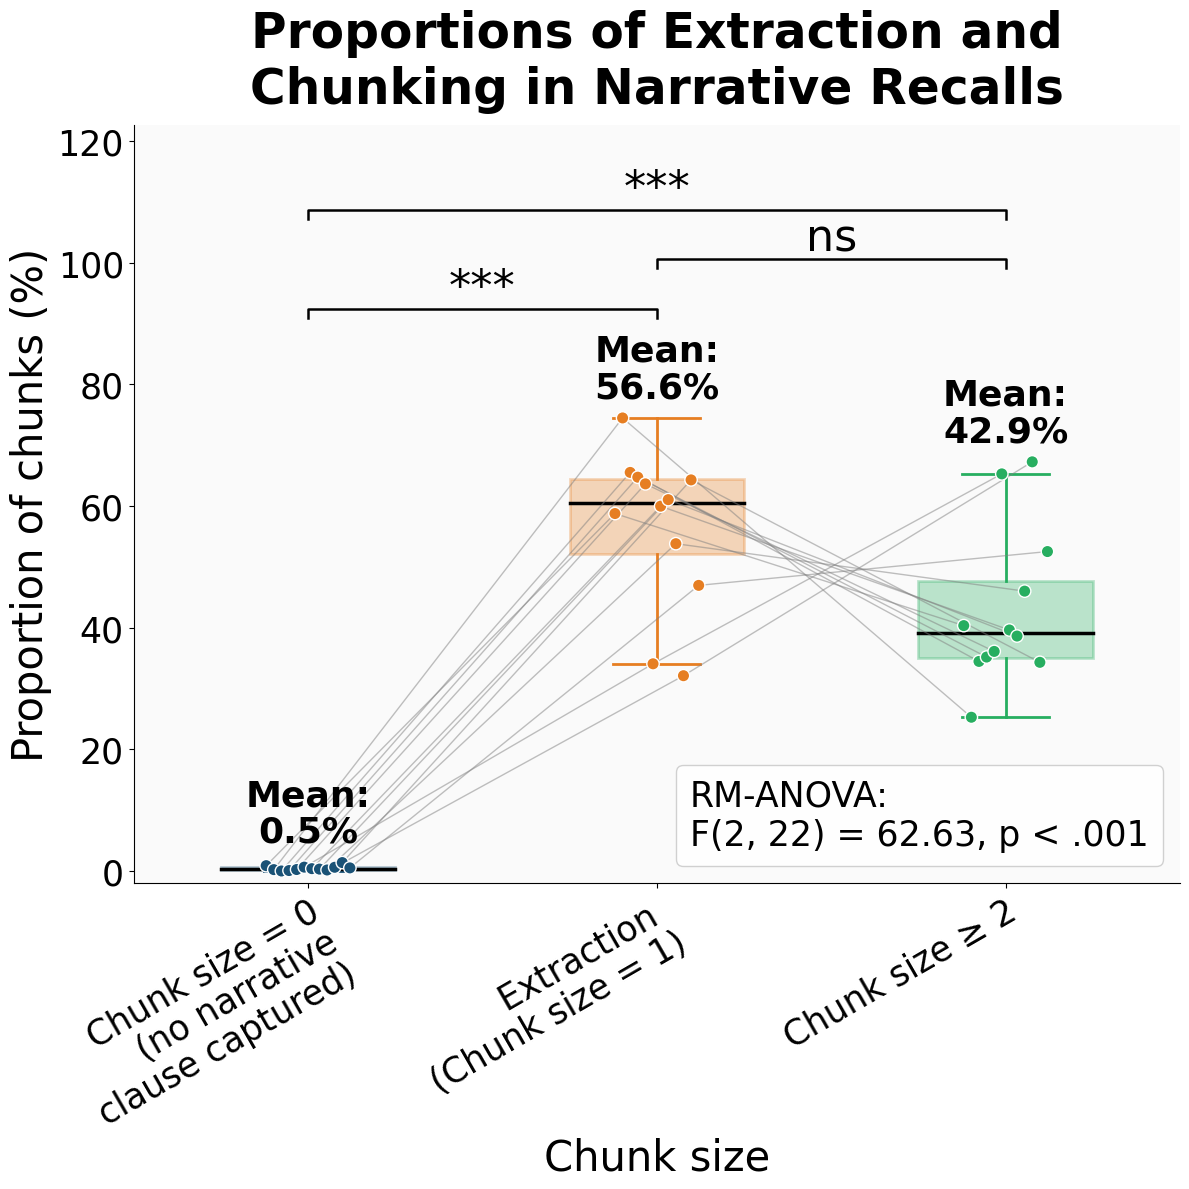

In [31]:
import numpy as np
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt
from scipy import stats as sp_stats
from matplotlib.lines import Line2D

# ── font sizes: title 35, axis labels 30, everything else >= 25 ──────────────
fs_title, fs_label, fs_xtick, fs_ytick, fs_mean, fs_legend, fs_star = 35, 30, 25, 25, 26, 25, 32

# (internal name, per-narrative proportion of chunks [0-1], color)
size_specs = [
    ("Size 0",    prop0_mean_all, '#1a5276'),
    ("Size 1",    prop1_mean_all, '#e67e22'),
    ("Size >= 2", prop2_mean_all, '#27ae60'),
]
# tick labels shown on the x-axis (same order as size_specs)
tick_labels = ["Chunk size = 0\n(no narrative\nclause captured)", "Extraction \n(Chunk size = 1)", "Chunk size ≥ 2"]

n_stories = 12
names     = [s[0] for s in size_specs]
data      = [100 * np.array(s[1][:n_stories], dtype=float) for s in size_specs]   # in %
colors    = [s[2] for s in size_specs]
positions = np.arange(len(size_specs))

# ── repeated measures ANOVA + post-hoc tests ──────────────────────────────────
df = pd.DataFrame([{'story': s, 'size': name, 'prop': d[s]}
                   for name, d in zip(names, data) for s in range(n_stories)
                   if not np.isnan(d[s])])
aov = pg.rm_anova(data=df, dv='prop', within='size', subject='story')
print(aov.to_string(index=False))

F_val, p_val = aov['F'].iloc[0], aov['p-unc'].iloc[0]
df1, df2     = aov['ddof1'].iloc[0], aov['ddof2'].iloc[0]
p_text    = "p < .001" if p_val < 0.001 else f"p = {p_val:.3f}"
aov_label = f"RM-ANOVA:\nF({df1:.0f}, {df2:.0f}) = {F_val:.2f}, {p_text}"

posthoc = pg.pairwise_tests(data=df, dv='prop', within='size',
                            subject='story', padjust='bonf', effsize='hedges')

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

posthoc['sig'] = posthoc['p-corr'].apply(add_stars)
print(posthoc[['A', 'B', 'T', 'p-unc', 'p-corr', 'sig', 'hedges']].to_string(index=False))

# ── original paired t-test: chunk size = 1 vs. chunk size >= 2 ───────────────
prop1_arr, prop2_arr = data[1], data[2]
pair_mask = ~np.isnan(prop1_arr) & ~np.isnan(prop2_arr)
t_stat, t_p = sp_stats.ttest_rel(prop1_arr[pair_mask], prop2_arr[pair_mask])
diff = prop1_arr[pair_mask] - prop2_arr[pair_mask]
cohens_d = diff.mean() / diff.std(ddof=1)
print(f"\nPaired t-test (chunk size=1 vs. size>=2), n={pair_mask.sum()}: "
      f"t={t_stat:.3f}, p={t_p:.4f}, mean diff={diff.mean():.2f} percentage points, "
      f"Cohen's d={cohens_d:.3f}")

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 12))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box, written above its highest point
y_max_all = max(np.nanmax(d) for d in data)
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.03 * y_max_all, f"Mean:\n{v.mean():.1f}%",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6, linespacing=1.1)

# dots per narrative, connected only between adjacent boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    for i in range(len(data) - 1):
        if not (np.isnan(ys[i]) or np.isnan(ys[i + 1])):
            ax.plot(xs[i:i + 2], ys[i:i + 2], color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# ── significance brackets for all pairs (Bonferroni-corrected) ────────────────
idx = {n: i for i, n in enumerate(names)}
pairs = posthoc.copy()
pairs['i'] = [min(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs['j'] = [max(idx[a], idx[b]) for a, b in zip(pairs['A'], pairs['B'])]
pairs = pairs.assign(span=pairs['j'] - pairs['i']).sort_values(['span', 'i'])

base = y_max_all * 1.24          # first bracket level, above the two-line mean labels
step = y_max_all * 0.11          # vertical distance between bracket levels
tick = y_max_all * 0.02          # length of the bracket's downward ends
levels = []
for _, row in pairs.iterrows():
    i, j = int(row['i']), int(row['j'])
    lvl = next((L for L, occ in enumerate(levels)
                if all(j < a or i > b for a, b in occ)), len(levels))
    if lvl == len(levels):
        levels.append([])
    levels[lvl].append((i - 0.1, j + 0.1))
    y = base + lvl * step
    ax.plot([i, i, j, j], [y - tick, y, y, y - tick], color='black', lw=1.8, zorder=6)
    ax.text((i + j) / 2, y, row['sig'], ha='center', va='bottom',
            fontsize=fs_star, color='black', zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, fontsize=fs_xtick, rotation=30, ha='right',
                   rotation_mode='anchor', linespacing=1.1)
ax.tick_params(axis='y', labelsize=fs_ytick)
ax.set_xlabel('Chunk size', fontsize=fs_label)
ax.set_ylabel('Proportion of chunks (%)', fontsize=fs_label)
ax.set_title('Proportions of Extraction and\nChunking in Narrative Recalls',
             fontsize=fs_title, fontweight='bold', pad=16)
ax.set_ylim(-2, base + max(len(levels), 1) * step + step * 0.7)
ax.spines[['top', 'right']].set_visible(False)

# ANOVA result as a legend, lower right
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[aov_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig("chunk_size_proportions_boxplot.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


In [15]:
for y_arr, color, label in datasets:
    mask = ~np.isnan(y_arr)
    print(f"{label}: mean prop = {y_arr[mask].mean():.4f} (n={mask.sum()})")


Chunk size = 0 (no narrative clause captured): mean prop = 0.0045 (n=12)
Chunk size = 1: mean prop = 0.5663 (n=12)
Chunk size >= 2: mean prop = 0.4292 (n=12)


#### empirical check on any shared clauses in chunks of participants - not much.

In [151]:
from collections import defaultdict

def find_largest_and_best_subset(story_chunks, min_chunk_size=2):
    """
    story_chunks: clause_dicts_all[story_index], a list of per-participant dicts
                  {recall_clause_num: [original_clause_indices]} (or None for a
                  participant whose GPT response failed to parse)

    1. Finds ALL chunk patterns tied for the LARGEST size (number of original
       clauses grouped together) that any participant actually produced --
       there can be more than one distinct pattern at that same max size.
    2. For each of those largest patterns, finds the best proper subset of it
       that was itself actually observed as a real chunk, shared by the most
       participants.
    """
    n_participants = len(story_chunks)
    pattern_participants = defaultdict(set)  # pattern -> set of participant indices who produced it

    for p_idx, recall_to_orig in enumerate(story_chunks):
        if recall_to_orig is None:
            continue
        participant_patterns = set()
        for orig_list in recall_to_orig.values():
            pattern = tuple(sorted(set(orig_list)))
            if len(pattern) >= min_chunk_size:
                participant_patterns.add(pattern)
        for pattern in participant_patterns:
            pattern_participants[pattern].add(p_idx)

    if not pattern_participants:
        return []

    max_size = max(len(pat) for pat in pattern_participants)
    largest_patterns = [pat for pat in pattern_participants if len(pat) == max_size]

    results = []
    for largest_pattern in largest_patterns:
        largest_pct = 100 * len(pattern_participants[largest_pattern]) / n_participants
        largest_set = set(largest_pattern)

        best_subset     = None
        best_subset_pct = 0.0
        for pat, p_set in pattern_participants.items():
            if pat == largest_pattern:
                continue
            if set(pat).issubset(largest_set):
                pct = 100 * len(p_set) / n_participants
                if pct > best_subset_pct:
                    best_subset_pct = pct
                    best_subset = pat

        results.append({
            'largest_pattern': largest_pattern,
            'largest_pct':      largest_pct,
            'best_subset':      best_subset,
            'best_subset_pct':  best_subset_pct,
        })

    return results


for story_index in range(12):
    story_chunks   = clause_dicts_all[story_index]
    n_participants = len(story_chunks)

    results = find_largest_and_best_subset(story_chunks, min_chunk_size=2)

    print(f"Story {story_index+1} ({n_participants} participants):")
    if not results:
        print("  No multi-clause chunk patterns found.")
    else:
        for result in results:
            print(f"  Largest chunk pattern (size {len(result['largest_pattern'])}): "
                  f"{list(result['largest_pattern'])} — {result['largest_pct']:.1f}% of participants")
            if result['best_subset'] is not None:
                print(f"    [{list(result['best_subset'])}] — {result['best_subset_pct']:.1f}% of participants")
            else:
                print("    (no shared subset of this pattern found among participants)")
    print()


Story 1 (100 participants):
  Largest chunk pattern (size 4): [9, 10, 11, 12] — 1.0% of participants
    [[11, 12]] — 4.0% of participants

Story 2 (56 participants):
  Largest chunk pattern (size 4): [1, 2, 4, 10] — 1.8% of participants
    [[1, 2]] — 1.8% of participants
  Largest chunk pattern (size 4): [1, 4, 7, 11] — 1.8% of participants
    [[4, 7]] — 1.8% of participants

Story 3 (100 participants):
  Largest chunk pattern (size 7): [5, 7, 10, 11, 12, 14, 15] — 1.0% of participants
    [[11, 12]] — 3.0% of participants

Story 4 (100 participants):
  Largest chunk pattern (size 4): [28, 29, 30, 31] — 1.0% of participants
    [[29, 30, 31]] — 3.0% of participants
  Largest chunk pattern (size 4): [29, 30, 31, 32] — 1.0% of participants
    [[29, 30, 31]] — 3.0% of participants
  Largest chunk pattern (size 4): [8, 9, 10, 11] — 1.0% of participants
    [[9, 10, 11]] — 1.0% of participants
  Largest chunk pattern (size 4): [15, 16, 19, 20] — 1.0% of participants
    [[16, 20]] — 1.0

In [152]:
for story_index in range(12):
    story_chunks   = clause_dicts_all[story_index]
    n_participants = len(story_chunks)
    clauses_text   = story_processed_all[story_index]

    results = find_largest_and_best_subset(story_chunks, min_chunk_size=2)

    print(f"Story {story_index+1} ({n_participants} participants):")
    if not results:
        print("  No multi-clause chunk patterns found.")
    else:
        for result in results:
            largest_pattern = result['largest_pattern']
            print(f"  Largest chunk pattern (size {len(largest_pattern)}): "
                  f"{list(largest_pattern)} — {result['largest_pct']:.1f}% of participants")

            if result['best_subset'] is not None:
                subset = result['best_subset']
                print(f"    {list(subset)} — {result['best_subset_pct']:.1f}% of participants")
                for idx in subset:
                    print(f"      [{idx}] {clauses_text[idx - 1]}")
            else:
                print("    (no shared subset of this pattern found among participants)")
    print()


Story 1 (100 participants):
  Largest chunk pattern (size 4): [9, 10, 11, 12] — 1.0% of participants
    [11, 12] — 4.0% of participants
      [11]  So all of them kept going. 
      [12]  They leave me. 

Story 2 (56 participants):
  Largest chunk pattern (size 4): [1, 2, 4, 10] — 1.8% of participants
    [1, 2] — 1.8% of participants
      [1]  My best friend pushed me into the pool.
      [2]  This happened during my cousin's wedding reception,
  Largest chunk pattern (size 4): [1, 4, 7, 11] — 1.8% of participants
    [4, 7] — 1.8% of participants
      [4]  And the reason it happened,
      [7]  and she tried to save me from being stung.

Story 3 (100 participants):
  Largest chunk pattern (size 7): [5, 7, 10, 11, 12, 14, 15] — 1.0% of participants
    [11, 12] — 3.0% of participants
      [11]  So that's when she snuck up behind me 
      [12]  and gave me a little nudge. 

Story 4 (100 participants):
  Largest chunk pattern (size 4): [28, 29, 30, 31] — 1.0% of participants
    [2